## Навигация по `main.ipynb`

Ниже — где что лежит. **Номера ячеек** — после вставки этого блока в самое начало (Run All идёт сверху вниз).

### Быстрый старт

| Ячейки | Содержание |
|--------|------------|
| **1** | `import pandas as pd` |
| **2** | Загрузка одного parquet в `df_1` (пример / smoke) |
| **3** | **Ядро:** загрузка всех прогонов → `df`, секции **1–5**: очистка, описательная статистика, графики по условию, тесты **incentive vs no_incentive** |
| **4–5** | **Парная разметка (vs no_inc):** средние по полям разметки для пар **no_inc vs no_inc_t1 / inc_C / inc_X** — группированные столбцы + 95% CI → `fig_pairwise_markup_*.png` |
| **6–7** | **Классификаторы по парам стимулов, отдельно по LLM:** CV AUC (LR / RF / GB) + top важностей GB; без «утекающих» предикторов → `fig_pairwise_per_model_*.png`, `pairwise_per_model_classifier_summary.csv` |
| **8–9** | **Сырые ответы:** для каждого стимула (`run_source`) — сетка эксперимент × модель, столбцы по `group_name` → `fig_raw_answers_*.png` |

### Основной анализ (последовательно)

| Ячейки | Секция | Что делается |
|--------|--------|----------------|
| **10** | 6 | Within-model сравнения |
| **11** | 7 | Within-experiment |
| **12** | 8 | Корреляции |
| **13** | 9 | Логистическая регрессия: предсказание `condition` по разметке |
| **14–15** | Парные прогоны | Markdown + код: **no_p2 vs incentive_C / incentive_X / no_t1** — столбчатые диаграммы (**2 оси**), классификаторы по разметке, CSV/`fig_pair_*`, важность признаков |
| **16–17** | SHAP / LIME | **16 страт:** стимул × эксперимент × (**kimi**, **glm**); предикторы — разметка без длин текста + `group_name`; цель — `epistemic_certainty`. Папка `shap_lime_strata/` |
| **18–19** | Стимул как предиктор | Отдельно **kimi** и **glm**: дамми `run_source` + разметка + `experiment_name` + `group_name` → `epistemic_certainty`. CSV и `fig_stimulus_predictor_*` |
| **20** | 10 | Деревья: RF, GB + важности признаков |
| **21** | 11 | ROC-кривые |
| **22–23** | 9c | Markdown + код: те же модели **отдельно по (model × experiment_name)** |
| **24** | 12–13 | Mixed-effects + анализ взаимодействия condition × model |
| **25** | 14 | Тематика / topic analysis |
| **26** | 15 | Эмоции |
| **27** | 16 | Стиль reasoning (стратегии) |
| **28** | 17 | Порядковая логистическая регрессия по ключевым исходам |
| **29** | 18 | Сводная таблица comprehensive summary |
| **30** | 19 | Список экспортированных файлов + завершение |

### Дополнительные блоки (можно после ядра)

| Ячейки | Тема |
|--------|------|
| **32** | QA: пропуски reasoning / финального ответа |
| **33–35** | Проверки покрытия разметки, ошибки API (отдельные скрипты в ячейках) |
| **37–42** | Тематическое моделирование reasoning (**STM-style**): корпус → LDA по разным K → интерпретация тем → превалентность по ковариатам; **42** — заметки по интерпретации |
| **44–46** | Просмотр случайных reasoning с фильтрами (`show_filter_options`, `show_random_reasoning`) |
| **47–48** | Распределение финальных ответов (фильтр `SOURCE_SUBSTRING`): сетка эксперимент × модель, столбчатые по `group_name` |
| **49** | Пустая ячейка-разделитель (можно игнорировать) |

### Зависимости

- **Ячейки 10–30** опираются на **`df` из ячейки 3**.
- **Ячейки 18–19** (стимул как предиктор): те же списки признаков из **3**.
- **Ячейки 16–17** (SHAP/LIME): используют те же списки признаков (`ordinal_vars_ml` для числовой разметки без `incentive_awareness_score`, `binary_vars`, `categorical_vars`), задаваемые в ячейке **3**. Переменная **`feature_cols_numeric`** создаётся в ячейке **13** (секция 9, логистическая регрессия); **ячейка 13** (парные прогоны) использует её и должна выполняться после **11**.

Если что-то не сходится с номерами, в Jupyter: *View → Show Notebook Line Numbers* не даёт индекс ячейки — ориентируйтесь по заголовкам `print("…")` в коде или по markdown-заголовкам ниже.





In [23]:
import pandas as pd

In [24]:
df_1 = pd.read_parquet(
    'attitude/runs/incentive_C_balanced_realism_50_reasoning_trace/responses_final_incentive_C_balanced_realism_50_reasoning_trace_markup.parquet'
)

1. LOADING DATA
Incentive rows    : 2,800 (incentive_C + incentive_X)
No-incentive rows : 2,800 (no_p2 + no_t1)
Combined rows     : 5,600

Rows by run_source:
run_source
incentive_C    1400
incentive_X    1400
no_p2          1400
no_t1          1400

Models           : ['moonshotai/kimi-k2-thinking', 'z-ai/glm-4.6', 'qwen/qwen3.5-9b', 'minimax/minimax-m2.5']
Experiments      : 2

2. DATA CLEANING & FEATURE ENGINEERING

Missing values in analysis variables:
treatment_awareness_score                        1045
incentive_awareness_score                        1045
epistemic_certainty                              1045
social_desirability_normative_orientation        1045
social_desirability_fear_of_judgment             1045
social_desirability_safe_answer_shift            1045
role_adherence_role_immersion                    1045
reasoning_style_internal_conflict                1045
role_adherence_ai_leakage                        1045
epistemic_assumptions_hallucinated_conditions    1045

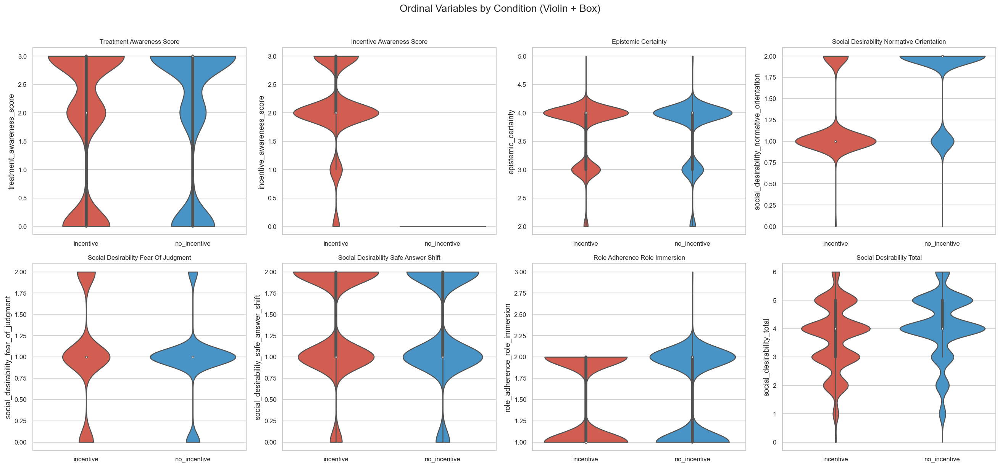

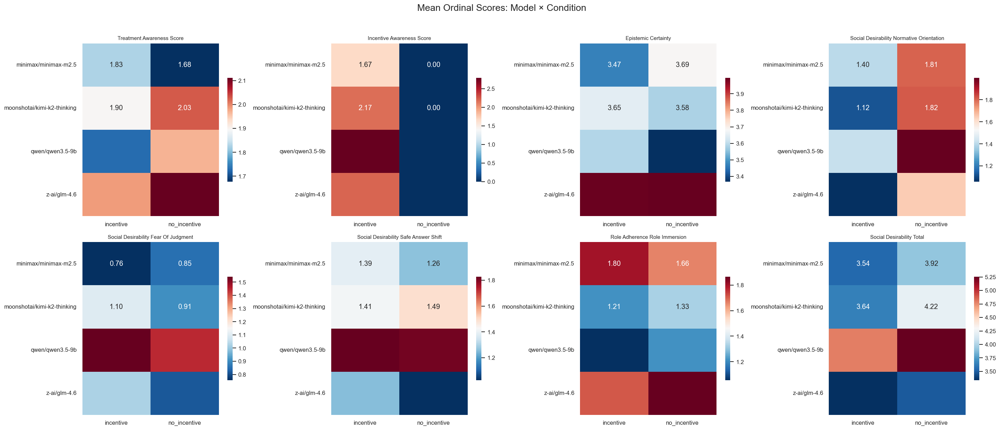

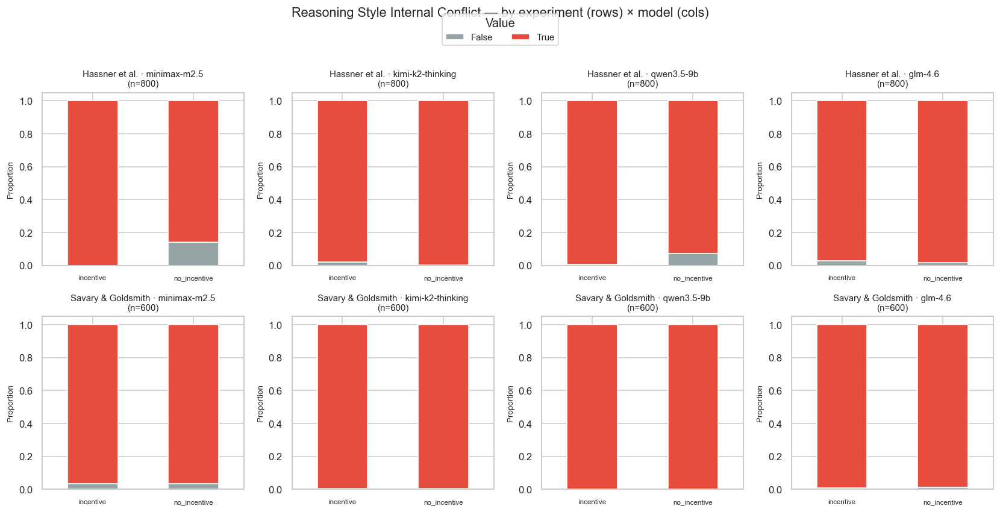

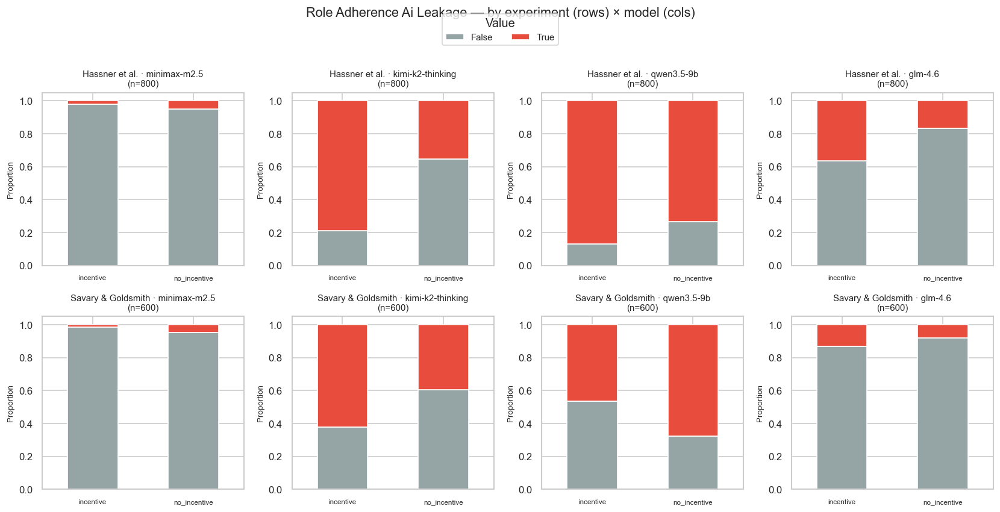

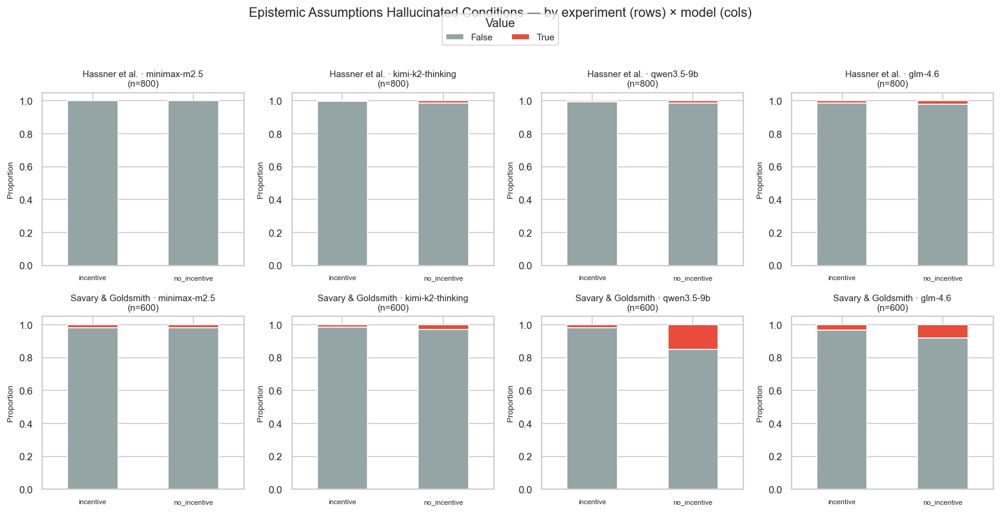

...

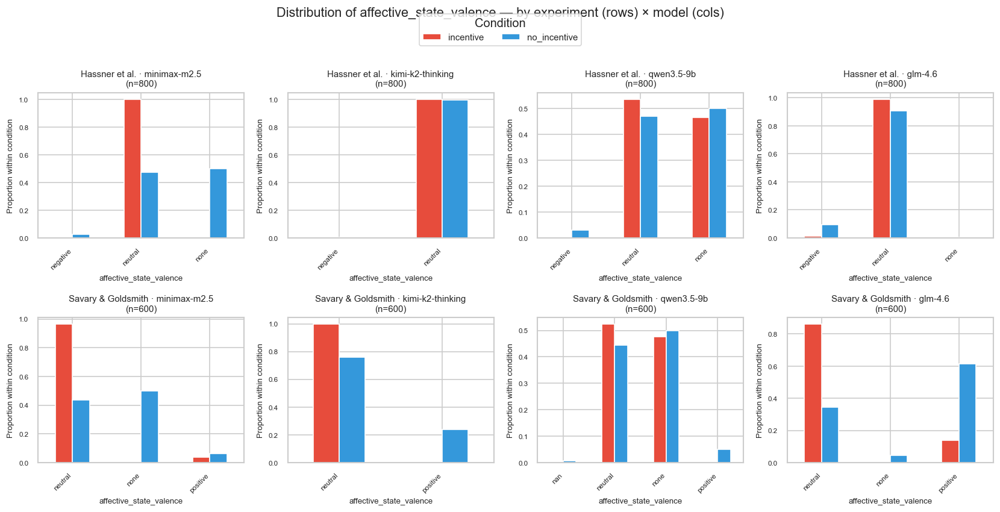

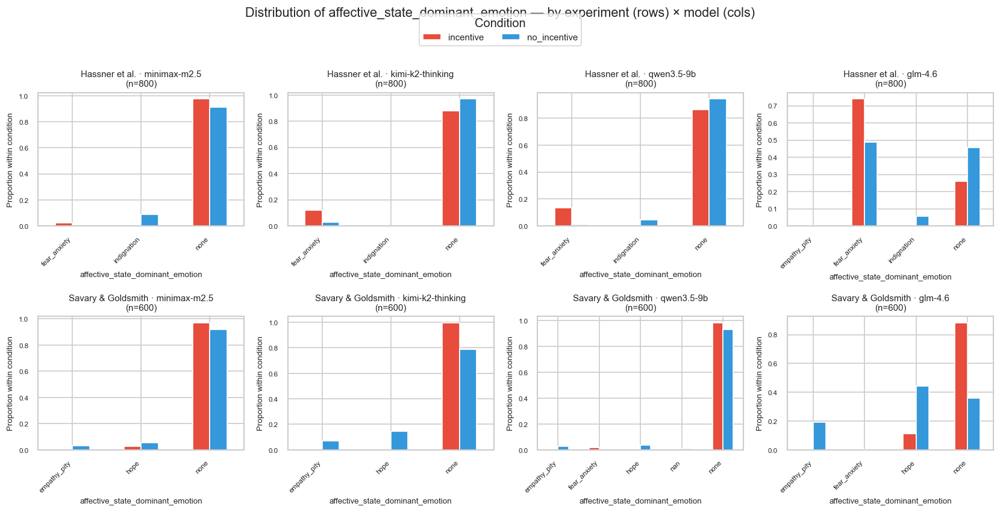

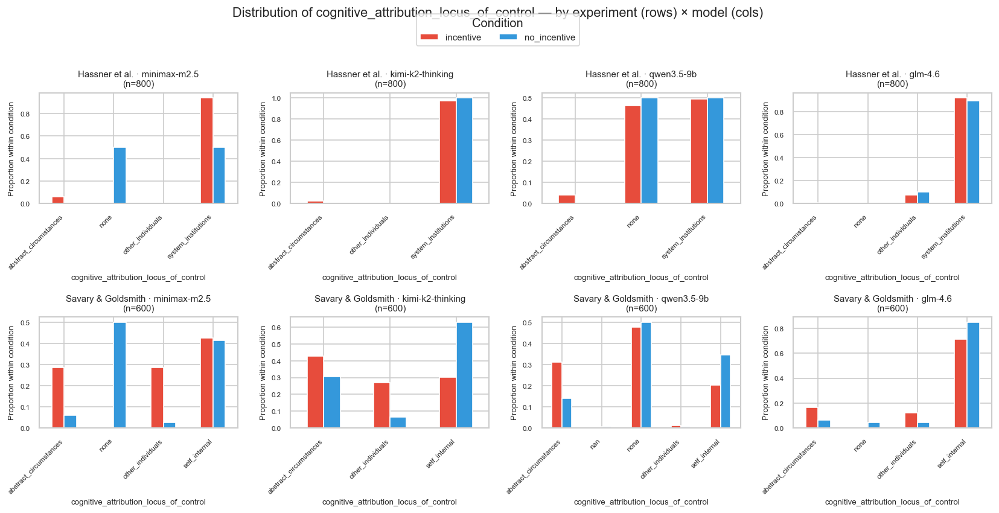

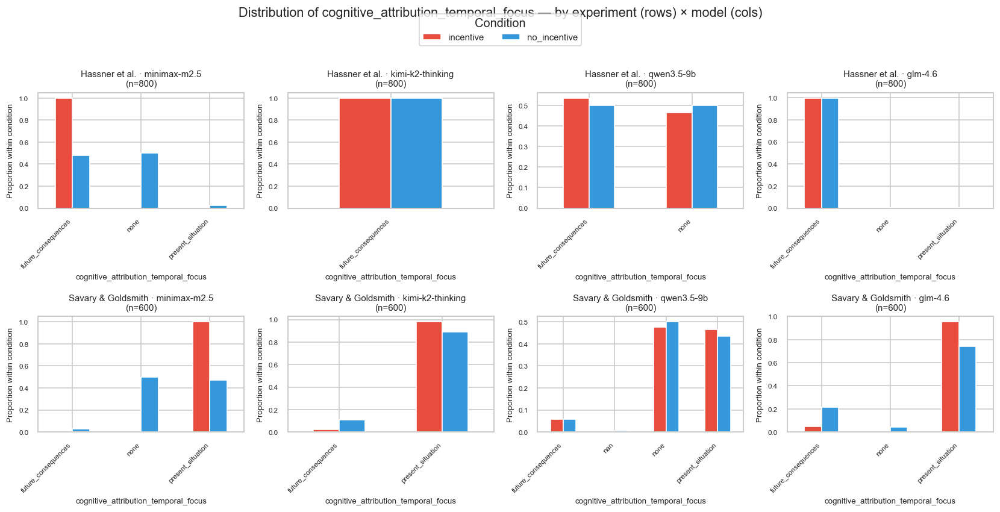

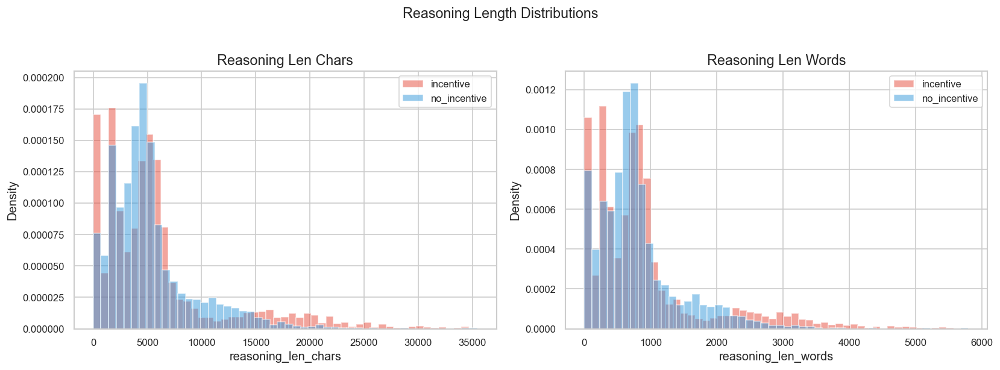


5. STATISTICAL TESTS: INCENTIVE vs NO-INCENTIVE

--- Mann-Whitney U tests (ordinal) ---
  treatment_awareness_score                           U=     2405586  p=0.000030 ***  r=+0.066  mean_inc=1.877  mean_no=1.986
  incentive_awareness_score                           U=     5037360  p=0.000000 ***  r=-0.956  mean_inc=2.130  mean_no=0.000
  epistemic_certainty                                 U=     2513368  p=0.072553      r=+0.024  mean_inc=3.686  mean_no=3.700
  social_desirability_normative_orientation           U=     1142975  p=0.000000 ***  r=+0.556  mean_inc=1.228  mean_no=1.788
  social_desirability_fear_of_judgment                U=     2768246  p=0.000000 ***  r=-0.075  mean_inc=1.047  mean_no=0.958
  social_desirability_safe_answer_shift               U=     2727336  p=0.000119 ***  r=-0.059  mean_inc=1.423  mean_no=1.353
  role_adherence_role_immersion                       U=     2459210  p=0.002503 **   r=+0.045  mean_inc=1.497  mean_no=1.543
  social_desirability_total  

In [25]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, spearmanr
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.inspection import permutation_importance
import textwrap
from itertools import combinations

# Plotting defaults
plt.rcParams.update({
    "figure.figsize": (14, 7),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 120,
})
palette_condition = {"incentive": "#e74c3c", "no_incentive": "#3498db"}

# =============================================================================
# 1. LOAD & UNIFY DATA
# =============================================================================
print("=" * 80)
print("1. LOADING DATA")
print("=" * 80)

_RUN_SPECS = [
    ("incentive_C", "incentive",
     "attitude/runs/incentive_C_balanced_realism_50_reasoning_trace/responses_final_incentive_C_balanced_realism_50_reasoning_trace_markup.parquet",
     "parquet"),
    ("no_p2", "no_incentive",
     "attitude/runs/no_incentive_50_reasoning_trace_p2/responses_final_no_incentive_50_reasoning_trace_p2_markup.parquet",
     "parquet"),
    ("incentive_X", "incentive",
     "attitude/runs/incentive_X/responses_final_X_markup.parquet",
     "parquet"),
    ("no_t1", "no_incentive",
     "attitude/runs/no_incentive_50_reasoning_trace_t1/responses_final_no_incentive_50_reasoning_trace_t1_markup.csv",
     "csv"),
]

_parts = []
for key, cond, path, kind in _RUN_SPECS:
    if kind == "parquet":
        chunk = pd.read_parquet(path)
    else:
        chunk = pd.read_csv(path)
    chunk = chunk.copy()
    chunk["run_source"] = key
    chunk["condition"] = cond
    chunk["source_file"] = "/".join(path.split("/")[-2:])
    _parts.append(chunk)

df = pd.concat(_parts, ignore_index=True)
df_inc = df[df["condition"] == "incentive"].copy()
df_no = df[df["condition"] == "no_incentive"].copy()

print(f"Incentive rows    : {len(df_inc):,} (incentive_C + incentive_X)")
print(f"No-incentive rows : {len(df_no):,} (no_p2 + no_t1)")
print(f"Combined rows     : {len(df):,}")
print("\nRows by run_source:")
print(df.groupby("run_source").size().to_string())
print(f"\nModels           : {df['model'].unique().tolist()}")
print(f"Experiments      : {df['experiment_name'].nunique()}")

# =============================================================================
# 2. DATA CLEANING & FEATURE ENGINEERING
# =============================================================================
print("\n" + "=" * 80)
print("2. DATA CLEANING & FEATURE ENGINEERING")
print("=" * 80)

# ── 2a. Определим все аналитические переменные ──
ordinal_vars = [
    "treatment_awareness_score",
    "incentive_awareness_score",
    "epistemic_certainty",
    "social_desirability_normative_orientation",
    "social_desirability_fear_of_judgment",
    "social_desirability_safe_answer_shift",
    "role_adherence_role_immersion",
]

# Для моделей, предсказывающих condition (incentive vs no_incentive), не используем
# incentive_awareness_score — он почти по определению совпадает с назначением условия.
ordinal_vars_ml = [c for c in ordinal_vars if c != "incentive_awareness_score"]

binary_vars = [
    "reasoning_style_internal_conflict",
    "role_adherence_ai_leakage",
    "epistemic_assumptions_hallucinated_conditions",
]

categorical_vars = [
    "reasoning_style_primary_strategy",
    "affective_state_valence",
    "affective_state_dominant_emotion",
    "cognitive_attribution_locus_of_control",
    "cognitive_attribution_temporal_focus",
]

# ── 2b. Convert types ──
for col in ordinal_vars:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in binary_vars:
    # handle True/False, 'true'/'false', 1/0
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": 1, "false": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
    )

for col in categorical_vars:
    df[col] = df[col].astype(str).str.strip().str.lower()

# ── 2c. Composite scores ──
df["social_desirability_total"] = (
    df["social_desirability_normative_orientation"]
    + df["social_desirability_fear_of_judgment"]
    + df["social_desirability_safe_answer_shift"]
)

# ── 2d. Quick missing-value report ──
all_analysis_vars = ordinal_vars + binary_vars + categorical_vars + ["social_desirability_total"]
print("\nMissing values in analysis variables:")
print(df[all_analysis_vars].isnull().sum().to_string())

# ── 2e. Reasoning length features ──
df["reasoning_len_chars"] = df["REASONING"].astype(str).apply(len)
df["reasoning_len_words"] = df["REASONING"].astype(str).apply(lambda x: len(x.split()))

print(f"\nFinal dataframe shape: {df.shape}")

# =============================================================================
# 3. DESCRIPTIVE STATISTICS
# =============================================================================
print("\n" + "=" * 80)
print("3. DESCRIPTIVE STATISTICS")
print("=" * 80)

# ── 3a. Condition-level summary for ordinal + binary ──
desc_vars = ordinal_vars + binary_vars + ["social_desirability_total",
                                           "reasoning_len_chars", "reasoning_len_words"]

desc_by_cond = df.groupby("condition")[desc_vars].agg(["mean", "std", "median", "count"])
print("\n--- Descriptive stats by CONDITION ---")
print(desc_by_cond.round(3).to_string())

# ── 3b. Condition × Model ──
desc_by_cond_model = (
    df.groupby(["condition", "model"])[desc_vars]
    .agg(["mean", "std", "count"])
)
print("\n--- Descriptive stats by CONDITION × MODEL ---")
print(desc_by_cond_model.round(3).to_string())

# ── 3c. Frequency tables for categorical vars ──
for col in categorical_vars:
    print(f"\n--- {col} frequencies ---")
    ct = pd.crosstab(df["condition"], df[col], margins=True, normalize="index")
    print(ct.round(3).to_string())


# =============================================================================
# 4. VISUALIZATION: OVERVIEW DASHBOARDS
# =============================================================================
print("\n" + "=" * 80)
print("4. GENERATING VISUALIZATIONS")
print("=" * 80)

# ── 4a. Ordinal variables: violin + box by condition ──
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()
plot_vars = ordinal_vars + ["social_desirability_total"]
for i, var in enumerate(plot_vars):
    ax = axes[i]
    sns.violinplot(
        data=df, x="condition", y=var, palette=palette_condition,
        inner="box", cut=0, ax=ax
    )
    ax.set_title(var.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("")
for j in range(len(plot_vars), len(axes)):
    axes[j].set_visible(False)
fig.suptitle("Ordinal Variables by Condition (Violin + Box)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("fig_01_ordinal_violin_by_condition.png", bbox_inches="tight")
plt.show()

# ── 4b. Ordinal by condition × model (heatmap of means) ──
fig, axes = plt.subplots(2, 4, figsize=(24, 10))
axes = axes.flatten()
for i, var in enumerate(plot_vars):
    ax = axes[i]
    pivot = df.pivot_table(values=var, index="model", columns="condition", aggfunc="mean")
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdBu_r", ax=ax, cbar_kws={"shrink": 0.6})
    ax.set_title(var.replace("_", " ").title(), fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
for j in range(len(plot_vars), len(axes)):
    axes[j].set_visible(False)
fig.suptitle("Mean Ordinal Scores: Model × Condition", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("fig_02_ordinal_heatmap_model_condition.png", bbox_inches="tight")
plt.show()

# Shared facet axes for 4c–4d (experiment × model)


def _short_exp_title_cat(name):
    s = str(name)
    if "Hassner" in s:
        return "Hassner et al."
    if "Savary" in s or "Goldsmith" in s:
        return "Savary & Goldsmith"
    return (s[:42] + "…") if len(s) > 42 else s


def _short_model_cat(m):
    m = str(m)
    return m.split("/")[-1] if "/" in m else m


experiments_cat = sorted(df["experiment_name"].dropna().astype(str).unique())
models_cat = sorted(df["model"].dropna().astype(str).unique())

# ── 4c. Binary variables: stacked bars — facet experiment × model ──
_bin_colors = ["#95a5a6", "#e74c3c"]

for var in binary_vars:
    n_exp, n_mod = len(experiments_cat), len(models_cat)
    fig, axes = plt.subplots(
        n_exp,
        n_mod,
        figsize=(max(14, 3.0 * n_mod), max(7, 2.7 * n_exp)),
        squeeze=False,
    )
    for i, exp in enumerate(experiments_cat):
        for j, model in enumerate(models_cat):
            ax = axes[i][j]
            sub = df[
                (df["experiment_name"].astype(str) == exp)
                & (df["model"].astype(str) == model)
            ]
            n_sub = len(sub)
            if n_sub == 0:
                ax.set_visible(False)
                continue
            ct = pd.crosstab(sub["condition"], sub[var], normalize="index")
            if ct.shape == (0, 0) or len(ct.index) == 0:
                ax.set_visible(False)
                continue
            for b in (0, 1):
                if b not in ct.columns:
                    ct[b] = 0.0
            ct = ct[[0, 1]]
            ct = ct.reindex(index=list(palette_condition.keys()), fill_value=0)
            ct.plot(
                kind="bar",
                stacked=True,
                ax=ax,
                color=_bin_colors[: ct.shape[1]],
                edgecolor="white",
                legend=False,
            )
            ax.set_title(
                f"{_short_exp_title_cat(exp)} · {_short_model_cat(model)}\n(n={n_sub})",
                fontsize=9,
            )
            ax.set_ylabel("Proportion", fontsize=8)
            ax.set_xlabel("")
            ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=7)
    fig.suptitle(
        f"{var.replace('_', ' ').title()} — by experiment (rows) × model (cols)",
        fontsize=13,
        y=1.01,
    )
    fig.legend(
        [plt.Rectangle((0, 0), 1, 1, fc=c, ec="white") for c in _bin_colors],
        ["False", "True"],
        title="Value",
        loc="upper center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.005),
        frameon=True,
        fontsize=9,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(f"fig_03_binary_{var}.png", bbox_inches="tight")
    plt.show()

# ── 4d. Categorical: grouped bar plots — facet experiment × model (not pooled) ──

for col in categorical_vars:
    n_exp, n_mod = len(experiments_cat), len(models_cat)
    fig, axes = plt.subplots(
        n_exp,
        n_mod,
        figsize=(max(14, 3.0 * n_mod), max(7, 2.7 * n_exp)),
        squeeze=False,
    )
    for i, exp in enumerate(experiments_cat):
        for j, model in enumerate(models_cat):
            ax = axes[i][j]
            sub = df[
                (df["experiment_name"].astype(str) == exp)
                & (df["model"].astype(str) == model)
            ]
            n_sub = len(sub)
            if n_sub == 0:
                ax.set_visible(False)
                continue
            ct = pd.crosstab(sub[col], sub["condition"], normalize="columns")
            ct = ct.reindex(columns=list(palette_condition.keys()), fill_value=0)
            cols_order = list(palette_condition.keys())
            ct.plot(
                kind="bar",
                ax=ax,
                color=[palette_condition[c] for c in cols_order],
                edgecolor="white",
                legend=False,
            )
            ax.set_title(
                f"{_short_exp_title_cat(exp)} · {_short_model_cat(model)}\n(n={n_sub})",
                fontsize=9,
            )
            ax.set_ylabel("Proportion within condition", fontsize=8)
            ax.set_xlabel(col, fontsize=8)
            ax.tick_params(axis="x", labelsize=7)
            ax.tick_params(axis="y", labelsize=7)
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fig.suptitle(
        f"Distribution of {col} — by experiment (rows) × model (cols)",
        fontsize=13,
        y=1.01,
    )
    handles = [
        plt.Rectangle((0, 0), 1, 1, fc=palette_condition[k], ec="white")
        for k in palette_condition.keys()
    ]
    fig.legend(
        handles,
        list(palette_condition.keys()),
        title="Condition",
        loc="upper center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.005),
        frameon=True,
        fontsize=9,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fname = f"fig_04_categorical_{col}.png"
    plt.savefig(fname, bbox_inches="tight")
    plt.show()

# ── 4e. Reasoning length distributions ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, lvar in enumerate(["reasoning_len_chars", "reasoning_len_words"]):
    ax = axes[i]
    for cond, color in palette_condition.items():
        subset = df[df["condition"] == cond][lvar].dropna()
        ax.hist(subset, bins=50, alpha=0.5, label=cond, color=color, density=True)
    ax.set_title(lvar.replace("_", " ").title())
    ax.set_xlabel(lvar)
    ax.set_ylabel("Density")
    ax.legend()
plt.suptitle("Reasoning Length Distributions", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_05_reasoning_length.png", bbox_inches="tight")
plt.show()


# =============================================================================
# 5. STATISTICAL TESTS: CONDITION EFFECT (INCENTIVE vs NO-INCENTIVE)
# =============================================================================
print("\n" + "=" * 80)
print("5. STATISTICAL TESTS: INCENTIVE vs NO-INCENTIVE")
print("=" * 80)

results_tests = []

# ── 5a. Mann-Whitney U for ordinal vars ──
print("\n--- Mann-Whitney U tests (ordinal) ---")
for var in ordinal_vars + ["social_desirability_total", "reasoning_len_words"]:
    g1 = df.loc[df["condition"] == "incentive", var].dropna()
    g2 = df.loc[df["condition"] == "no_incentive", var].dropna()
    stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
    # Effect size: rank-biserial r
    n1, n2 = len(g1), len(g2)
    r_effect = 1 - (2 * stat) / (n1 * n2)
    results_tests.append({
        "variable": var, "test": "Mann-Whitney U",
        "stat": stat, "p_value": p, "effect_size_r": r_effect,
        "n_inc": n1, "n_no": n2,
        "mean_inc": g1.mean(), "mean_no": g2.mean()
    })
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {var:50s}  U={stat:12.0f}  p={p:.6f} {sig:3s}  r={r_effect:+.3f}  "
          f"mean_inc={g1.mean():.3f}  mean_no={g2.mean():.3f}")

# ── 5b. Chi-squared for binary vars ──
print("\n--- Chi-squared tests (binary) ---")
for var in binary_vars:
    ct = pd.crosstab(df["condition"], df[var].fillna(-1))
    if -1 in ct.columns:
        ct = ct.drop(columns=[-1])
    if ct.shape[1] < 2:
        print(f"  {var}: skipped (no variance)")
        continue
    chi2, p, dof, expected = chi2_contingency(ct)
    # Cramér's V
    n = ct.sum().sum()
    k = min(ct.shape)
    cramers_v = np.sqrt(chi2 / (n * (k - 1))) if (n * (k - 1)) > 0 else 0
    results_tests.append({
        "variable": var, "test": "Chi-squared",
        "stat": chi2, "p_value": p, "effect_size_r": cramers_v,
        "n_inc": len(df[df["condition"] == "incentive"]),
        "n_no": len(df[df["condition"] == "no_incentive"]),
        "mean_inc": df.loc[df["condition"] == "incentive", var].mean(),
        "mean_no": df.loc[df["condition"] == "no_incentive", var].mean()
    })
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {var:50s}  χ²={chi2:10.3f}  p={p:.6f} {sig:3s}  V={cramers_v:.3f}  "
          f"prop_inc={df.loc[df['condition']=='incentive', var].mean():.3f}  "
          f"prop_no={df.loc[df['condition']=='no_incentive', var].mean():.3f}")

# ── 5c. Chi-squared for categorical vars ──
print("\n--- Chi-squared tests (categorical) ---")
for var in categorical_vars:
    ct = pd.crosstab(df["condition"], df[var])
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.sum().sum()
    k = min(ct.shape)
    cramers_v = np.sqrt(chi2 / (n * (k - 1))) if (n * (k - 1)) > 0 else 0
    results_tests.append({
        "variable": var, "test": "Chi-squared",
        "stat": chi2, "p_value": p, "effect_size_r": cramers_v,
        "n_inc": len(df[df["condition"] == "incentive"]),
        "n_no": len(df[df["condition"] == "no_incentive"]),
        "mean_inc": np.nan, "mean_no": np.nan
    })
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {var:50s}  χ²={chi2:10.3f}  p={p:.6f} {sig:3s}  V={cramers_v:.3f}")

# ── 5d. Multiple testing correction ──
df_tests = pd.DataFrame(results_tests)
reject, p_adj, _, _ = multipletests(df_tests["p_value"], method="fdr_bh")
df_tests["p_adjusted_fdr"] = p_adj
df_tests["significant_fdr05"] = reject

print("\n--- All tests with FDR correction ---")
print(df_tests.to_string(index=False))
df_tests.to_csv("statistical_tests_summary.csv", index=False)

### Парные сравнения разметки по стимулам (vs базовый `no_inc`)

Средние по **числовым полям разметки** (`ordinal_vars`, `binary_vars`, `social_desirability_total`, в т.ч. **`incentive_awareness_score`**) для пар:

- **no_inc** (`no_p2`) vs **no_inc_t1** (`no_t1`)
- **no_inc** (`no_p2`) vs **inc_C** (`incentive_C`)
- **no_inc** (`no_p2`) vs **inc_X** (`incentive_X`)

Каждая фигура — сетка **2×2**: **верхний ряд** — средние по двум стимулам (**95% CI**), столбцы рядом; **нижний ряд** — **Cohen's d** по той же шкале категорий (отдельная ось Y, ноль по центру). Колонки — два **`experiment_name`**. Подписи категорий — внизу, сокращённые (**SD**, **RS**, …). Легенда справа от области графика. **Звёздочки** над столбцами d: **Welch t-test** (* / ** / ***).


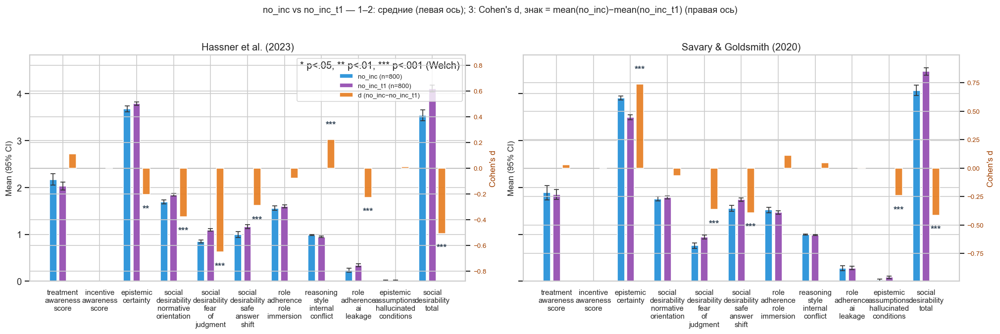

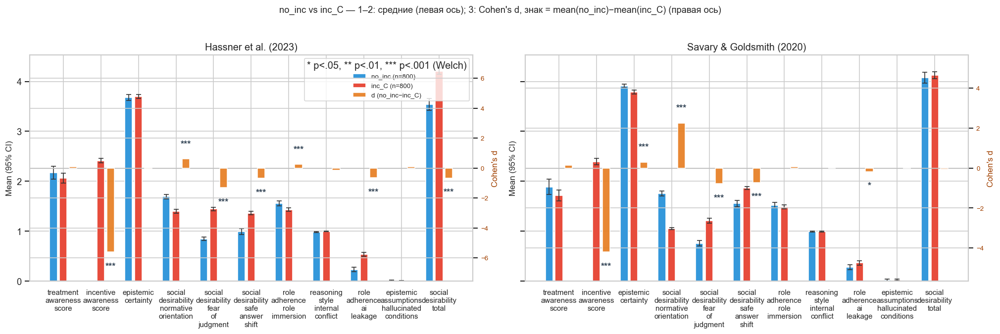

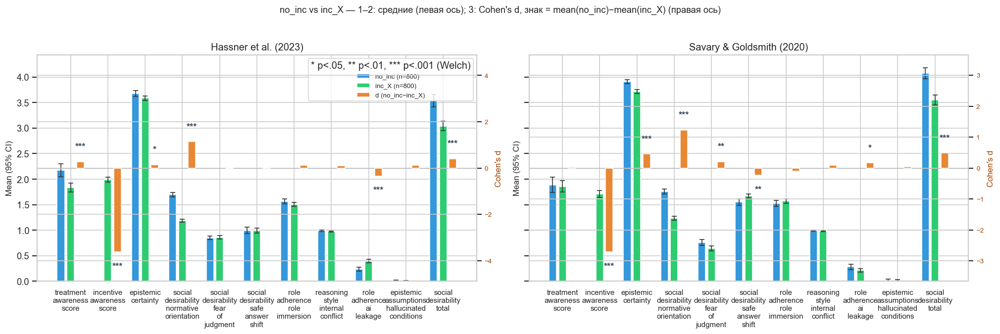

Готово: fig_pairwise_markup_*.png


In [57]:
# Парные сравнения разметки: no_inc vs no_inc_t1 / inc_C / inc_X
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

if "df" not in globals():
    raise RuntimeError("Сначала выполни ячейку загрузки данных (df, ordinal_vars, binary_vars).")

RS_MAP = {
    "no_inc": "no_p2",
    "no_inc_t1": "no_t1",
    "inc_C": "incentive_C",
    "inc_X": "incentive_X",
}
RS_LABEL = {
    "no_p2": "no_inc",
    "no_t1": "no_inc_t1",
    "incentive_C": "inc_C",
    "incentive_X": "inc_X",
}

# Столбчатые диаграммы: полный список ordinal (включая incentive_awareness_score).
markup_cols = [c for c in (ordinal_vars + binary_vars + ["social_desirability_total"]) if c in df.columns]

PAIRS = [
    ("no_inc", "no_inc_t1", "no_inc vs no_inc_t1"),
    ("no_inc", "inc_C", "no_inc vs inc_C"),
    ("no_inc", "inc_X", "no_inc vs inc_X"),
]


def _mean_ci(x: pd.Series):
    x = pd.to_numeric(x, errors="coerce").dropna()
    n = len(x)
    if n == 0:
        return np.nan, np.nan, np.nan, 0
    m = float(x.mean())
    se = float(x.std(ddof=1) / np.sqrt(n)) if n > 1 else 0.0
    return m, m - 1.96 * se, m + 1.96 * se, n


def _cohen_d_and_p(va: pd.Series, vb: pd.Series):
    """Cohen's d (объединённый SD) и p-value (Welch t-test). Знак: mean(rs_a) − mean(rs_b)."""
    a = pd.to_numeric(va, errors="coerce").dropna().to_numpy(dtype=float)
    b = pd.to_numeric(vb, errors="coerce").dropna().to_numpy(dtype=float)
    n1, n2 = len(a), len(b)
    if n1 < 2 or n2 < 2:
        return np.nan, np.nan
    m1, m2 = float(np.mean(a)), float(np.mean(b))
    v1 = float(np.var(a, ddof=1))
    v2 = float(np.var(b, ddof=1))
    pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / max(n1 + n2 - 2, 1))
    if not np.isfinite(pooled) or pooled < 1e-15:
        d = 0.0 if abs(m1 - m2) < 1e-15 else np.nan
    else:
        d = (m1 - m2) / pooled
    try:
        t_res = ttest_ind(a, b, equal_var=False, nan_policy="omit")
        pval = float(t_res.pvalue)
    except Exception:
        pval = np.nan
    if not np.isfinite(pval):
        pval = np.nan
    return d, pval


def _p_to_stars(p):
    if p is None or not np.isfinite(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def _short_exp_title(name):
    s = str(name)
    if "Hassner" in s:
        return "Hassner et al. (2023)"
    if "Savary" in s or "Goldsmith" in s:
        return "Savary & Goldsmith (2020)"
    return (s[:44] + "…") if len(s) > 44 else s


def _x_labels_compact(names):
    """Короче подписи по X, чтобы не наезжали."""
    out = []
    for raw in names:
        s = raw.replace("_", " ")
        s = s.replace("social desirability", "SD")
        s = s.replace("reasoning style", "RS")
        s = s.replace("role adherence", "RA")
        s = s.replace("epistemic assumptions", "EA")
        if len(s) > 34:
            s = s[:32].rstrip() + "…"
        out.append(s)
    return out


sns.set_theme(style="whitegrid", context="notebook")

for key_a, key_b, title in PAIRS:
    rs_a, rs_b = RS_MAP[key_a], RS_MAP[key_b]
    sub = df[df["run_source"].isin([rs_a, rs_b])].copy()
    if sub.empty:
        print(f"[skip] нет данных для {title}")
        continue

    experiments = sorted(sub["experiment_name"].dropna().astype(str).unique())
    if not experiments:
        print(f"[skip] нет experiment_name для {title}")
        continue
    if len(experiments) > 2:
        print(
            f"Warning [{title}]: экспериментов {len(experiments)}, на панелях — первые два (по sorted)."
        )
    exp_panels = list(experiments[:2])
    while len(exp_panels) < 2:
        exp_panels.append(None)

    x_labels = _x_labels_compact([c.replace("_", " ") for c in markup_cols])
    n_cat = len(markup_cols)
    fig_w = max(13.0, 0.52 * n_cat + 4.0)
    fig_h = max(9.0, 0.22 * n_cat + 6.5)

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(fig_w, fig_h),
        sharex="col",
        sharey="row",
        height_ratios=[1.75, 1.0],
        gridspec_kw={"hspace": 0.14, "wspace": 0.22},
    )

    colors = {
        "no_inc": "#3498db",
        "no_inc_t1": "#9b59b6",
        "inc_C": "#e74c3c",
        "inc_X": "#2ecc71",
    }
    x = np.arange(n_cat)
    bw = 0.32
    x_pair = np.array([-0.16, 0.16])

    ymax_mean_upper = 0.0
    handles_for_legend = None
    labels_for_legend = None

    for j, exp in enumerate(exp_panels):
        ax_top = axes[0, j]
        ax_bot = axes[1, j]
        if exp is None:
            ax_top.set_visible(False)
            ax_bot.set_visible(False)
            continue

        sub_e = sub[sub["experiment_name"].astype(str) == str(exp)]
        n_a = int((sub_e["run_source"] == rs_a).sum())
        n_b = int((sub_e["run_source"] == rs_b).sum())
        if sub_e.empty or (n_a == 0 and n_b == 0):
            ax_top.text(
                0.5,
                0.55,
                "нет данных",
                ha="center",
                va="center",
                transform=ax_top.transAxes,
                fontsize=11,
            )
            ax_bot.set_visible(False)
            ax_top.set_title(_short_exp_title(exp), fontsize=12, fontweight="semibold")
            ax_top.set_xticks(x)
            ax_top.set_xticklabels([])
            continue

        lbl_a, lbl_b = RS_LABEL[rs_a], RS_LABEL[rs_b]

        for i, rs in enumerate([rs_a, rs_b]):
            lbl = RS_LABEL[rs]
            n_here = n_a if rs == rs_a else n_b
            means = []
            yerr = [[], []]
            for col in markup_cols:
                m, lo, hi, _nn = _mean_ci(sub_e.loc[sub_e["run_source"] == rs, col])
                if not np.isfinite(m):
                    means.append(0.0)
                    yerr[0].append(0.0)
                    yerr[1].append(0.0)
                else:
                    means.append(m)
                    yerr[0].append(max(0.0, m - lo) if np.isfinite(lo) else 0.0)
                    yerr[1].append(max(0.0, hi - m) if np.isfinite(hi) else 0.0)
                    upper = hi if np.isfinite(hi) else m + yerr[1][-1]
                    ymax_mean_upper = max(ymax_mean_upper, float(upper))
            leg_lbl = f"{lbl} (n={n_here})"
            ax_top.bar(
                x + x_pair[i],
                means,
                width=bw,
                label=leg_lbl,
                color=colors.get(lbl, "#34495e"),
                edgecolor="white",
                linewidth=0.6,
                yerr=yerr,
                capsize=2.5,
                error_kw={"linewidth": 0.9, "ecolor": "#333333"},
                zorder=3,
            )

        if handles_for_legend is None:
            handles_for_legend, labels_for_legend = ax_top.get_legend_handles_labels()

        ds = []
        ps = []
        for col in markup_cols:
            va = sub_e.loc[sub_e["run_source"] == rs_a, col]
            vb = sub_e.loc[sub_e["run_source"] == rs_b, col]
            d, p = _cohen_d_and_p(va, vb)
            ds.append(d)
            ps.append(p)

        heights = []
        for v in ds:
            if v is not None and np.isfinite(v):
                heights.append(float(v))
            else:
                heights.append(0.0)

        d_width = 0.62
        ax_bot.bar(
            x,
            heights,
            width=d_width,
            label=f"Cohen's d ({lbl_a}−{lbl_b})",
            color="#e67e22",
            edgecolor="white",
            linewidth=0.6,
            zorder=3,
            alpha=0.95,
        )

        finite_d = [float(v) for v in ds if v is not None and np.isfinite(v)]
        lim = max(0.45, float(np.nanmax(np.abs(finite_d))) * 1.4) if len(finite_d) else 0.75
        ax_bot.set_ylim(-lim, lim)
        ax_bot.axhline(0, color="#95a5a6", linewidth=1.0, zorder=1)
        ax_bot.tick_params(axis="y", labelsize=9, labelcolor="#a04000")

        ylo, yhi = ax_bot.get_ylim()
        yspan = yhi - ylo
        for jj, (dj, pj) in enumerate(zip(ds, ps)):
            st = _p_to_stars(pj)
            if not st or dj is None or not np.isfinite(dj):
                continue
            ytxt = float(dj) + (0.05 * yspan if dj >= 0 else -0.05 * yspan)
            ax_bot.text(
                x[jj],
                ytxt,
                st,
                ha="center",
                va="bottom" if dj >= 0 else "top",
                fontsize=10,
                fontweight="bold",
                color="#1a1a1a",
                zorder=5,
            )

        ax_top.set_xticks(x)
        ax_top.set_xticklabels([])
        ax_top.set_title(_short_exp_title(exp), fontsize=12, fontweight="semibold", pad=8)
        ax_top.axhline(0, color="#cccccc", linewidth=0.8, zorder=0)
        ax_top.set_ylabel("Mean (95% CI)" if j == 0 else "", fontsize=11)
        ax_top.tick_params(axis="y", labelsize=9)
        if j == 1:
            ax_top.tick_params(labelleft=False)
            ax_bot.tick_params(labelleft=False)

        ax_bot.set_xticks(x)
        ax_bot.set_xticklabels(
            x_labels,
            rotation=42,
            ha="right",
            fontsize=8.5,
            rotation_mode="anchor",
        )
        ax_bot.tick_params(axis="x", pad=2)
        ax_bot.set_ylabel("Cohen's d" if j == 0 else "", fontsize=11, color="#a04000")

    y_top = max(0.5, ymax_mean_upper * 1.05) if ymax_mean_upper > 0 else None
    if y_top is not None:
        for j in range(2):
            if axes[0, j].get_visible():
                axes[0, j].set_ylim(0, y_top)

    fig.suptitle(
        f"{title}\nВерх: средние по стимулам; низ: Cohen's d (знак = mean({RS_LABEL[rs_a]})−mean({RS_LABEL[rs_b]})); "
        "звёздочки: Welch t-test",
        fontsize=12,
        y=0.995,
    )

    if handles_for_legend is not None:
        d_handle = plt.Rectangle(
            (0, 0), 1, 1, fc="#e67e22", ec="white", linewidth=0.6, alpha=0.95
        )
        h_all = list(handles_for_legend) + [d_handle]
        l_all = list(labels_for_legend) + [
            f"Cohen's d ({RS_LABEL[rs_a]}−{RS_LABEL[rs_b]})"
        ]
        fig.legend(
            h_all,
            l_all,
            loc="center left",
            bbox_to_anchor=(1.01, 0.5),
            frameon=True,
            fontsize=9,
            title="* p<.05, ** p<.01, *** p<.001",
            title_fontsize=9,
        )

    plt.tight_layout(rect=[0, 0, 0.78, 0.96])
    safe = title.replace(" ", "_").replace("/", "-")
    plt.savefig(f"fig_pairwise_markup_{safe}.png", dpi=175, bbox_inches="tight")
    plt.show()

print("Готово: fig_pairwise_markup_*.png")




### Классификаторы по парам стимулов **отдельно по каждой LLM**

Для каждой пары (`no_p2` vs `no_t1`, vs `incentive_C`, vs `incentive_X`) и каждой модели в `df["model"]`:

1. Горизонтальные столбцы **CV ROC-AUC** для **Logistic Regression (L2)**, **Random Forest**, **Gradient Boosting** (ошибки = std по фолдам; пунктир **0.5** — chance).
2. Горизонтальные столбцы **top-20 важностей признаков** для **Gradient Boosting** (как на примере).

**Исключённые предикторы** (чтобы не «взламывали» разделение): `incentive_awareness_score`, `treatment_awareness_score`, `reasoning_len_chars`, `reasoning_len_words` (+ при необходимости дополни множество `LEAKY_EXCLUDE` в коде). Остальная разметка — как в ядре (`ordinal_vars_ml`, `binary_vars`, `social_desirability_total`, дамми по `categorical_vars`).

Запускать **после** ячейки с загрузкой `df`, `ordinal_vars`, `binary_vars`, `categorical_vars` (ячейка ядра). Файлы: `fig_pairwise_per_model_auc_*.png`, `fig_pairwise_per_model_gb_imp_*.png`, сводка `pairwise_per_model_classifier_summary.csv`.



[skip] no_p2_vs_no_t1 | minimax/minimax-m2.5... : skip: n=350 or minority=0


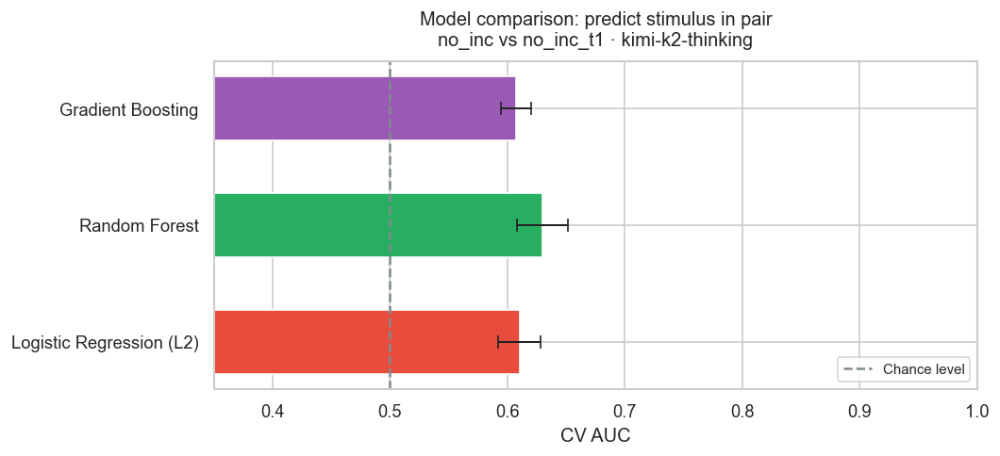

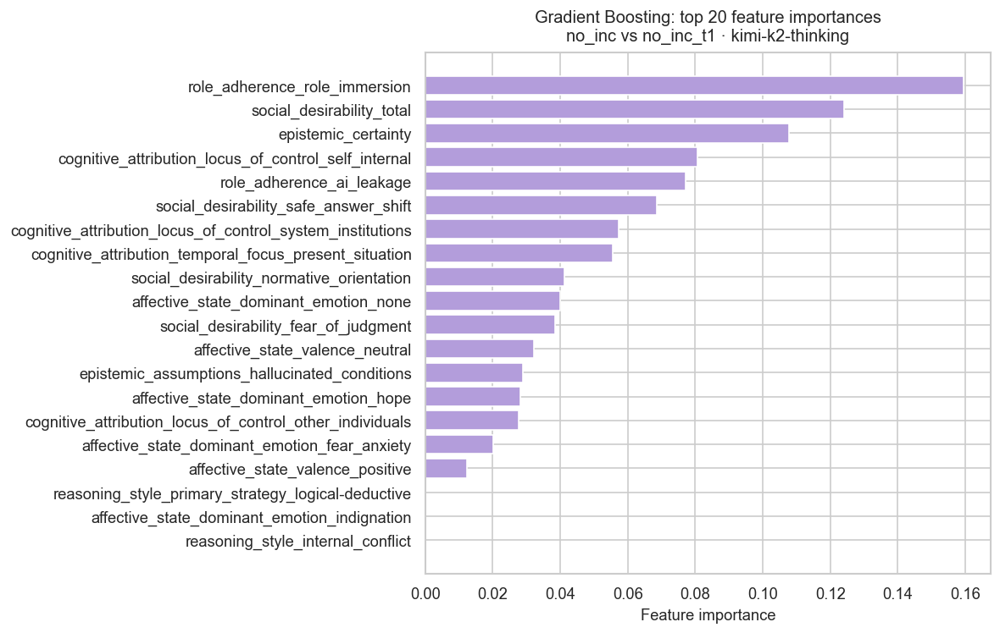

[skip] no_p2_vs_no_t1 | qwen/qwen3.5-9b... : skip: n=348 or minority=0


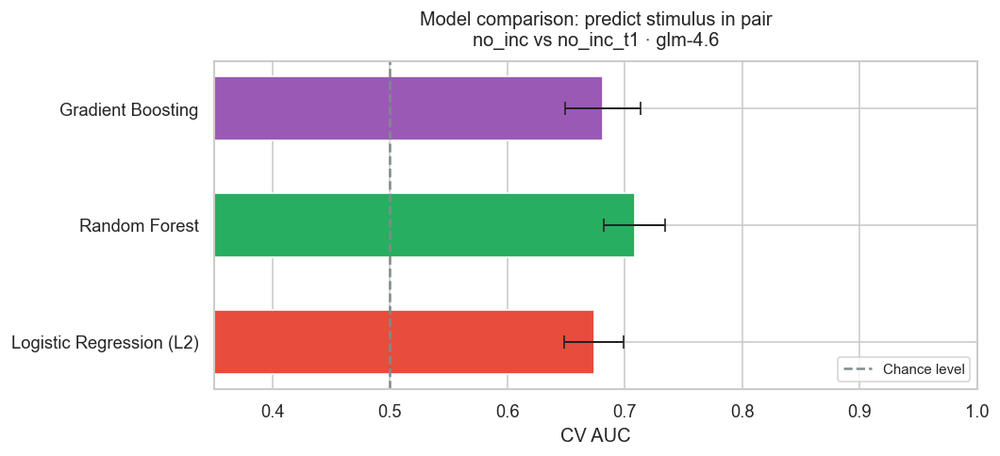

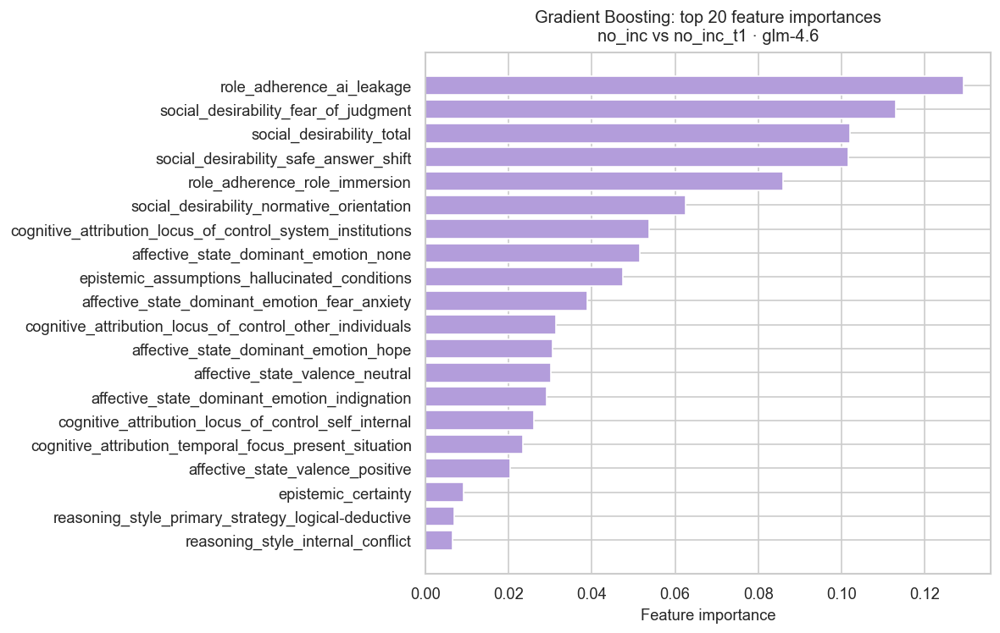

[skip] no_p2_vs_incentive_C | minimax/minimax-m2.5... : skip: n=350 or minority=0


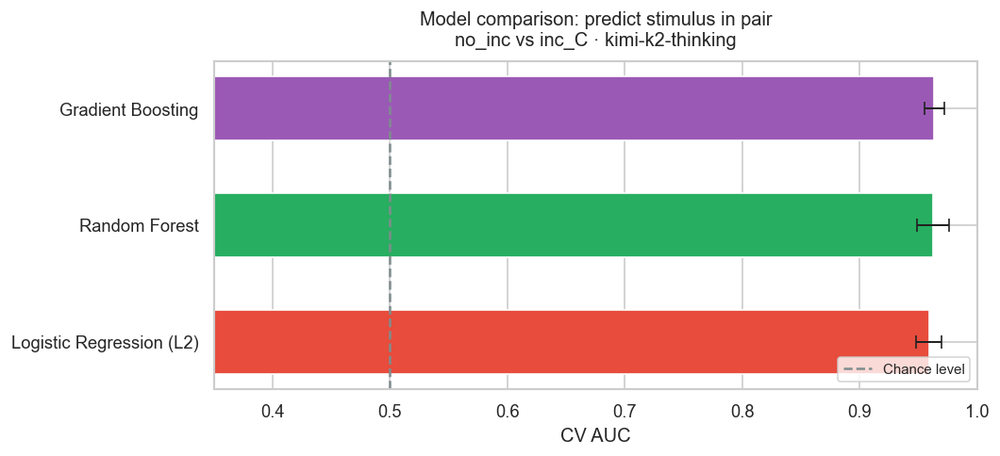

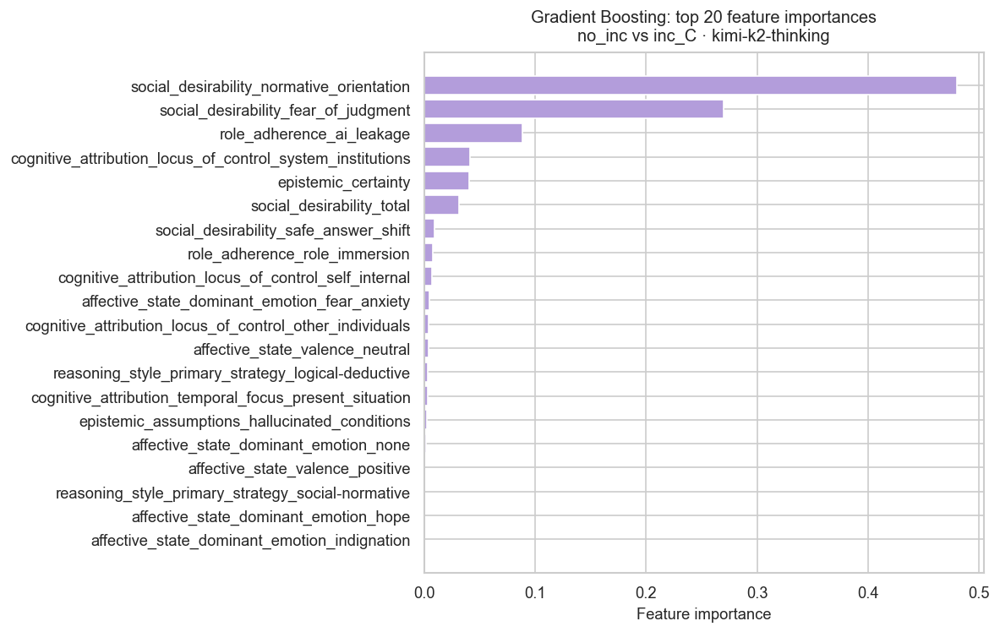

[skip] no_p2_vs_incentive_C | qwen/qwen3.5-9b... : skip: n=144 or minority=0


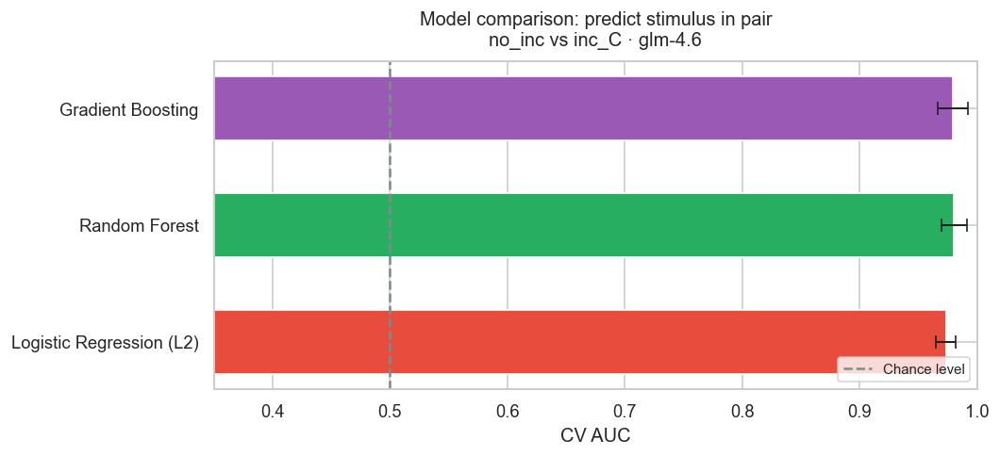

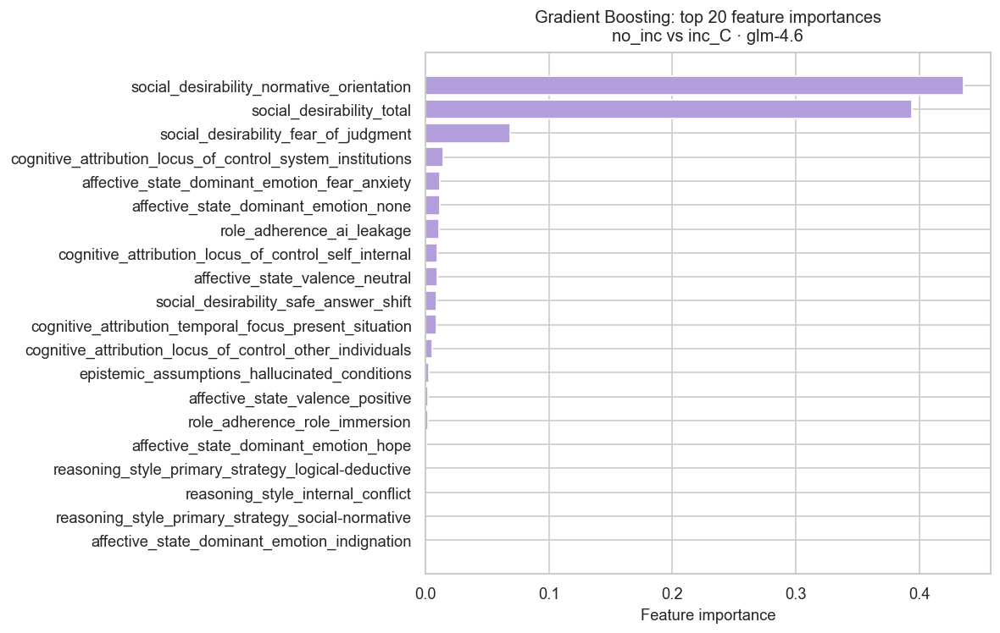

[skip] no_p2_vs_incentive_X | minimax/minimax-m2.5... : skip: n=350 or minority=0


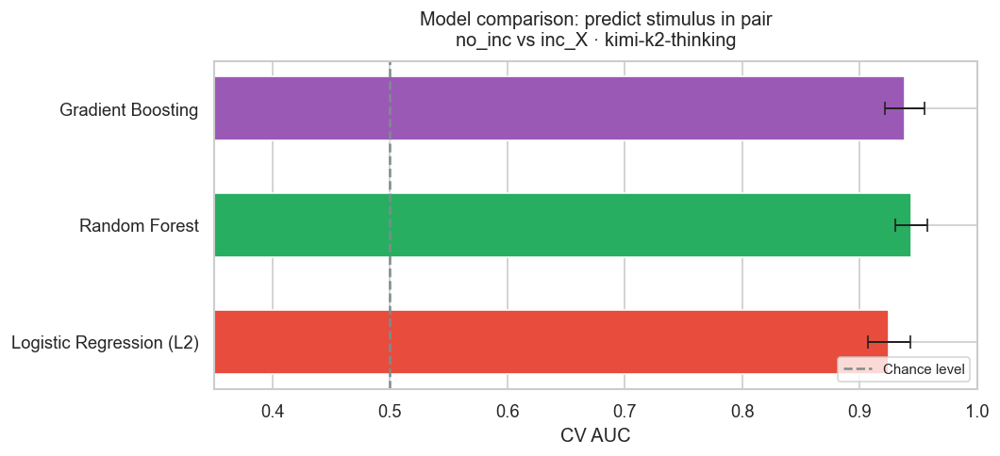

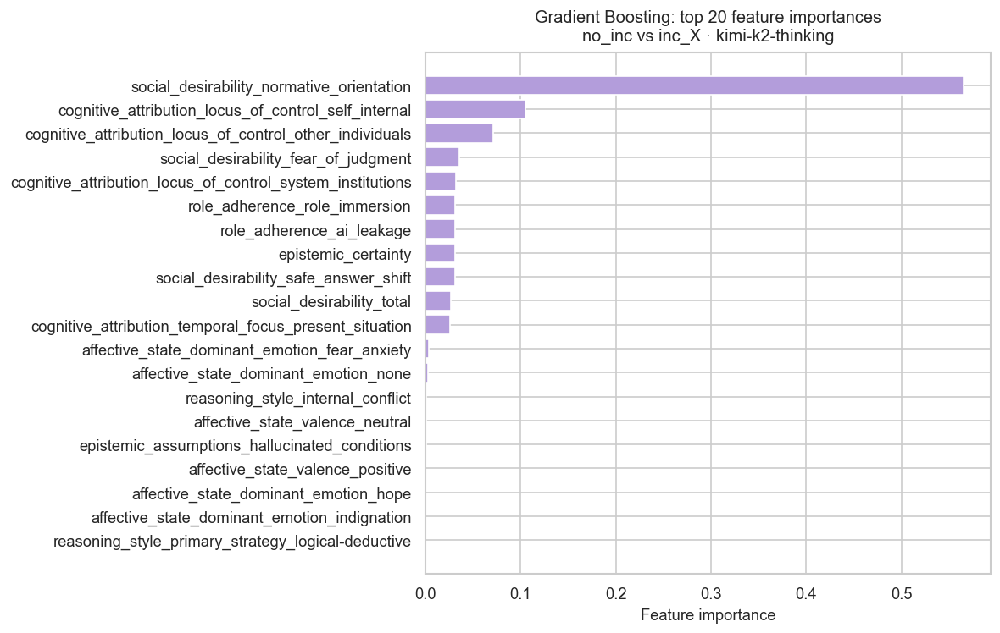

[skip] no_p2_vs_incentive_X | qwen/qwen3.5-9b... : skip: n=227 or minority=0


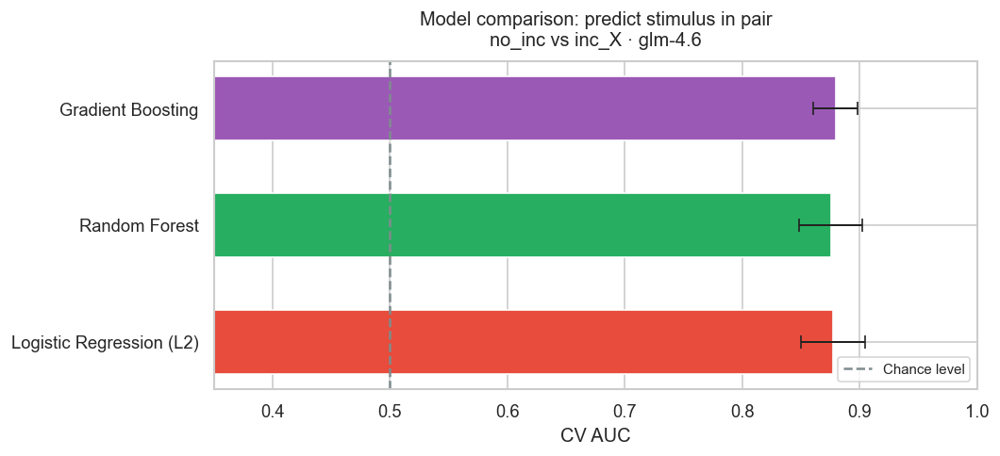

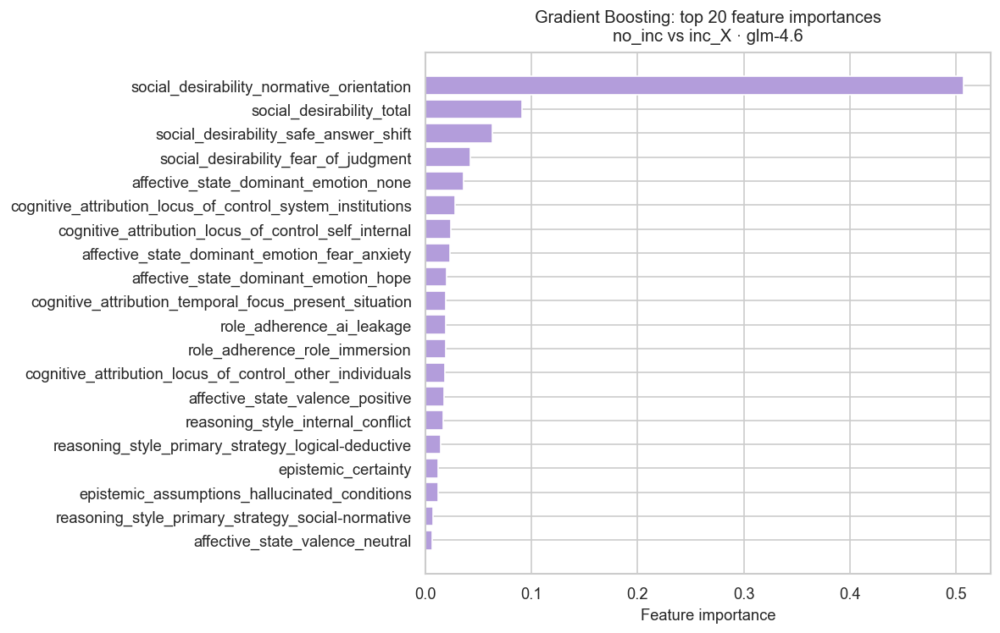

Saved: pairwise_per_model_classifier_summary.csv


,comparison,comparison_title,model,positive_run,negative_run,n,n_class0,n_class1,status,lr_auc_mean,lr_auc_std,rf_auc_mean,rf_auc_std,gb_auc_mean,gb_auc_std,cv_splits
0,no_p2_vs_no_t1,no_inc vs no_inc_t1,minimax/minimax-m2.5,no_t1,no_p2,350,0,350,skip: n=350 or minority=0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,no_p2_vs_no_t1,no_inc vs no_inc_t1,moonshotai/kimi-k2-thinking,no_t1,no_p2,700,350,350,ok,0.610143,0.018224,0.629796,0.021581,0.607388,0.012786,5.0
2,no_p2_vs_no_t1,no_inc vs no_inc_t1,qwen/qwen3.5-9b,no_t1,no_p2,348,0,348,skip: n=348 or minority=0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,no_p2_vs_no_t1,no_inc vs no_inc_t1,z-ai/glm-4.6,no_t1,no_p2,687,337,350,ok,0.673874,0.025344,0.708320,0.026235,0.681406,0.032001,5.0
4,no_p2_vs_incentive_C,no_inc vs inc_C,minimax/minimax-m2.5,incentive_C,no_p2,350,0,350,skip: n=350 or minority=0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,no_p2_vs_incentive_C,no_inc vs inc_C,moonshotai/kimi-k2-thinking,incentive_C,no_p2,700,350,350,ok,0.958714,0.010788,0.962184,0.013465,0.963388,0.008239,5.0
6,no_p2_vs_incentive_C,no_inc vs inc_C,qwen/qwen3.5-9b,incentive_C,no_p2,144,0,144,skip: n=144 or minority=0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,no_p2_vs_incentive_C,no_inc vs inc_C,z-ai/glm-4.6,incentive_C,no_p2,686,337,349,ok,0.973142,0.008347,0.980265,0.010708,0.978796,0.012803,5.0
8,no_p2_vs_incentive_X,no_inc vs inc_X,minimax/minimax-m2.5,incentive_X,no_p2,350,0,350,skip: n=350 or minority=0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,no_p2_vs_incentive_X,no_inc vs inc_X,moonshotai/kimi-k2-thinking,incentive_X,no_p2,700,350,350,ok,0.924694,0.018085,0.943816,0.013288,0.937857,0.016897,5.0


In [27]:
# === Per-model pairwise classifiers (3 pairs × K LLMs): CV AUC + GB feature importance ===
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

if "df" not in globals():
    raise RuntimeError("Сначала выполни ячейку ядра: df, ordinal_vars, binary_vars, categorical_vars.")

# Предикторы, которые почти кодируют incentive vs no-incentive или длину текста
LEAKY_EXCLUDE = {
    "incentive_awareness_score",
    "treatment_awareness_score",
    "reasoning_len_chars",
    "reasoning_len_words",
}

ordinal_safe = [c for c in ordinal_vars_ml if c not in LEAKY_EXCLUDE]
_num_list = [
    c
    for c in (ordinal_safe + binary_vars + ["social_desirability_total"])
    if c not in LEAKY_EXCLUDE and c in df.columns
]
pairwise_features_num = list(dict.fromkeys(_num_list))

COMPARE_DEFS = [
    ("no_p2_vs_no_t1", "no_inc vs no_inc_t1", ["no_p2", "no_t1"]),
    ("no_p2_vs_incentive_C", "no_inc vs inc_C", ["no_p2", "incentive_C"]),
    ("no_p2_vs_incentive_X", "no_inc vs inc_X", ["no_p2", "incentive_X"]),
]

MIN_TOTAL = 40
MIN_MINOR = 10
TOP_K = 20
RNG = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120


def _short_model_tag(m: str) -> str:
    s = str(m).replace("/", "_").replace(" ", "_")
    return re.sub(r"[^0-9a-zA-Z._-]+", "", s)[:80]


rows_summary = []

for tag, title, rs_list in COMPARE_DEFS:
    pos_key, neg_key = rs_list[1], rs_list[0]

    for model_name in sorted(df["model"].dropna().astype(str).unique()):
        sub = df[(df["run_source"].isin(rs_list)) & (df["model"].astype(str) == model_name)].copy()
        if sub.empty:
            continue

        sub["y_pair"] = (sub["run_source"] == pos_key).astype(int)
        cat_d = pd.get_dummies(
            sub[categorical_vars], prefix=categorical_vars, drop_first=True, dtype=int
        )
        Xn = sub[pairwise_features_num].copy()
        Xb = pd.concat([Xn, cat_d], axis=1)
        yb = sub["y_pair"]
        vm = Xb.notna().all(axis=1) & yb.notna()
        Xb = Xb.loc[vm].reset_index(drop=True)
        yb = yb.loc[vm].reset_index(drop=True)

        n0 = int((yb == 0).sum())
        n1 = int((yb == 1).sum())
        n_tot = len(Xb)
        n_minor = min(n0, n1)
        mtag = _short_model_tag(model_name)

        row_base = {
            "comparison": tag,
            "comparison_title": title,
            "model": model_name,
            "positive_run": pos_key,
            "negative_run": neg_key,
            "n": n_tot,
            "n_class0": n0,
            "n_class1": n1,
            "status": "",
            "lr_auc_mean": np.nan,
            "lr_auc_std": np.nan,
            "rf_auc_mean": np.nan,
            "rf_auc_std": np.nan,
            "gb_auc_mean": np.nan,
            "gb_auc_std": np.nan,
            "cv_splits": np.nan,
        }

        if n_tot < MIN_TOTAL or n_minor < MIN_MINOR:
            row_base["status"] = f"skip: n={n_tot} or minority={n_minor}"
            rows_summary.append(row_base)
            print(f"[skip] {tag} | {model_name[:40]}... : {row_base['status']}")
            continue

        n_splits = int(min(5, n_minor))
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RNG)
        scaler = StandardScaler()
        Xs = scaler.fit_transform(Xb.astype(float))
        feat_labels = list(Xb.columns)

        lr = LogisticRegression(max_iter=4000, C=1.0, random_state=RNG)
        rf = RandomForestClassifier(
            n_estimators=400,
            max_depth=8,
            min_samples_leaf=5,
            random_state=RNG,
            n_jobs=-1,
            class_weight="balanced",
        )
        gb = GradientBoostingClassifier(
            n_estimators=250,
            max_depth=4,
            learning_rate=0.05,
            min_samples_leaf=5,
            subsample=0.8,
            random_state=RNG,
        )

        auc_lr = cross_val_score(lr, Xs, yb, cv=cv, scoring="roc_auc")
        auc_rf = cross_val_score(rf, Xs, yb, cv=cv, scoring="roc_auc")
        auc_gb = cross_val_score(gb, Xs, yb, cv=cv, scoring="roc_auc")

        row_base.update(
            {
                "status": "ok",
                "lr_auc_mean": float(np.mean(auc_lr)),
                "lr_auc_std": float(np.std(auc_lr)),
                "rf_auc_mean": float(np.mean(auc_rf)),
                "rf_auc_std": float(np.std(auc_rf)),
                "gb_auc_mean": float(np.mean(auc_gb)),
                "gb_auc_std": float(np.std(auc_gb)),
                "cv_splits": n_splits,
            }
        )
        rows_summary.append(row_base)

        # --- Figure 1: horizontal CV AUC (like example) ---
        algos = [
            ("Gradient Boosting", float(np.mean(auc_gb)), float(np.std(auc_gb)), "#9b59b6"),
            ("Random Forest", float(np.mean(auc_rf)), float(np.std(auc_rf)), "#27ae60"),
            ("Logistic Regression (L2)", float(np.mean(auc_lr)), float(np.std(auc_lr)), "#e74c3c"),
        ]
        fig, ax = plt.subplots(figsize=(9, 4.2))
        y_pos = np.arange(len(algos))
        for i, (name, m, s, col) in enumerate(algos):
            ax.barh(
                i,
                m,
                xerr=s,
                color=col,
                edgecolor="white",
                height=0.55,
                capsize=4,
                error_kw={"ecolor": "#222", "linewidth": 1.2},
            )
        ax.set_yticks(y_pos)
        ax.set_yticklabels([a[0] for a in algos], fontsize=11)
        ax.invert_yaxis()
        ax.set_xlabel("CV AUC", fontsize=12)
        ax.set_xlim(0.35, 1.0)
        ax.axvline(0.5, color="#7f8c8d", linestyle="--", linewidth=1.5, label="Chance level")
        ax.set_title(
            f"Model comparison: predict stimulus in pair\n{title} · {model_name.split('/')[-1]}",
            fontsize=12,
            pad=10,
        )
        ax.legend(loc="lower right", fontsize=9)
        plt.tight_layout()
        p1 = f"fig_pairwise_per_model_auc_{tag}_{mtag}.png"
        plt.savefig(p1, bbox_inches="tight", dpi=140)
        plt.show()

        # --- Figure 2: GB feature importances (top K) ---
        gb_f = GradientBoostingClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            min_samples_leaf=5,
            subsample=0.8,
            random_state=RNG,
        )
        gb_f.fit(Xs, yb)
        imp = pd.DataFrame({"feature": feat_labels, "importance": gb_f.feature_importances_})
        imp = imp.sort_values("importance", ascending=False).head(TOP_K)
        fig2, ax2 = plt.subplots(figsize=(10, max(5, 0.32 * TOP_K)))
        sl = imp.iloc[::-1]
        ax2.barh(sl["feature"].astype(str), sl["importance"], color="#b39ddb", edgecolor="white")
        ax2.set_xlabel("Feature importance", fontsize=11)
        ax2.set_title(
            f"Gradient Boosting: top {TOP_K} feature importances\n{title} · {model_name.split('/')[-1]}",
            fontsize=12,
            pad=8,
        )
        plt.tight_layout()
        p2 = f"fig_pairwise_per_model_gb_imp_{tag}_{mtag}.png"
        plt.savefig(p2, bbox_inches="tight", dpi=140)
        plt.show()

        imp.to_csv(f"pairwise_per_model_gb_importance_{tag}_{mtag}.csv", index=False)

sum_df = pd.DataFrame(rows_summary)
sum_df.to_csv("pairwise_per_model_classifier_summary.csv", index=False)
print("Saved: pairwise_per_model_classifier_summary.csv")
try:
    display(sum_df)
except NameError:
    print(sum_df.to_string())




### Распределение сырых ответов (`final_answer_text`)

Сразу после загрузки `df`: для **каждого стимула** (`run_source`: no_inc → `no_p2`, no_inc_t1 → `no_t1`, inc_C → `incentive_C`, inc_X → `incentive_X`) строится сетка **эксперимент × модель** (как на примере): в каждой ячейке — **группированные столбцы** по `group_name`, по оси X — категории ответа (для Hassner: Yes / No / …; для Savary & Goldsmith: 1–5 / …).

Файлы: `fig_raw_answers_<стимул>.png` в каталоге ноутбука.



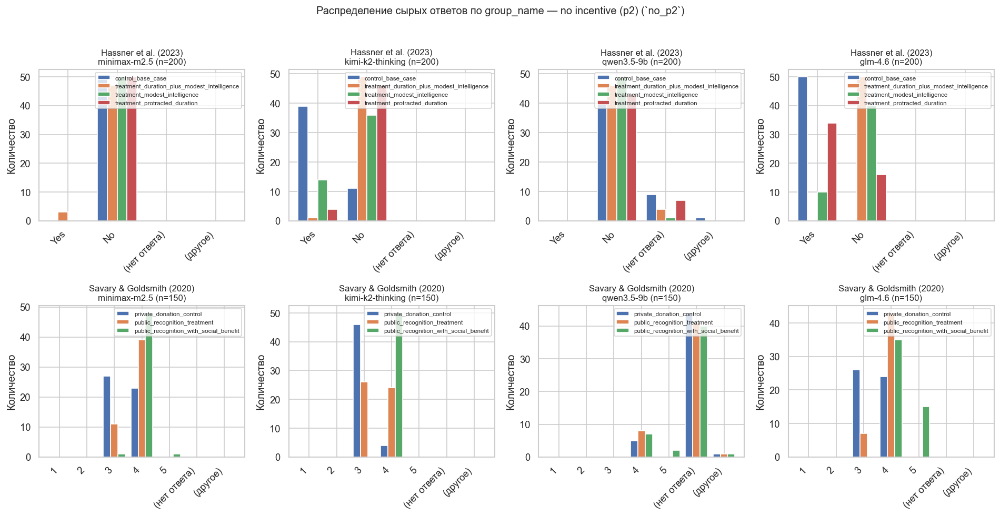

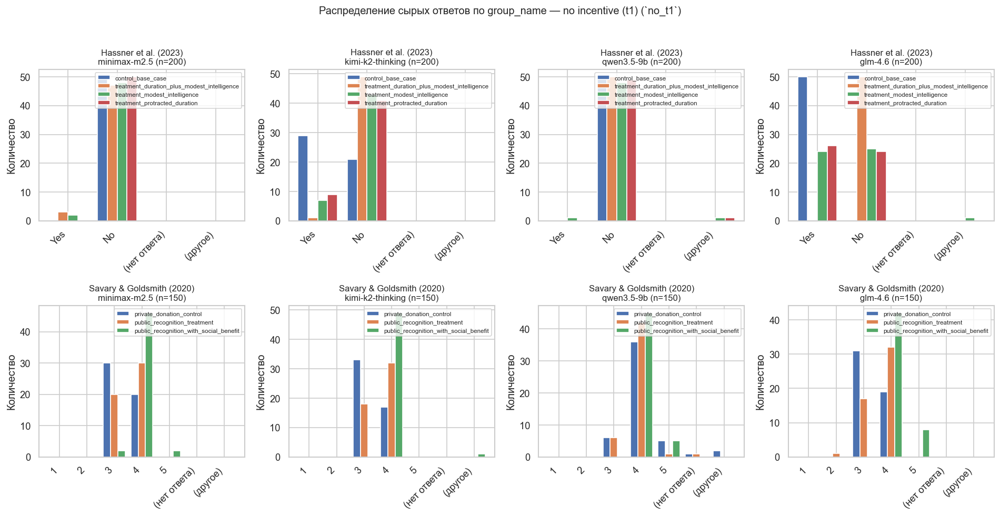

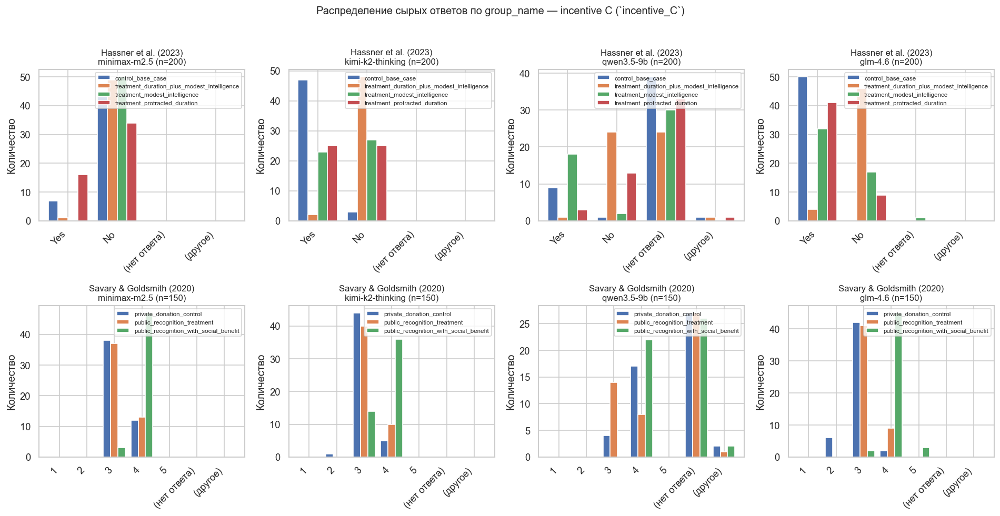

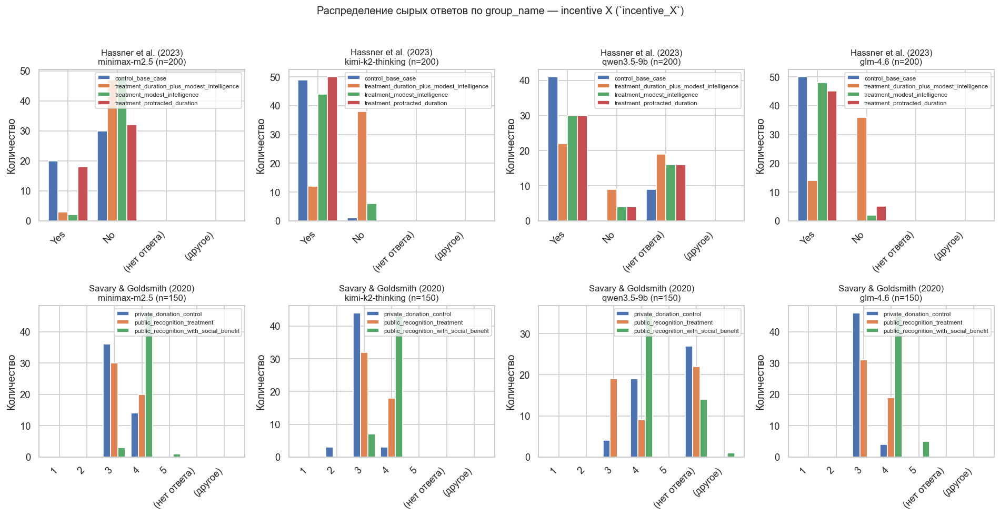

Готово: fig_raw_answers_no_inc | no_inc_t1 | inc_C | inc_X.png


In [28]:
# === 2a. Распределение сырых ответов: каждый стимул → сетка эксперимент × модель (hue = group_name) ===
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df" not in globals():
    raise ValueError("Сначала выполните ячейку загрузки данных (`df`).")

STIMULUS_RUNS = [
    ("no_inc", "no_p2", "no incentive (p2)"),
    ("no_inc_t1", "no_t1", "no incentive (t1)"),
    ("inc_C", "incentive_C", "incentive C"),
    ("inc_X", "incentive_X", "incentive X"),
]


def _first_digit(txt: str):
    if not txt or not str(txt).strip():
        return None
    first_line = str(txt).strip().split("\n")[0].strip()
    m = re.match(r"^(\d)\s*$", first_line)
    if m:
        return int(m.group(1))
    m2 = re.match(r"^\s*(\d)\b", first_line)
    if m2:
        return int(m2.group(1))
    return None


def normalize_answer_category(row):
    exp = str(row.get("experiment_name", ""))
    txt = str(row.get("final_answer_text", "")).strip()
    low = txt.lower()

    if not txt or low in ("nan", "none", "null"):
        return "(нет ответа)"

    if "hassner" in exp.lower():
        if re.search(r"\byes\b", low) and "not" not in low[:80]:
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        d = _first_digit(txt)
        if d == 1:
            return "Yes"
        if d == 2:
            return "No"
        return "(другое)"

    if "savary" in exp.lower() or "goldsmith" in exp.lower():
        d = _first_digit(txt)
        if d is not None and 1 <= d <= 5:
            return str(d)
        return "(другое)"

    d = _first_digit(txt)
    if d is not None:
        return str(d)
    return "(другое)"


def x_order_for_exp(exp_name: str):
    if "hassner" in str(exp_name).lower():
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


def short_exp_title(name):
    s = str(name)
    if "Hassner" in s:
        return "Hassner et al. (2023)"
    if "Savary" in s or "Goldsmith" in s:
        return "Savary & Goldsmith (2020)"
    return s[:50]


def short_model(m):
    m = str(m)
    return m.split("/")[-1] if "/" in m else m


_base = df.copy()
if "final_answer_text" not in _base.columns:
    raise ValueError("В данных нет колонки final_answer_text.")

for stim_tag, rs_key, stim_title in STIMULUS_RUNS:
    _plot_df = _base[_base["run_source"].astype(str) == rs_key].copy()
    if len(_plot_df) == 0:
        print(f"[{stim_tag}] нет строк для run_source={rs_key}, пропуск")
        continue

    _plot_df["answer_cat"] = _plot_df.apply(normalize_answer_category, axis=1)

    experiments = sorted(_plot_df["experiment_name"].dropna().unique())
    models = sorted(_plot_df["model"].dropna().unique())

    n_exp, n_mod = len(experiments), len(models)
    fig, axes = plt.subplots(
        n_exp,
        n_mod,
        figsize=(4 * n_mod, 4 * n_exp),
        squeeze=False,
    )

    for i, exp in enumerate(experiments):
        x_order = x_order_for_exp(exp)
        for j, model in enumerate(models):
            ax = axes[i][j]
            sub = _plot_df[
                (_plot_df["experiment_name"] == exp) & (_plot_df["model"] == model)
            ]
            n_sub = len(sub)

            if n_sub == 0:
                ax.set_visible(False)
                continue

            groups = sorted(sub["group_name"].dropna().astype(str).unique())
            counts = (
                sub.groupby(["answer_cat", "group_name"], dropna=False)
                .size()
                .unstack(fill_value=0)
            )

            x = np.arange(len(x_order))
            n_g = max(len(groups), 1)
            width = 0.8 / n_g
            for gi, g in enumerate(groups):
                vals = []
                for a in x_order:
                    try:
                        vals.append(
                            int(counts.loc[a, g])
                            if a in counts.index and g in counts.columns
                            else 0
                        )
                    except Exception:
                        vals.append(0)
                offset = (gi - (n_g - 1) / 2) * width
                ax.bar(x + offset, vals, width=width, label=g)

            ax.set_xticks(x)
            ax.set_xticklabels(x_order, rotation=45, ha="right")
            ax.set_ylabel("Количество")
            ax.set_title(
                f"{short_exp_title(exp)}\n{short_model(model)} (n={n_sub})",
                fontsize=10,
            )
            ax.legend(fontsize=7, loc="upper right")

    plt.suptitle(
        f"Распределение сырых ответов по group_name — {stim_title} (`{rs_key}`)",
        fontsize=12,
        y=1.02,
    )
    plt.tight_layout()
    out_png = f"fig_raw_answers_{stim_tag}.png"
    plt.savefig(out_png, bbox_inches="tight", dpi=160)
    plt.show()

print("Готово: fig_raw_answers_no_inc | no_inc_t1 | inc_C | inc_X.png")




6. WITHIN-MODEL ANALYSIS

────────────────────────────────────────────────────────────
Model: moonshotai/kimi-k2-thinking (n=1400)
────────────────────────────────────────────────────────────
  treatment_awareness_score                     p=0.0034 **  r=+0.082  mean_inc=1.897  mean_no=2.027
  incentive_awareness_score                     p=0.0000 *** r=-0.983  mean_inc=2.174  mean_no=0.000
  epistemic_certainty                           p=0.1682     r=-0.035  mean_inc=3.649  mean_no=3.583
  social_desirability_normative_orientation     p=0.0000 *** r=+0.681  mean_inc=1.123  mean_no=1.816
  social_desirability_fear_of_judgment          p=0.0000 *** r=-0.168  mean_inc=1.099  mean_no=0.909
  social_desirability_safe_answer_shift         p=0.1100     r=+0.044  mean_inc=1.414  mean_no=1.493
  role_adherence_role_immersion                 p=0.0000 *** r=+0.115  mean_inc=1.213  mean_no=1.329
  social_desirability_total                     p=0.0000 *** r=+0.313  mean_inc=3.636  mean_no=4.217

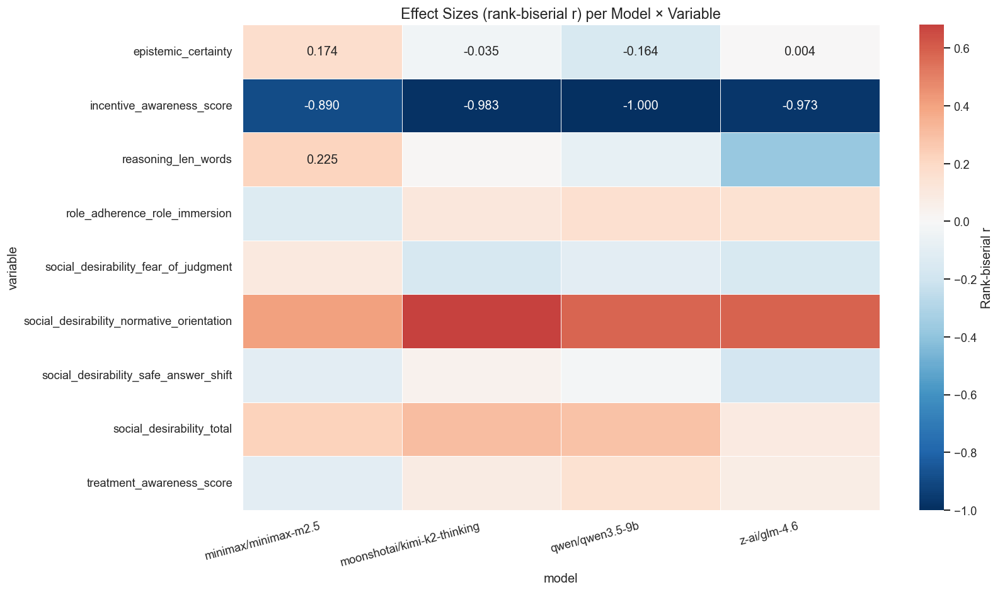

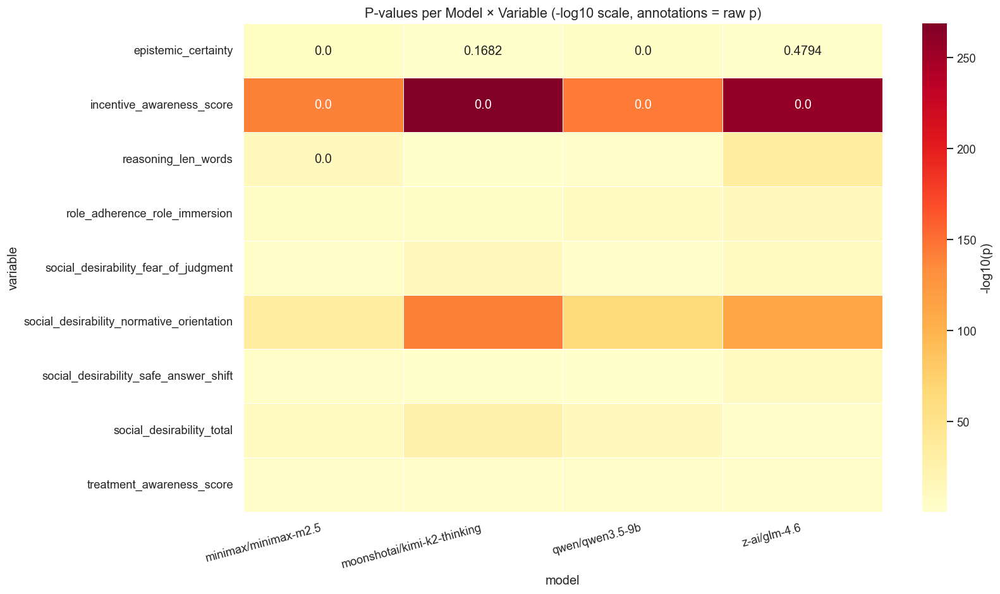

In [29]:
print("\n" + "=" * 80)
print("6. WITHIN-MODEL ANALYSIS")
print("=" * 80)

models = df["model"].unique()
within_model_results = []

for model_name in models:
    dfm = df[df["model"] == model_name]
    print(f"\n{'─'*60}")
    print(f"Model: {model_name} (n={len(dfm)})")
    print(f"{'─'*60}")
    for var in ordinal_vars + ["social_desirability_total", "reasoning_len_words"]:
        g1 = dfm.loc[dfm["condition"] == "incentive", var].dropna()
        g2 = dfm.loc[dfm["condition"] == "no_incentive", var].dropna()
        if len(g1) < 5 or len(g2) < 5:
            continue
        stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
        n1, n2 = len(g1), len(g2)
        r_effect = 1 - (2 * stat) / (n1 * n2)
        within_model_results.append({
            "model": model_name, "variable": var,
            "stat": stat, "p_value": p, "effect_size_r": r_effect,
            "mean_inc": g1.mean(), "mean_no": g2.mean()
        })
        sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
        print(f"  {var:45s} p={p:.4f} {sig:3s} r={r_effect:+.3f}  "f"mean_inc={g1.mean():.3f}  mean_no={g2.mean():.3f}")

df_within = pd.DataFrame(within_model_results)
if len(df_within) > 0:
    reject_w, p_adj_w, _, _ = multipletests(df_within["p_value"], method="fdr_bh")
    df_within["p_adjusted_fdr"] = p_adj_w
    df_within["significant_fdr05"] = reject_w
    df_within.to_csv("within_model_tests.csv", index=False)
    print("\n--- Within-model tests saved to within_model_tests.csv ---")

# ── 6b. Heatmap: effect sizes within each model ──
if len(df_within) > 0:
    pivot_eff = df_within.pivot_table(
        values="effect_size_r", index="variable", columns="model"
    )
    fig, ax = plt.subplots(figsize=(14, 8))
    sns.heatmap(
        pivot_eff, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
        ax=ax, linewidths=0.5, cbar_kws={"label": "Rank-biserial r"}
    )
    ax.set_title("Effect Sizes (rank-biserial r) per Model × Variable", fontsize=14)
    plt.xticks(rotation=15, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("fig_06_effect_sizes_heatmap_by_model.png", bbox_inches="tight")
    plt.show()

    # ── 6c. Heatmap: p-values within each model ──
    pivot_p = df_within.pivot_table(
        values="p_value", index="variable", columns="model"
    )
    fig, ax = plt.subplots(figsize=(14, 8))
    sns.heatmap(
        -np.log10(pivot_p + 1e-300), annot=pivot_p.round(4).values,
        fmt="", cmap="YlOrRd", ax=ax, linewidths=0.5,
        cbar_kws={"label": "-log10(p)"}
    )
    ax.set_title("P-values per Model × Variable (-log10 scale, annotations = raw p)", fontsize=13)
    plt.xticks(rotation=15, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("fig_06b_pvalues_heatmap_by_model.png", bbox_inches="tight")
    plt.show
              

In [30]:
print("\n" + "=" * 80)
print("7. WITHIN-EXPERIMENT ANALYSIS")
print("=" * 80)

experiments = df["experiment_name"].unique()
within_exp_results = []

for exp_name in experiments:
    dfe = df[df["experiment_name"] == exp_name]
    for var in ordinal_vars + ["social_desirability_total"]:
        g1 = dfe.loc[dfe["condition"] == "incentive", var].dropna()
        g2 = dfe.loc[dfe["condition"] == "no_incentive", var].dropna()
        if len(g1) < 3 or len(g2) < 3:
            continue
        stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
        n1, n2 = len(g1), len(g2)
        r_effect = 1 - (2 * stat) / (n1 * n2)
        within_exp_results.append({
            "experiment": exp_name, "variable": var,
            "stat": stat, "p_value": p, "effect_size_r": r_effect,
            "mean_inc": g1.mean(), "mean_no": g2.mean(),
            "n_inc": n1, "n_no": n2
        })

df_within_exp = pd.DataFrame(within_exp_results)
if len(df_within_exp) > 0:
    reject_e, p_adj_e, _, _ = multipletests(df_within_exp["p_value"], method="fdr_bh")
    df_within_exp["p_adjusted_fdr"] = p_adj_e
    df_within_exp["significant_fdr05"] = reject_e
    df_within_exp.to_csv("within_experiment_tests.csv", index=False)

    # Top significant experiment-level effects
    sig_exp = df_within_exp[df_within_exp["significant_fdr05"]].sort_values("p_adjusted_fdr")
    print(f"\nSignificant experiment-level effects (FDR < 0.05): {len(sig_exp)}")
    if len(sig_exp) > 0:
        print(sig_exp[["experiment", "variable", "effect_size_r",
                        "p_value", "p_adjusted_fdr", "mean_inc", "mean_no"]].head(30).to_string(index=False))


7. WITHIN-EXPERIMENT ANALYSIS

Significant experiment-level effects (FDR < 0.05): 14
                                                     experiment                                  variable  effect_size_r       p_value  p_adjusted_fdr  mean_inc  mean_no
  Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture                 incentive_awareness_score      -0.977353  0.000000e+00    0.000000e+00  2.191791 0.000000
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate                 incentive_awareness_score      -0.928098  0.000000e+00    0.000000e+00  2.046358 0.000000
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate social_desirability_normative_orientation       0.633000 1.240164e-172   6.614208e-172  1.145695 1.778531
  Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture social_desirability_normative_orientation       0.498376 6.669810e-142   2.667924e-141  1.288747 1.795000
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate 


8. CORRELATION ANALYSIS


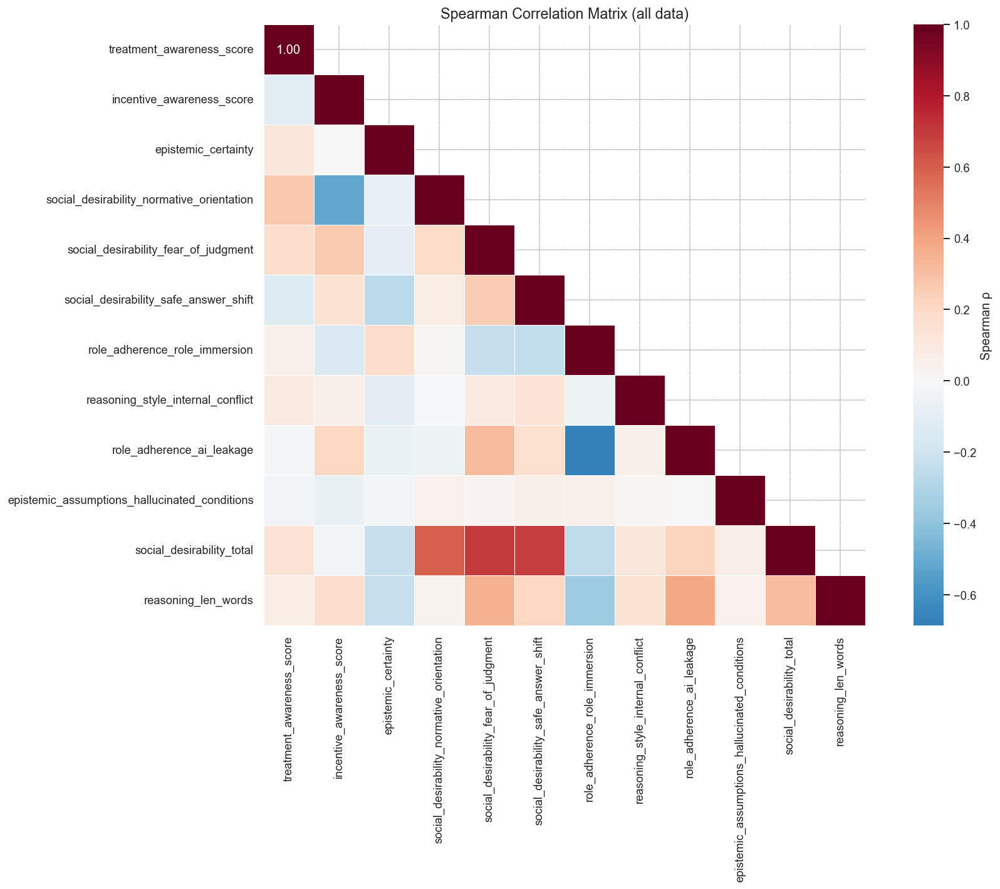

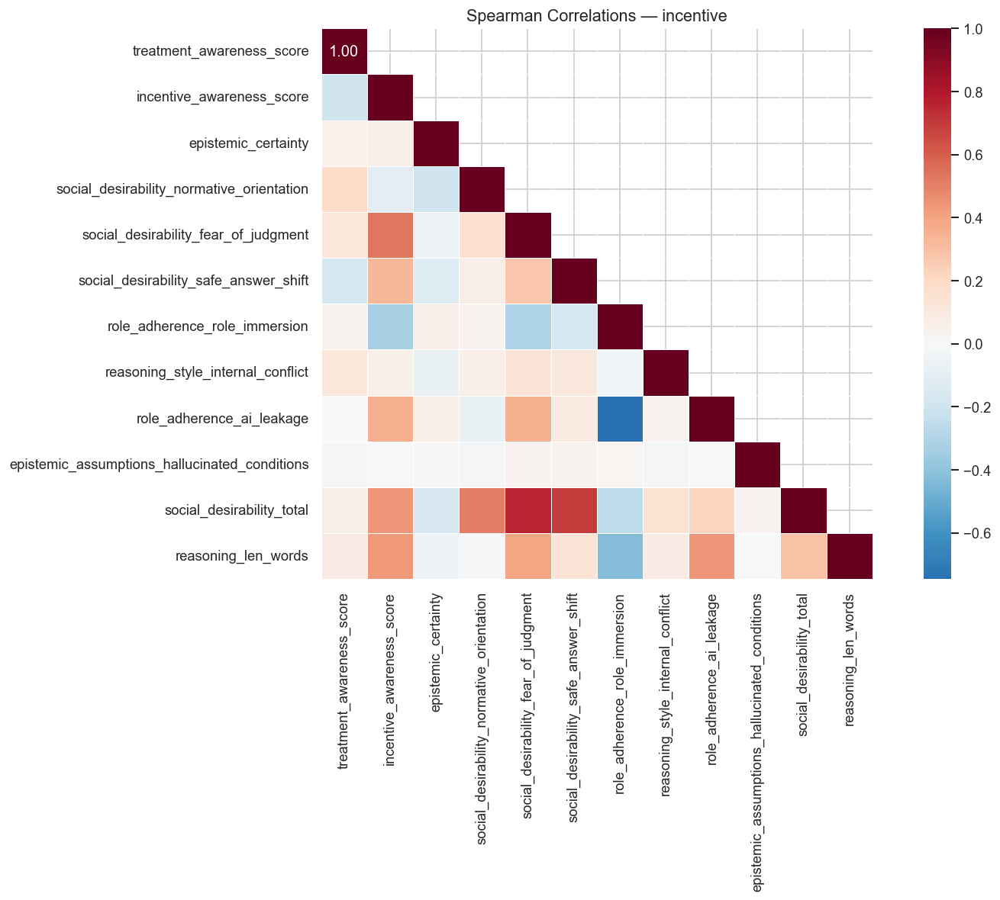

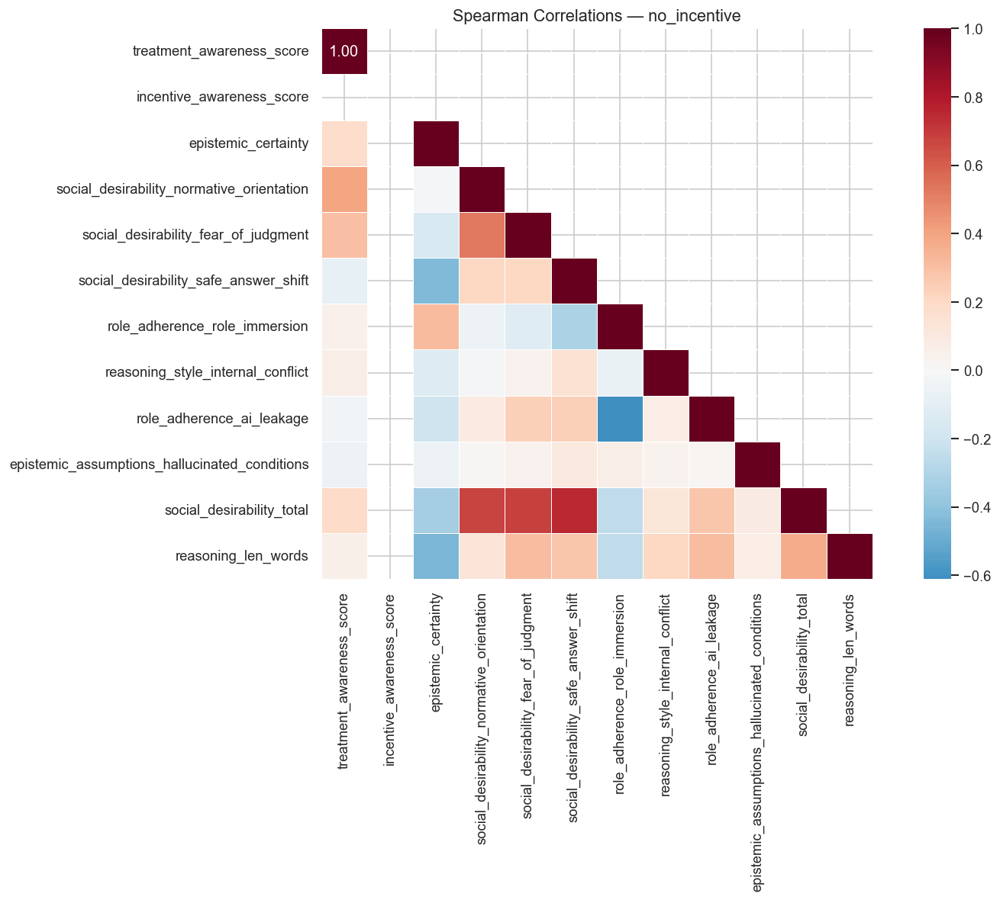

In [31]:
print("\n" + "=" * 80)
print("8. CORRELATION ANALYSIS")
print("=" * 80)

numeric_features = (
    ordinal_vars + binary_vars +
    ["social_desirability_total", "reasoning_len_words"]
)

# ── 8a. Overall Spearman correlation matrix ──
corr_data = df[numeric_features].dropna()
corr_matrix, p_matrix = pd.DataFrame(
    np.zeros((len(numeric_features), len(numeric_features))),
    index=numeric_features, columns=numeric_features
), pd.DataFrame(
    np.zeros((len(numeric_features), len(numeric_features))),
    index=numeric_features, columns=numeric_features
)

for c1 in numeric_features:
    for c2 in numeric_features:
        valid = corr_data[[c1, c2]].dropna()
        if len(valid) > 3:
            res = spearmanr(valid[c1], valid[c2])
            rho, p = res.statistic, res.pvalue

            # scipy may return 2x2 arrays in some edge cases; convert to scalars
            if np.ndim(rho) > 0:
                rho = rho[0, 1] if np.shape(rho) == (2, 2) else np.ravel(rho)[0]
            if np.ndim(p) > 0:
                p = p[0, 1] if np.shape(p) == (2, 2) else np.ravel(p)[0]

            corr_matrix.loc[c1, c2] = float(rho)
            p_matrix.loc[c1, c2] = float(p)
        else:
            corr_matrix.loc[c1, c2] = np.nan
            p_matrix.loc[c1, c2] = np.nan

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, ax=ax, linewidths=0.5, square=True,
    cbar_kws={"label": "Spearman ρ"}
)
ax.set_title("Spearman Correlation Matrix (all data)", fontsize=14)
plt.tight_layout()
plt.savefig("fig_07_correlation_matrix.png", bbox_inches="tight")
plt.show()

# ── 8b. Correlations SPLIT by condition ──
for cond in ["incentive", "no_incentive"]:
    subset = df[df["condition"] == cond][numeric_features].dropna()
    corr_cond = subset.corr(method="spearman")
    fig, ax = plt.subplots(figsize=(14, 10))
    mask_c = np.triu(np.ones_like(corr_cond, dtype=bool), k=1)
    sns.heatmap(
        corr_cond, mask=mask_c, annot=True, fmt=".2f", cmap="RdBu_r",
        center=0, ax=ax, linewidths=0.5, square=True
    )
    ax.set_title(f"Spearman Correlations — {cond}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"fig_08_correlation_{cond}.png", bbox_inches="tight")
    plt.show()




9. LOGISTIC REGRESSION: Predicting Condition
Features: 34
Samples : 4555 (dropped 1045 with NaN)
Class balance: {1: 2470, 0: 2085}
Statsmodels logit failed: Singular matrix

Logistic Regression CV AUC: 0.8902 ± 0.0068
  C= 0.001  AUC=0.6639±0.1339  non-zero=1
  C= 0.010  AUC=0.8756±0.0068  non-zero=10
  C= 0.050  AUC=0.8885±0.0067  non-zero=17
  C= 0.100  AUC=0.8891±0.0066  non-zero=21
  C= 0.500  AUC=0.8902±0.0066  non-zero=23
  C= 1.000  AUC=0.8902±0.0067  non-zero=23
  C= 5.000  AUC=0.8902±0.0068  non-zero=24
  C=10.000  AUC=0.8901±0.0068  non-zero=24


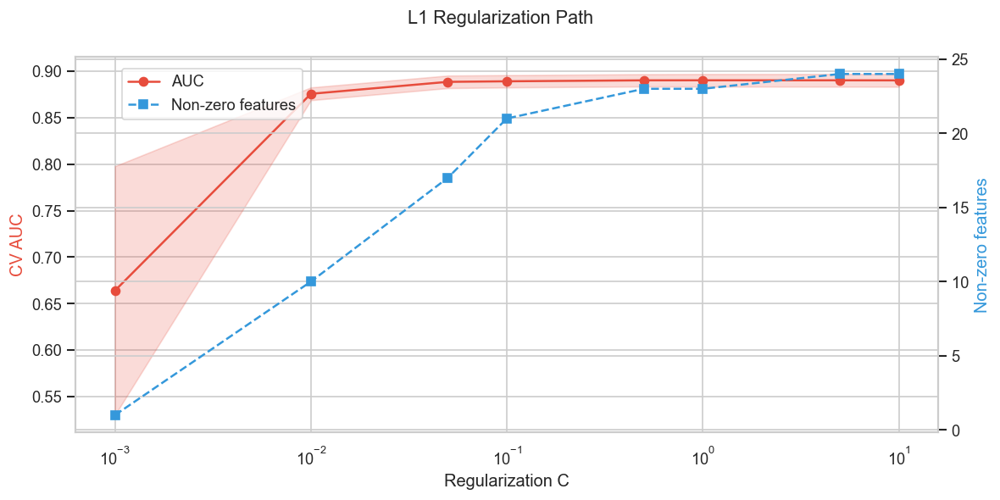

In [32]:
print("\n" + "=" * 80)
print("9. LOGISTIC REGRESSION: Predicting Condition")
print("=" * 80)

# ── 9a. Prepare feature matrix ──
# Encode categorical vars
df_model = df.copy()
df_model["condition_bin"] = (df_model["condition"] == "incentive").astype(int)

# One-hot encode categorical
cat_dummies = pd.get_dummies(
    df_model[categorical_vars], prefix=categorical_vars, drop_first=True, dtype=int
)

# Combine features
feature_cols_numeric = [
    c for c in (ordinal_vars_ml + binary_vars + ["social_desirability_total"])
    if c not in {"reasoning_len_words", "reasoning_len_chars"}
]
X_numeric = df_model[feature_cols_numeric].copy()
X_all = pd.concat([X_numeric, cat_dummies], axis=1)

# Add model dummies (control for model)
model_dummies = pd.get_dummies(df_model["model"], prefix="model", drop_first=True, dtype=int)
X_all = pd.concat([X_all, model_dummies], axis=1)

y = df_model["condition_bin"]

# Drop rows with NaN
valid_mask = X_all.notna().all(axis=1) & y.notna()
X_clean = X_all[valid_mask].reset_index(drop=True)
y_clean = y[valid_mask].reset_index(drop=True)

print(f"Features: {X_clean.shape[1]}")
print(f"Samples : {X_clean.shape[0]} (dropped {len(df) - len(X_clean)} with NaN)")
print(f"Class balance: {y_clean.value_counts().to_dict()}")

# ── 9b. Statsmodels logistic regression (for coefficients + p-values) ──
X_sm = sm.add_constant(X_clean.astype(float))
try:
    logit_model = sm.Logit(y_clean, X_sm).fit(disp=0, maxiter=200)
    print("\n--- Statsmodels Logistic Regression Summary ---")
    print(logit_model.summary2())

    # Extract coefficients
    coef_df = pd.DataFrame({
        "coef": logit_model.params,
        "std_err": logit_model.bse,
        "z": logit_model.tvalues,
        "p_value": logit_model.pvalues,
        "odds_ratio": np.exp(logit_model.params),
        "ci_lower": np.exp(logit_model.conf_int()[0]),
        "ci_upper": np.exp(logit_model.conf_int()[1]),
    })
    coef_df = coef_df.sort_values("p_value")
    coef_df.to_csv("logistic_regression_coefficients.csv")
    print("\nTop 20 coefficients by significance:")
    print(coef_df.head(20).to_string())

    # ── 9c. Odds Ratio forest plot ──
    coef_plot = coef_df.drop("const", errors="ignore").head(20).copy()
    coef_plot = coef_plot.sort_values("odds_ratio")

    fig, ax = plt.subplots(figsize=(10, 8))
    y_pos = range(len(coef_plot))
    ax.errorbar(
        coef_plot["odds_ratio"], y_pos,
        xerr=[
            coef_plot["odds_ratio"] - coef_plot["ci_lower"],
            coef_plot["ci_upper"] - coef_plot["odds_ratio"]
        ],
        fmt="o", color="#2c3e50", ecolor="#95a5a6", capsize=3, markersize=5
    )
    ax.axvline(x=1, color="red", linestyle="--", alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([textwrap.fill(str(idx), 40) for idx in coef_plot.index])
    ax.set_xlabel("Odds Ratio (95% CI)")
    ax.set_title("Logistic Regression: Top 20 Predictors of Incentive Condition", fontsize=13)
    plt.tight_layout()
    plt.savefig("fig_09_odds_ratio_forest.png", bbox_inches="tight")
    plt.show()

except Exception as e:
    print(f"Statsmodels logit failed: {e}")

# ── 9d. Sklearn Logistic Regression with cross-validation ──
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean.astype(float))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr = LogisticRegression(max_iter=1000, C=1.0, penalty="l2", random_state=42)
scores_lr = cross_val_score(lr, X_scaled, y_clean, cv=cv, scoring="roc_auc")
print(f"\nLogistic Regression CV AUC: {scores_lr.mean():.4f} ± {scores_lr.std():.4f}")

# ── 9e. Regularization path (L1) — feature selection ──
lr_l1 = LogisticRegression(max_iter=1000, penalty="l1", solver="saga", random_state=42)
C_values = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
l1_results = []

for C in C_values:
    lr_l1.set_params(C=C)
    sc = cross_val_score(lr_l1, X_scaled, y_clean, cv=cv, scoring="roc_auc")
    n_nonzero = None
    lr_l1.fit(X_scaled, y_clean)
    n_nonzero = np.sum(lr_l1.coef_[0] != 0)
    l1_results.append({"C": C, "AUC_mean": sc.mean(), "AUC_std": sc.std(),
                        "n_nonzero_features": n_nonzero})
    print(f"  C={C:6.3f}  AUC={sc.mean():.4f}±{sc.std():.4f}  non-zero={n_nonzero}")

df_l1 = pd.DataFrame(l1_results)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_l1["C"], df_l1["AUC_mean"], "o-", color="#e74c3c", label="AUC")
ax1.fill_between(
    df_l1["C"],
    df_l1["AUC_mean"] - df_l1["AUC_std"],
    df_l1["AUC_mean"] + df_l1["AUC_std"],
    alpha=0.2, color="#e74c3c"
)
ax1.set_xlabel("Regularization C")
ax1.set_ylabel("CV AUC", color="#e74c3c")
ax1.set_xscale("log")
ax2 = ax1.twinx()
ax2.plot(df_l1["C"], df_l1["n_nonzero_features"], "s--", color="#3498db", label="Non-zero features")
ax2.set_ylabel("Non-zero features", color="#3498db")
fig.suptitle("L1 Regularization Path", fontsize=13)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.savefig("fig_10_l1_regularization_path.png", bbox_inches="tight")
plt.show()



### Парные сравнения прогонов (`run_source`)

**Три пары:**

1. **no incentive vs incentive C:** `no_p2` vs `incentive_C`
2. **no incentive vs incentive X:** `no_p2` vs `incentive_X`
3. **no incentive p2 vs no incentive t1:** `no_p2` vs `no_t1`

**Столбчатые диаграммы:** для каждой метрики одна фигура из **двух осей** — отдельно для каждого эксперимента (`experiment_name`): слева **3** ячейки `group_name` (Savary & Goldsmith), справа **4** (Hassner et al.). Средние по респондентам внутри ячейки, оттенок `run_source`, 95% CI (если поддерживает версия `seaborn`).

**Классификаторы:** те же три пары; разметка + TF-IDF по `REASONING`; см. `run_pair_classifier_auc.csv`, `tfidf_discriminative_terms_<comparison>.csv`.



PAIRWISE: no_p2 vs incentive_C | vs incentive_X | vs no_t1
Bars: 2 axes per metric (experiment × experiment) + classifiers


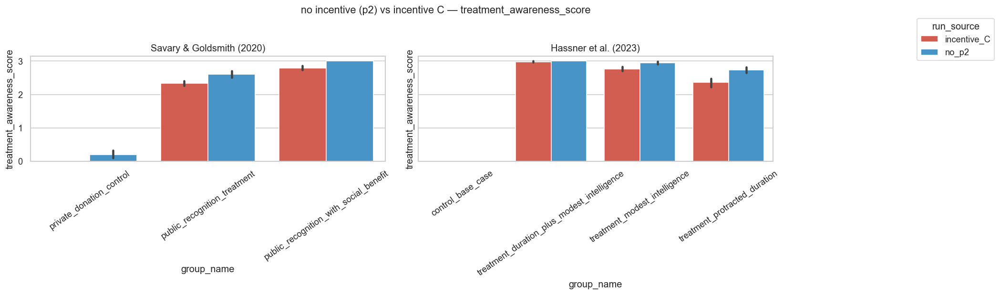

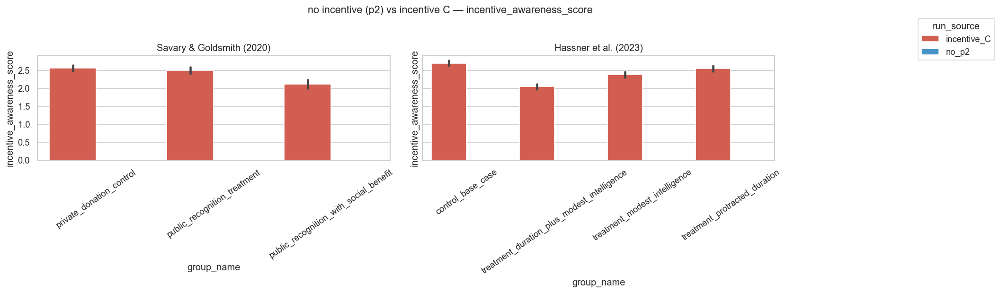

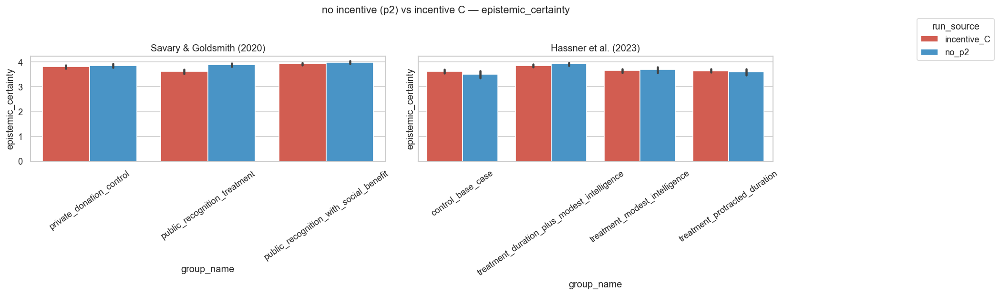

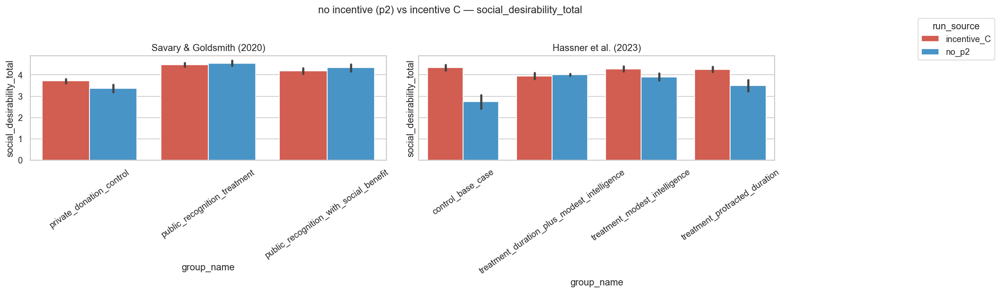

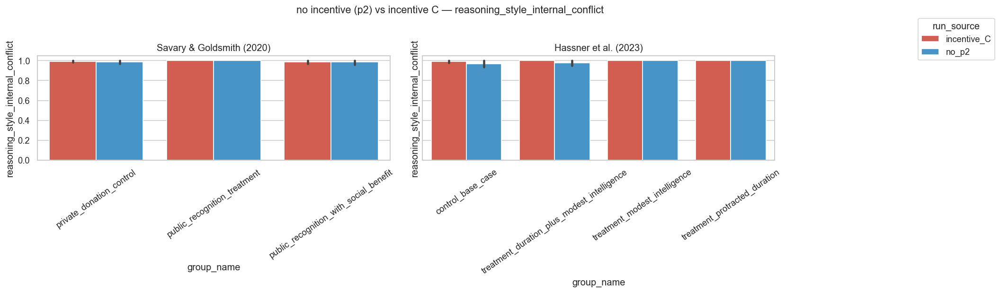

...

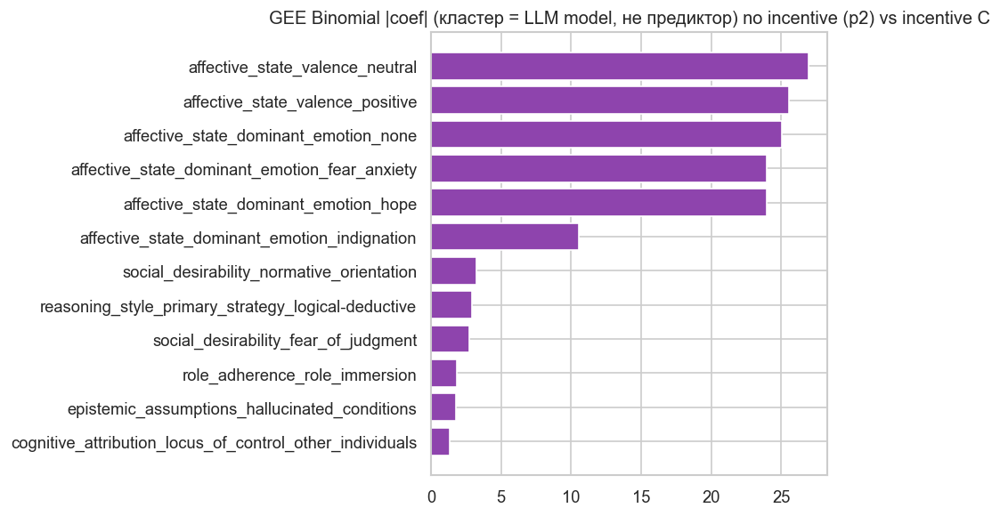

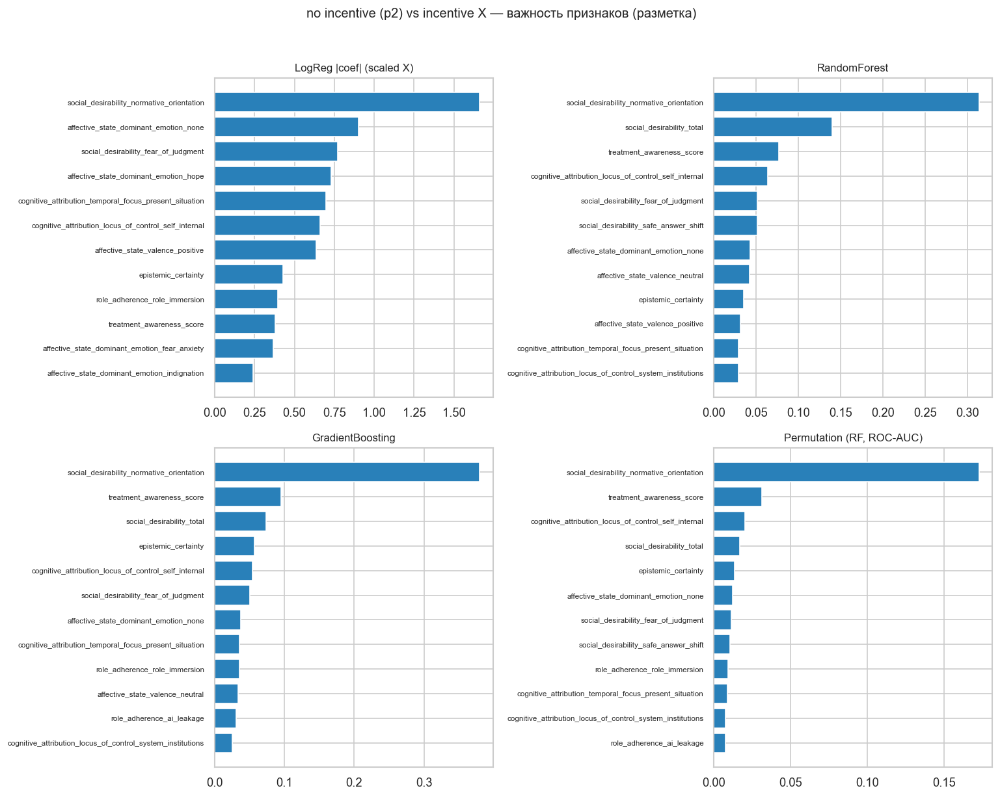

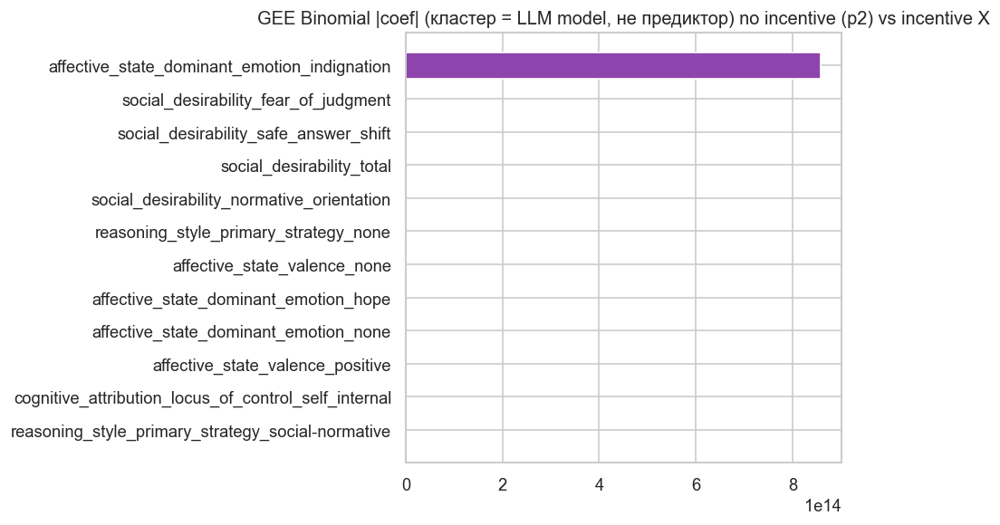

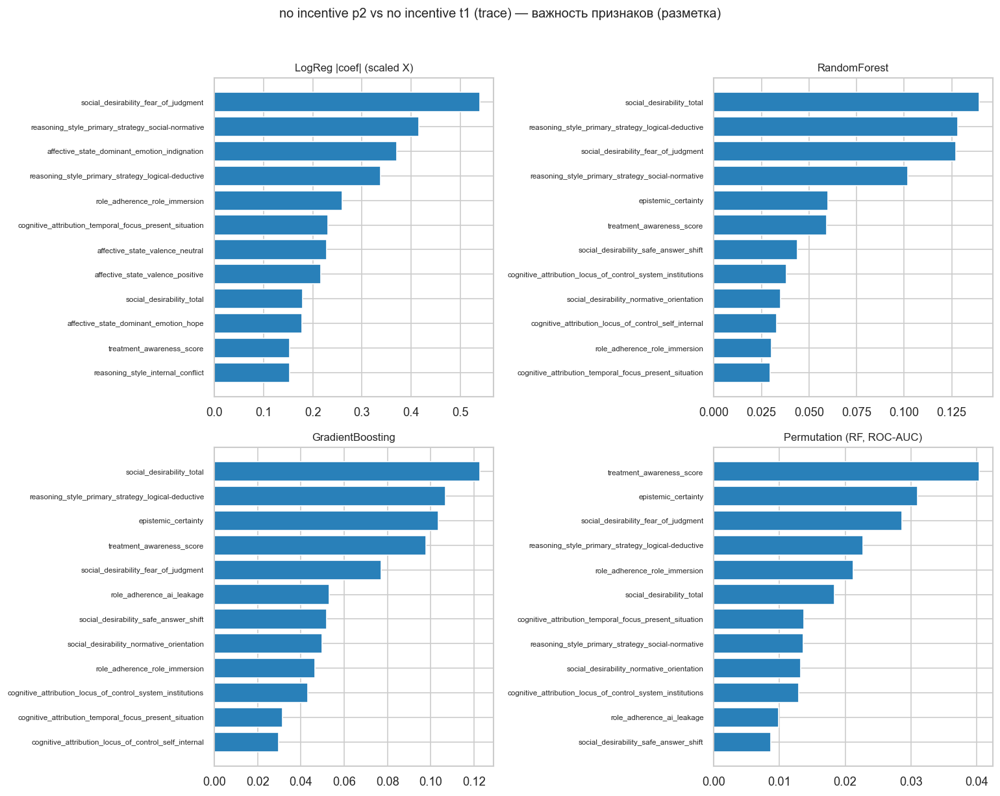

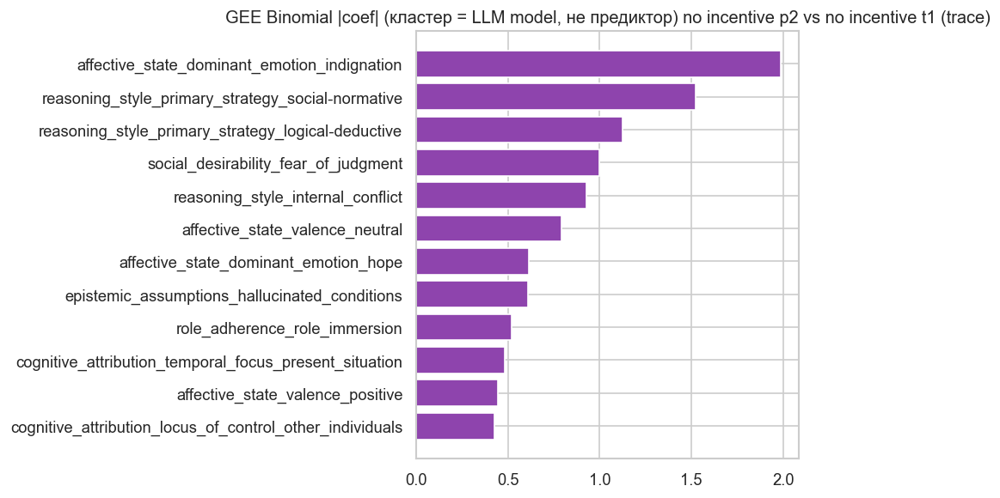

,comparison,title,positive_run,negative_run,n,n_class0,n_class1,lr_auc_mean,lr_auc_std,rf_auc_mean,rf_auc_std,gb_auc_mean,gb_auc_std,cv_splits,status
0,no_p2_vs_incentive_C,no incentive (p2) vs incentive C,incentive_C,no_p2,1880,687,1193,0.920340,0.022627,0.947591,0.016433,0.957906,0.012597,5,ok
1,no_p2_vs_incentive_X,no incentive (p2) vs incentive X,incentive_X,no_p2,1964,687,1277,0.873306,0.013560,0.899473,0.010299,0.910513,0.008153,5,ok
2,no_p2_vs_no_t1,no incentive p2 vs no incentive t1 (trace),no_t1,no_p2,2085,687,1398,0.711841,0.031768,0.746748,0.024934,0.759271,0.018116,5,ok



Saved: run_pair_classifier_auc.csv
Saved: run_cohort_classifier_auc.csv (same table)


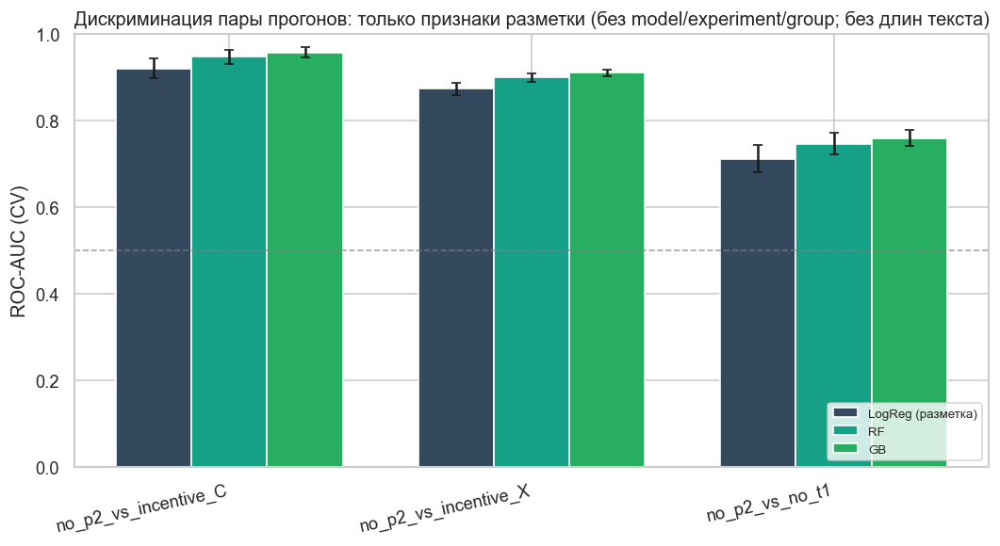

In [33]:
print("\n" + "=" * 80)
print("PAIRWISE: no_p2 vs incentive_C | vs incentive_X | vs no_t1")
print("Bars: 2 axes per metric (experiment × experiment) + classifiers")
print("=" * 80)

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance

try:
    from statsmodels.genmod.generalized_estimating_equations import GEE
    from statsmodels.genmod import families
    from statsmodels.genmod.cov_struct import Independence
except ImportError:
    GEE = None

palette_run = {
    "no_p2": "#3498db",
    "no_t1": "#9b59b6",
    "incentive_C": "#e74c3c",
    "incentive_X": "#e67e22",
}

bar_metrics = [
    "treatment_awareness_score",
    "incentive_awareness_score",
    "epistemic_certainty",
    "social_desirability_total",
    "reasoning_style_internal_conflict",
    "reasoning_len_chars",
    "reasoning_len_words",
]


def _experiment_bar_panels(sub_df):
    """По одному блоку на эксперимент: (name, order групп). Сортировка по числу групп → 3, затем 4."""
    parts = []
    for exp in sorted(sub_df["experiment_name"].dropna().unique()):
        gn = sorted(
            sub_df.loc[sub_df["experiment_name"] == exp, "group_name"]
            .dropna()
            .astype(str)
            .unique()
        )
        parts.append((exp, gn))
    parts.sort(key=lambda x: len(x[1]))
    return parts


def _short_exp_bar_title(name):
    s = str(name)
    if "Hassner" in s:
        return "Hassner et al. (2023)"
    if "Savary" in s or "Goldsmith" in s:
        return "Savary & Goldsmith (2020)"
    return (s[:44] + "…") if len(s) > 44 else s


compare_defs = [
    (
        "no_p2_vs_incentive_C",
        "no incentive (p2) vs incentive C",
        ["no_p2", "incentive_C"],
    ),
    (
        "no_p2_vs_incentive_X",
        "no incentive (p2) vs incentive X",
        ["no_p2", "incentive_X"],
    ),
    (
        "no_p2_vs_no_t1",
        "no incentive p2 vs no incentive t1 (trace)",
        ["no_p2", "no_t1"],
    ),
]

for tag, title, rs_list in compare_defs:
    sub = df[df["run_source"].isin(rs_list)].copy()
    if sub.empty:
        print(f"Skip bars {tag}: no rows")
        continue
    panels = _experiment_bar_panels(sub)
    if len(panels) != 2:
        print(
            f"Warning [{tag}]: ожидалось 2 эксперимента, получено {len(panels)} "
            "(проверьте experiment_name)"
        )

    for metric in bar_metrics:
        if metric not in sub.columns:
            continue
        fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
        legend_h, legend_l = None, None
        for ax, (exp_name, group_order) in zip(np.ravel(axes), panels):
            sub_e = sub[sub["experiment_name"] == exp_name].copy()
            if sub_e.empty:
                ax.set_visible(False)
                continue
            try:
                sns.barplot(
                    data=sub_e,
                    x="group_name",
                    y=metric,
                    hue="run_source",
                    palette=palette_run,
                    order=group_order,
                    errorbar=("ci", 95),
                    ax=ax,
                )
            except TypeError:
                sns.barplot(
                    data=sub_e,
                    x="group_name",
                    y=metric,
                    hue="run_source",
                    palette=palette_run,
                    order=group_order,
                    ci=95,
                    ax=ax,
                )
            ax.set_title(_short_exp_bar_title(exp_name))
            ax.set_xlabel("group_name")
            ax.tick_params(axis="x", rotation=35)
            leg = ax.get_legend()
            if leg is not None:
                if legend_h is None:
                    legend_h, legend_l = ax.get_legend_handles_labels()
                leg.remove()
        fig.suptitle(f"{title} — {metric}", fontsize=13, y=1.03)
        if legend_h:
            fig.legend(
                legend_h,
                legend_l,
                title="run_source",
                loc="upper left",
                bbox_to_anchor=(1.01, 1),
                frameon=True,
            )
        plt.tight_layout(rect=[0, 0, 0.88, 1])
        plt.savefig(f"fig_run_compare_{tag}_{metric}.png", bbox_inches="tight")
        plt.show()

MIN_MINOR_RUN = 10
MIN_TOTAL_RUN = 40

# Только признаки разметки (без model / experiment_name / group_name); без длин текста.
_pairwise_len_exclude = {"reasoning_len_chars", "reasoning_len_words"}
pairwise_markup_numeric = [
    c
    for c in (ordinal_vars_ml + binary_vars + ["social_desirability_total"])
    if c not in _pairwise_len_exclude and c in df.columns
]

rows_auc = []

for tag, title, rs_list in compare_defs:
    pos_key, neg_key = rs_list[1], rs_list[0]
    sub = df[df["run_source"].isin(rs_list)].copy()
    sub["y_pair"] = (sub["run_source"] == pos_key).astype(int)
    cat_d = pd.get_dummies(
        sub[categorical_vars], prefix=categorical_vars, drop_first=True, dtype=int
    )
    Xn = sub[pairwise_markup_numeric].copy()
    Xb = pd.concat([Xn, cat_d], axis=1)
    yb = sub["y_pair"]
    vm = Xb.notna().all(axis=1) & yb.notna()
    Xb = Xb.loc[vm].reset_index(drop=True)
    yb = yb.loc[vm].reset_index(drop=True)
    sub_vm = sub.loc[vm].reset_index(drop=True)
    n0 = int((yb == 0).sum())
    n1 = int((yb == 1).sum())
    n_tot = len(Xb)
    n_minor = min(n0, n1)

    skip_payload = {
        "comparison": tag,
        "title": title,
        "positive_run": pos_key,
        "negative_run": neg_key,
        "n": n_tot,
        "n_class0": n0,
        "n_class1": n1,
        "lr_auc_mean": np.nan,
        "lr_auc_std": np.nan,
        "rf_auc_mean": np.nan,
        "rf_auc_std": np.nan,
        "gb_auc_mean": np.nan,
        "gb_auc_std": np.nan,
        "cv_splits": np.nan,
        "status": f"skip: n={n_tot} or minority<{MIN_MINOR_RUN}",
    }

    if n_tot < MIN_TOTAL_RUN or n_minor < MIN_MINOR_RUN:
        rows_auc.append(skip_payload)
        continue

    n_splits = int(min(5, n_minor))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    scaler_rc = StandardScaler()
    Xs = scaler_rc.fit_transform(Xb.astype(float))
    feat_labels = list(Xb.columns)

    lr = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
    )
    gb = GradientBoostingClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42,
    )
    auc_lr = cross_val_score(lr, Xs, yb, cv=cv, scoring="roc_auc")
    auc_rf = cross_val_score(rf, Xs, yb, cv=cv, scoring="roc_auc")
    auc_gb = cross_val_score(gb, Xs, yb, cv=cv, scoring="roc_auc")

    # --- Итоговые модели + рейтинги важности (только разметка) ---
    lr_f = LogisticRegression(max_iter=4000, C=1.0, random_state=42)
    lr_f.fit(Xs, yb)
    df_lr = pd.DataFrame(
        {"feature": feat_labels, "coef": lr_f.coef_[0], "abs_coef": np.abs(lr_f.coef_[0])}
    ).sort_values("abs_coef", ascending=False)
    df_lr["rank_abs_coef"] = np.arange(1, len(df_lr) + 1)
    p_lr = f"pairwise_{tag}_logreg_coef.csv"
    df_lr.to_csv(p_lr, index=False)

    rf_f = RandomForestClassifier(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
    )
    rf_f.fit(Xs, yb)
    df_rf = pd.DataFrame(
        {"feature": feat_labels, "importance": rf_f.feature_importances_}
    ).sort_values("importance", ascending=False)
    df_rf["rank_importance"] = np.arange(1, len(df_rf) + 1)
    p_rf = f"pairwise_{tag}_rf_importance.csv"
    df_rf.to_csv(p_rf, index=False)

    gb_f = GradientBoostingClassifier(
        n_estimators=250,
        max_depth=4,
        learning_rate=0.05,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42,
    )
    gb_f.fit(Xs, yb)
    df_gb = pd.DataFrame(
        {"feature": feat_labels, "importance": gb_f.feature_importances_}
    ).sort_values("importance", ascending=False)
    df_gb["rank_importance"] = np.arange(1, len(df_gb) + 1)
    p_gb = f"pairwise_{tag}_gb_importance.csv"
    df_gb.to_csv(p_gb, index=False)

    perm = permutation_importance(
        rf_f,
        Xs,
        yb,
        n_repeats=8,
        random_state=42,
        n_jobs=-1,
        scoring="roc_auc",
    )
    df_perm = pd.DataFrame(
        {
            "feature": feat_labels,
            "perm_importance_mean": perm.importances_mean,
            "perm_importance_std": perm.importances_std,
        }
    ).sort_values("perm_importance_mean", ascending=False)
    df_perm["rank_perm"] = np.arange(1, len(df_perm) + 1)
    p_pm = f"pairwise_{tag}_rf_permutation_importance.csv"
    df_perm.to_csv(p_pm, index=False)

    gee_ok = False
    df_gee_plot = None
    p_gee = f"pairwise_{tag}_gee_binomial.csv"
    if GEE is not None:
        try:
            X_gee = sm.add_constant(Xb.astype(float), has_constant="add")
            gee = GEE(
                yb.astype(float).values,
                X_gee,
                groups=sub_vm["model"].astype(str),
                family=families.Binomial(),
                cov_struct=Independence(),
            )
            gee_res = gee.fit()
            df_gee = pd.DataFrame(
                {
                    "feature": X_gee.columns,
                    "coef": gee_res.params,
                    "stderr": gee_res.bse,
                    "z": gee_res.tvalues,
                    "p_value": gee_res.pvalues,
                    "abs_coef": np.abs(gee_res.params),
                }
            ).sort_values("abs_coef", ascending=False)
            df_gee["rank_abs_coef"] = np.arange(1, len(df_gee) + 1)
            df_gee.to_csv(p_gee, index=False)
            df_gee_plot = df_gee.copy()
            gee_ok = True
        except Exception as _gee_e:
            pd.DataFrame([{"error": str(_gee_e)}]).to_csv(p_gee, index=False)
    else:
        pd.DataFrame([{"error": "statsmodels GEE not available"}]).to_csv(
            p_gee, index=False
        )

    R = pd.DataFrame({"feature": feat_labels})
    rmap_lr = df_lr.set_index("feature")["rank_abs_coef"]
    rmap_rf = df_rf.set_index("feature")["rank_importance"]
    rmap_gb = df_gb.set_index("feature")["rank_importance"]
    rmap_pm = df_perm.set_index("feature")["rank_perm"]
    R["rank_lr"] = R["feature"].map(rmap_lr)
    R["rank_rf"] = R["feature"].map(rmap_rf)
    R["rank_gb"] = R["feature"].map(rmap_gb)
    R["rank_perm_rf"] = R["feature"].map(rmap_pm)
    R["mean_rank"] = R[["rank_lr", "rank_rf", "rank_gb", "rank_perm_rf"]].mean(axis=1)
    R = R.sort_values("mean_rank")
    R["final_rank"] = np.arange(1, len(R) + 1)
    p_rank = f"pairwise_{tag}_combined_feature_rank.csv"
    R.to_csv(p_rank, index=False)

    top_k = 12
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    axa = axes.ravel()
    plot_sets = [
        (df_lr.head(top_k), "feature", "abs_coef", "LogReg |coef| (scaled X)"),
        (df_rf.head(top_k), "feature", "importance", "RandomForest"),
        (df_gb.head(top_k), "feature", "importance", "GradientBoosting"),
        (
            df_perm.head(top_k),
            "feature",
            "perm_importance_mean",
            "Permutation (RF, ROC-AUC)",
        ),
    ]
    for ax, (d_, xf, yf, ttl) in zip(axa, plot_sets):
        sl = d_.iloc[::-1]
        ax.barh(sl[xf].astype(str), sl[yf].astype(float), color="#2980b9")
        ax.set_title(ttl, fontsize=10)
        ax.tick_params(axis="y", labelsize=7)
    plt.suptitle(f"{title} — важность признаков (разметка)", fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(f"fig_pairwise_importance_fourway_{tag}.png", bbox_inches="tight")
    plt.show()

    if gee_ok and df_gee_plot is not None:
        df_gt = df_gee_plot[df_gee_plot["feature"] != "const"].head(top_k)
        fig_g, ax_g = plt.subplots(figsize=(8, 5))
        sl = df_gt.iloc[::-1]
        ax_g.barh(sl["feature"].astype(str), sl["abs_coef"].astype(float), color="#8e44ad")
        ax_g.set_title(
            f"GEE Binomial |coef| (кластер = LLM model, не предиктор) {title}"
        )
        plt.tight_layout()
        plt.savefig(f"fig_pairwise_importance_gee_{tag}.png", bbox_inches="tight")
        plt.show()

    rows_auc.append(
        {
            "comparison": tag,
            "title": title,
            "positive_run": pos_key,
            "negative_run": neg_key,
            "n": n_tot,
            "n_class0": n0,
            "n_class1": n1,
            "lr_auc_mean": float(np.mean(auc_lr)),
            "lr_auc_std": float(np.std(auc_lr)),
            "rf_auc_mean": float(np.mean(auc_rf)),
            "rf_auc_std": float(np.std(auc_rf)),
            "gb_auc_mean": float(np.mean(auc_gb)),
            "gb_auc_std": float(np.std(auc_gb)),
            "cv_splits": n_splits,
            "status": "ok",
        }
    )


df_run_auc = pd.DataFrame(rows_auc)
display(df_run_auc)

out_pair = "run_pair_classifier_auc.csv"
df_run_auc.to_csv(out_pair, index=False)
df_run_auc.to_csv("run_cohort_classifier_auc.csv", index=False)
print(f"\nSaved: {out_pair}")
print("Saved: run_cohort_classifier_auc.csv (same table)")
ok = df_run_auc[df_run_auc["status"] == "ok"]
if len(ok):
    fig, ax = plt.subplots(figsize=(9, 5))
    labs = ok["comparison"].tolist()
    x = np.arange(len(labs))
    w = 0.25
    ax.bar(
        x - w,
        ok["lr_auc_mean"],
        w,
        yerr=ok["lr_auc_std"],
        label="LogReg (разметка)",
        capsize=3,
        color="#34495e",
    )
    ax.bar(
        x,
        ok["rf_auc_mean"],
        w,
        yerr=ok["rf_auc_std"],
        label="RF",
        capsize=3,
        color="#16a085",
    )
    ax.bar(
        x + w,
        ok["gb_auc_mean"],
        w,
        yerr=ok["gb_auc_std"],
        label="GB",
        capsize=3,
        color="#27ae60",
    )
    ax.axhline(0.5, color="gray", linestyle="--", alpha=0.7, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labs, rotation=12, ha="right")
    ax.set_ylabel("ROC-AUC (CV)")
    ax.set_ylim(0, 1)
    ax.set_title(
        "Дискриминация пары прогонов: только признаки разметки "
        "(без model/experiment/group; без длин текста)"
    )
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig("fig_pair_classifier_auc_summary.png", bbox_inches="tight")
    plt.show()


### SHAP и LIME по стратам (стимул × эксперимент × модель)

**16 страт:** 4 стимула (`run_source`: `no_p2` = no_inc, `no_t1` = no_inc_t1, `incentive_C`, `incentive_X`) × **2** эксперимента × **2** LLM (**kimi**, **glm**).

**Предикторы:** признаки разметки из ядра (`ordinal_vars_ml`, `binary_vars`, `social_desirability_total`, `categorical_vars`; без `incentive_awareness_score`), без длин reasoning (`reasoning_len_chars`, `reasoning_len_words`), плюс **тритмент-группа** — дамми-кодирование `group_name`.

**Целевая переменная:** регрессия на `epistemic_certainty` (числовой скор разметки). При необходимости замените константу `TARGET_COL` в коде на другой числовой исход.

**Артефакты:** каталог `thinking_expos/shap_lime_strata/` — графики SHAP (`shap_summary_*.png`), усреднённые |SHAP| (`shap_mean_abs_*.csv`), HTML LIME (`lime_*_test*.html`), журнал `run_log.csv`.

**Зависимости:** `pip install shap lime` (выполните один раз в том же окружении, что и ноутбук).



In [34]:
print("\n" + "=" * 80)
print("SHAP / LIME: 16 strata (stimulus × experiment × kimi / glm)")
print("=" * 80)

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

_OUT = Path("shap_lime_strata")
_OUT.mkdir(exist_ok=True)

SHAP_OK = False
LIME_OK = False
try:
    import shap

    SHAP_OK = True
except Exception as _e:
    print("SHAP unavailable:", _e)
try:
    from lime.lime_tabular import LimeTabularExplainer

    LIME_OK = True
except Exception as _e:
    print("LIME unavailable:", _e)

TARGET_COL = "epistemic_certainty"

STIMULUS_TO_RUN = {
    "no_inc": "no_p2",
    "no_inc_t1": "no_t1",
    "inc_C": "incentive_C",
    "inc_X": "incentive_X",
}

MODELS_USE = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
]

_LEN_EXCLUDE = {"reasoning_len_chars", "reasoning_len_words"}


def _short_exp(name: str) -> str:
    s = str(name)
    if "Hassner" in s:
        return "Hassner"
    if "Savary" in s or "Goldsmith" in s:
        return "Savary"
    return "exp"


def _short_model(m: str) -> str:
    ms = str(m).lower()
    if "kimi" in ms:
        return "kimi"
    if "glm" in ms:
        return "glm"
    return str(m).replace("/", "_")[:24]


def _build_design_matrix(sub: pd.DataFrame, target_col: str):
    num_cols = [
        c
        for c in (ordinal_vars_ml + binary_vars + ["social_desirability_total"])
        if c not in _LEN_EXCLUDE and c != target_col and c in sub.columns
    ]
    cat_cols = [c for c in categorical_vars if c in sub.columns]
    cat_cols_treat = cat_cols + ["group_name"]
    X_num = sub[num_cols].apply(pd.to_numeric, errors="coerce")
    X_cat = pd.get_dummies(
        sub[cat_cols_treat].astype(str),
        prefix=cat_cols_treat,
        drop_first=True,
        dtype=float,
    )
    X = pd.concat([X_num, X_cat], axis=1)
    y = pd.to_numeric(sub[target_col], errors="coerce")
    valid = X.notna().all(axis=1) & y.notna()
    return X.loc[valid], y.loc[valid]


rows_log = []

for stim_label, rs in STIMULUS_TO_RUN.items():
    for exp in sorted(df["experiment_name"].dropna().unique()):
        for mod in MODELS_USE:
            sub = df[
                (df["run_source"] == rs)
                & (df["experiment_name"].astype(str) == str(exp))
                & (df["model"].astype(str) == mod)
            ].copy()
            tag = f"{stim_label}_{_short_exp(exp)}_{_short_model(mod)}"
            X, y = _build_design_matrix(sub, TARGET_COL)
            n = len(X)
            if n < 35:
                rows_log.append(
                    {"tag": tag, "n_rows": int(n), "status": "skip_small_sample"}
                )
                continue

            X_tr, X_te, y_tr, y_te = train_test_split(
                X, y, test_size=0.25, random_state=42
            )
            rf = RandomForestRegressor(
                n_estimators=450,
                max_depth=12,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1,
            )
            rf.fit(X_tr, y_tr)

            notes = []
            if not SHAP_OK:
                notes.append("shap_not_installed")
            if not LIME_OK:
                notes.append("lime_not_installed")

            if SHAP_OK:
                try:
                    expl = shap.TreeExplainer(rf)
                    bg = shap.sample(X_tr, min(120, len(X_tr)), random_state=42)
                    sv = expl.shap_values(bg)
                    plt.figure(figsize=(10, 7))
                    shap.summary_plot(sv, bg, show=False, max_display=min(22, X.shape[1]))
                    plt.title(f"{tag}: SHAP → {TARGET_COL}")
                    plt.tight_layout()
                    plt.savefig(_OUT / f"shap_summary_{tag}.png", bbox_inches="tight", dpi=160)
                    plt.close()
                    mas = np.mean(np.abs(sv), axis=0)
                    pd.DataFrame(
                        {"feature": list(X.columns), "mean_abs_shap": mas}
                    ).sort_values("mean_abs_shap", ascending=False).to_csv(
                        _OUT / f"shap_mean_abs_{tag}.csv", index=False
                    )
                except Exception as _e:
                    notes.append(f"shap_failed:{_e}")

            if LIME_OK:
                try:
                    lime_exp = LimeTabularExplainer(
                        X_tr.values.astype(float),
                        feature_names=[str(c) for c in X.columns],
                        mode="regression",
                        discretize_continuous=True,
                        random_state=42,
                    )
                    for i in range(min(5, len(X_te))):
                        row = X_te.iloc[i].values.astype(float)
                        exp_i = lime_exp.explain_instance(
                            row,
                            rf.predict,
                            num_features=min(15, X.shape[1]),
                            num_samples=5000,
                        )
                        out_html = _OUT / f"lime_{tag}_test{i}.html"
                        out_html.write_text(exp_i.as_html(), encoding="utf-8")
                except Exception as _e:
                    notes.append(f"lime_failed:{_e}")

            rows_log.append(
                {
                    "tag": tag,
                    "n_rows": int(n),
                    "status": "ok" if not notes else "; ".join(notes),
                }
            )

log_df = pd.DataFrame(rows_log)
log_df.to_csv(_OUT / "run_log.csv", index=False)
print("Saved under", _OUT.resolve())
if len(log_df):
    print(log_df.groupby("status").size())





SHAP / LIME: 16 strata (stimulus × experiment × kimi / glm)
SHAP unavailable: No module named 'shap'
Saved under /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/shap_lime_strata
status
shap_not_installed    16
dtype: int64


### Стимул (`run_source`) как предиктор — отдельно по моделям

Для каждой LLM (**kimi**, **glm**) строится одна модель на **объединённых** строках всех четырёх прогонов (`no_p2`, `no_t1`, `incentive_C`, `incentive_X`), с контролем **эксперимента** (`experiment_name`, дамми) и **тритмент-группы** (`group_name`, дамми).

**Предикторы:** разметка (как в ядре), без длин reasoning; **`run_source`** кодируется дамми (базовый уровень снят через `drop_first`); плюс дамми по категориальной разметке и `group_name`.

**Зависимая переменная:** `epistemic_certainty` (замените `TARGET_COL` при необходимости).

**Выход:** `stimulus_predictor_<kimi|glm>_ridge_coef.csv`, `*_ridge_stimulus_only.csv`, `*_rf_importance.csv`, `stimulus_predictor_by_model_cv_summary.csv`, графики `fig_stimulus_predictor_*`.




Stimulus (run_source) as predictor — separate RF/Ridge per LLM (kimi, glm)


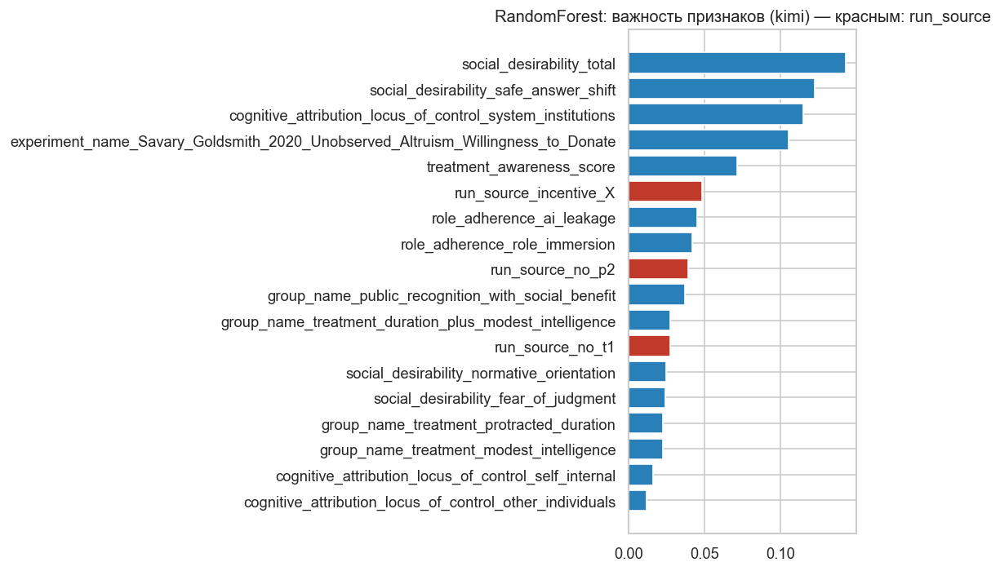

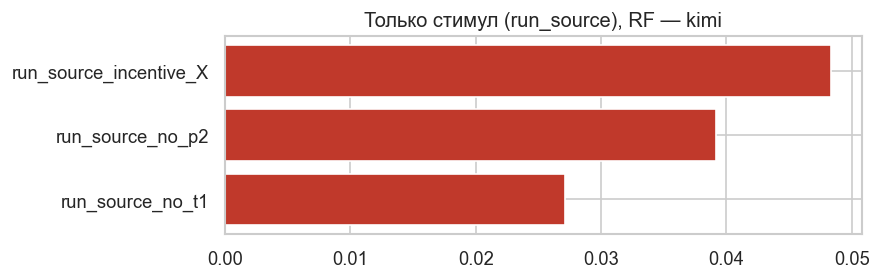

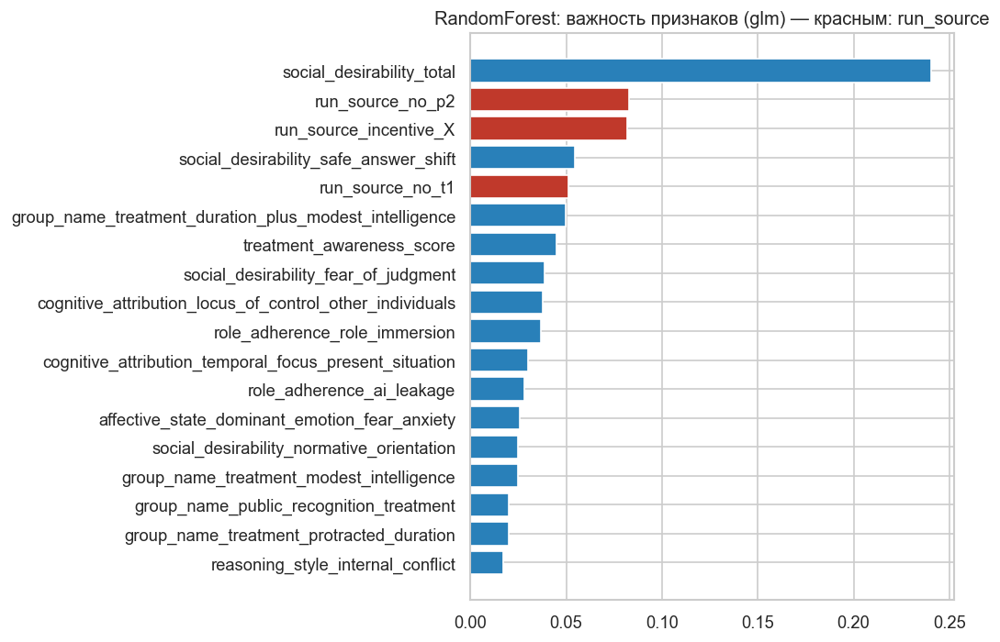

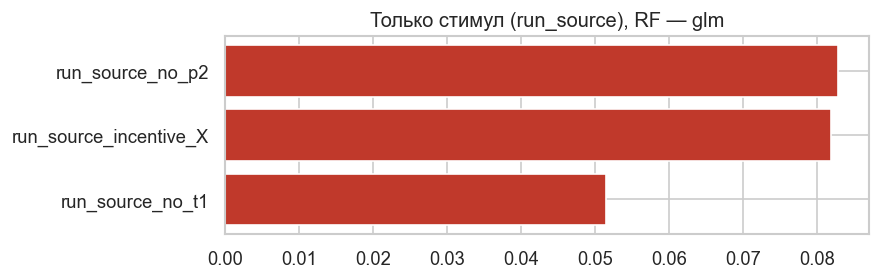

  model_tag  n_rows  rf_cv_r2_mean  rf_cv_r2_std  rf_cv_mae_mean  \
0      kimi    1400       0.048074      0.190751        0.410395   
1       glm    1386      -1.056646      1.363507        0.049064   

   rf_cv_mae_std  
0       0.050947  
1       0.018991  


In [35]:
print("\n" + "=" * 80)
print("Stimulus (run_source) as predictor — separate RF/Ridge per LLM (kimi, glm)")
print("=" * 80)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

TARGET_COL = "epistemic_certainty"
_LEN_EXCLUDE = {"reasoning_len_chars", "reasoning_len_words"}

MODELS_USE = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
]


def _short_model(m: str) -> str:
    ms = str(m).lower()
    if "kimi" in ms:
        return "kimi"
    if "glm" in ms:
        return "glm"
    return str(m).replace("/", "_")[:24]


def build_xy_stimulus_predictor(full_df: pd.DataFrame, target_col: str):
    """Markup + experiment_name + group_name + run_source (все дамми)."""
    num_cols = [
        c
        for c in (ordinal_vars_ml + binary_vars + ["social_desirability_total"])
        if c not in _LEN_EXCLUDE and c != target_col and c in full_df.columns
    ]
    cat_markup = [c for c in categorical_vars if c in full_df.columns]
    treat_cols = cat_markup + ["experiment_name", "group_name", "run_source"]
    X_num = full_df[num_cols].apply(pd.to_numeric, errors="coerce")
    X_cat = pd.get_dummies(
        full_df[treat_cols].astype(str),
        prefix=treat_cols,
        drop_first=True,
        dtype=float,
    )
    X = pd.concat([X_num, X_cat], axis=1)
    y = pd.to_numeric(full_df[target_col], errors="coerce")
    valid = X.notna().all(axis=1) & y.notna()
    return X.loc[valid], y.loc[valid], num_cols


rows_summary = []

for mod in MODELS_USE:
    sub = df[df["model"].astype(str) == mod].copy()
    tag = _short_model(mod)
    X, y, num_cols = build_xy_stimulus_predictor(sub, TARGET_COL)
    if len(X) < 80:
        print(f"skip {tag}: n={len(X)}")
        continue

    # Ridge: стандартизуем только числовые колонки разметки; дамми не трогаем
    X_lin = X.copy()
    for c in num_cols:
        mu = X_lin[c].mean()
        sd = X_lin[c].std(ddof=0)
        X_lin[c] = (X_lin[c] - mu) / (sd if sd > 1e-12 else 1.0)

    ridge = Ridge(alpha=1.0, random_state=42)
    ridge.fit(X_lin, y)
    coef_df = (
        pd.DataFrame({"feature": X.columns, "ridge_coef": ridge.coef_})
        .sort_values("ridge_coef", key=np.abs, ascending=False)
    )
    coef_df.to_csv(f"stimulus_predictor_{tag}_ridge_coef.csv", index=False)

    stim_mask = coef_df["feature"].astype(str).str.startswith("run_source_")
    coef_df.loc[stim_mask].to_csv(
        f"stimulus_predictor_{tag}_ridge_stimulus_only.csv", index=False
    )

    rf = RandomForestRegressor(
        n_estimators=400,
        max_depth=14,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )
    rf.fit(X, y)
    imp_df = (
        pd.DataFrame({"feature": X.columns, "rf_importance": rf.feature_importances_})
        .sort_values("rf_importance", ascending=False)
    )
    imp_df.to_csv(f"stimulus_predictor_{tag}_rf_importance.csv", index=False)

    cv_r2 = cross_val_score(rf, X, y, cv=5, scoring="r2", n_jobs=-1)
    cv_mae = -cross_val_score(
        rf, X, y, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1
    )
    rows_summary.append(
        {
            "model_tag": tag,
            "n_rows": len(X),
            "rf_cv_r2_mean": float(cv_r2.mean()),
            "rf_cv_r2_std": float(cv_r2.std()),
            "rf_cv_mae_mean": float(cv_mae.mean()),
            "rf_cv_mae_std": float(cv_mae.std()),
        }
    )

    top = imp_df.head(18).iloc[::-1]
    colors = [
        "#c0392b" if str(f).startswith("run_source_") else "#2980b9"
        for f in top["feature"]
    ]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top["feature"].astype(str), top["rf_importance"], color=colors)
    ax.set_title(
        f"RandomForest: важность признаков ({tag}) — красным: run_source"
    )
    plt.tight_layout()
    plt.savefig(f"fig_stimulus_predictor_{tag}_rf_top.png", dpi=160, bbox_inches="tight")
    plt.show()

    stim_imp = imp_df[imp_df["feature"].astype(str).str.startswith("run_source_")]
    if len(stim_imp):
        fig2, ax2 = plt.subplots(figsize=(7.5, max(2.5, 0.45 * len(stim_imp))))
        sl = stim_imp.iloc[::-1]
        ax2.barh(sl["feature"].astype(str), sl["rf_importance"], color="#c0392b")
        ax2.set_title(f"Только стимул (run_source), RF — {tag}")
        plt.tight_layout()
        plt.savefig(
            f"fig_stimulus_predictor_{tag}_stimulus_only.png",
            dpi=160,
            bbox_inches="tight",
        )
        plt.show()

summary_df = pd.DataFrame(rows_summary)
summary_df.to_csv("stimulus_predictor_by_model_cv_summary.csv", index=False)
print(summary_df)




10. TREE-BASED MODELS
Random Forest CV AUC: 0.9134 ± 0.0094

Top 15 features (permutation importance):
                                           feature  importance_mdi  importance_perm_mean  importance_perm_std
              social_desirability_fear_of_judgment        0.066289              0.214021             0.006440
             reasoning_style_primary_strategy_none        0.000000              0.022153             0.000949
                   affective_state_valence_neutral        0.039506              0.021700             0.001279
                         treatment_awareness_score        0.027581              0.014222             0.001291
        cognitive_attribution_locus_of_control_nan        0.000000              0.014020             0.000816
                         social_desirability_total        0.099361              0.012094             0.000976
       cognitive_attribution_locus_of_control_none        0.000000              0.011730             0.000690
         social_

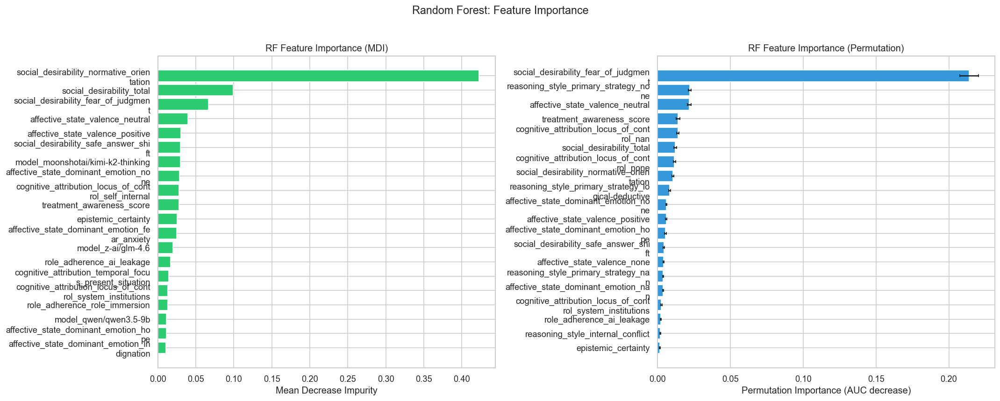


Gradient Boosting CV AUC: 0.9400 ± 0.0080

Top 15 features (Gradient Boosting):
                                             feature  importance_gb
           social_desirability_normative_orientation       0.460531
                   model_moonshotai/kimi-k2-thinking       0.062527
cognitive_attribution_locus_of_control_self_internal       0.050383
                           social_desirability_total       0.050267
                           treatment_awareness_score       0.045742
                                 epistemic_certainty       0.043553
                                  model_z-ai/glm-4.6       0.040329
                social_desirability_fear_of_judgment       0.039232
                           role_adherence_ai_leakage       0.026644
               affective_state_dominant_emotion_none       0.025537
               social_desirability_safe_answer_shift       0.025236
                       role_adherence_role_immersion       0.022732
                               mode

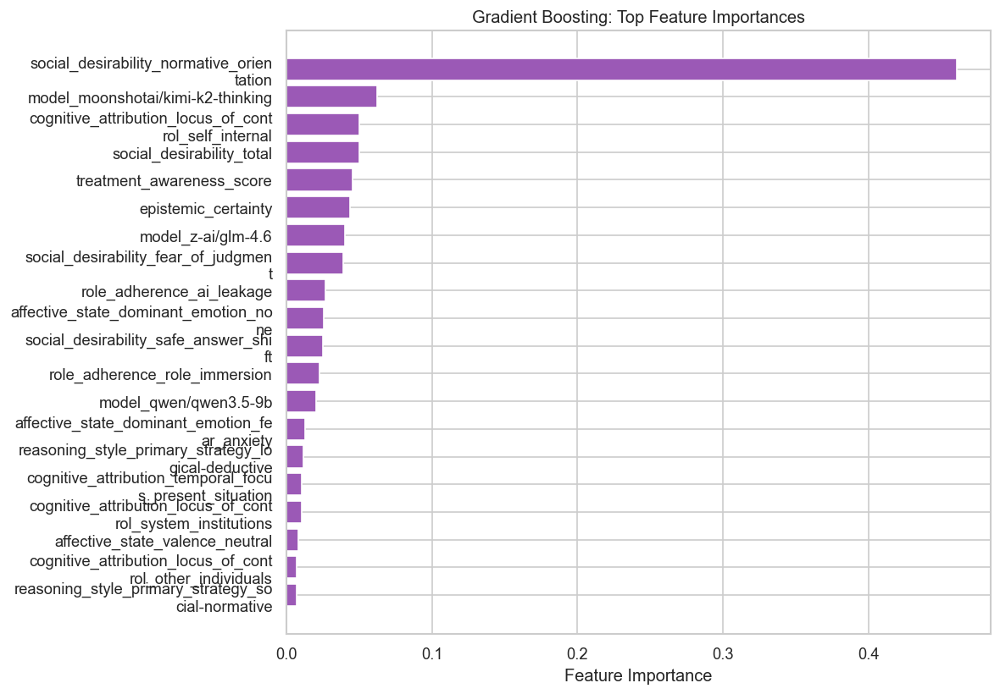


--- Model Comparison ---
                   Model  CV_AUC_mean  CV_AUC_std
Logistic Regression (L2)     0.890160    0.006844
           Random Forest     0.913385    0.009422
       Gradient Boosting     0.940017    0.007994


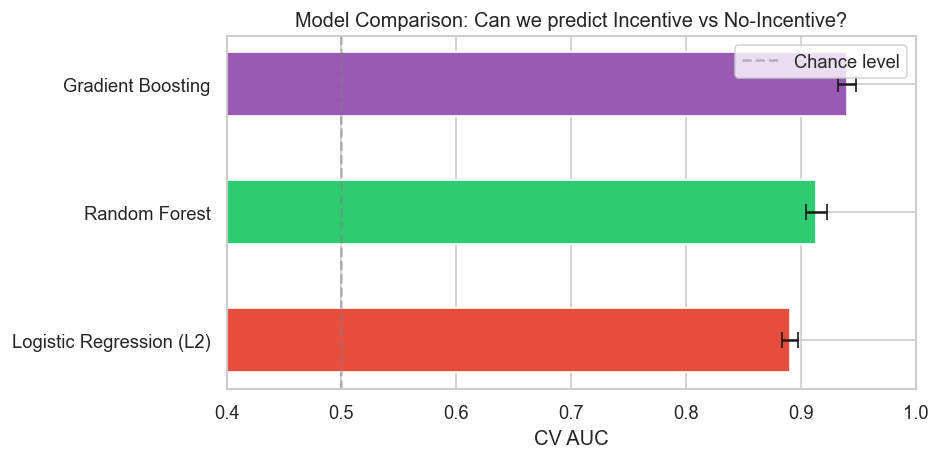

In [36]:
print("\n" + "=" * 80)
print("10. TREE-BASED MODELS")
print("=" * 80)

# ── 10a. Random Forest ──
rf = RandomForestClassifier(n_estimators=500, max_depth=8, min_samples_leaf=10,
                             random_state=42, n_jobs=-1, class_weight="balanced")
scores_rf = cross_val_score(rf, X_scaled, y_clean, cv=cv, scoring="roc_auc")
print(f"Random Forest CV AUC: {scores_rf.mean():.4f} ± {scores_rf.std():.4f}")

rf.fit(X_scaled, y_clean)

# Feature importance (MDI)
fi_rf = pd.DataFrame({
    "feature": X_clean.columns,
    "importance_mdi": rf.feature_importances_
}).sort_values("importance_mdi", ascending=False)

# Permutation importance
perm_imp = permutation_importance(rf, X_scaled, y_clean, n_repeats=20,
                                   random_state=42, scoring="roc_auc", n_jobs=-1)
fi_rf["importance_perm_mean"] = perm_imp.importances_mean
fi_rf["importance_perm_std"] = perm_imp.importances_std
fi_rf = fi_rf.sort_values("importance_perm_mean", ascending=False)
fi_rf.to_csv("random_forest_feature_importance.csv", index=False)

print("\nTop 15 features (permutation importance):")
print(fi_rf.head(15).to_string(index=False))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
top_n = 20

# MDI
ax = axes[0]
top_mdi = fi_rf.sort_values("importance_mdi", ascending=True).tail(top_n)
ax.barh(range(top_n), top_mdi["importance_mdi"], color="#2ecc71", edgecolor="white")
ax.set_yticks(range(top_n))
ax.set_yticklabels([textwrap.fill(f, 35) for f in top_mdi["feature"]])
ax.set_xlabel("Mean Decrease Impurity")
ax.set_title("RF Feature Importance (MDI)")

# Permutation
ax = axes[1]
top_perm = fi_rf.sort_values("importance_perm_mean", ascending=True).tail(top_n)
ax.barh(range(top_n), top_perm["importance_perm_mean"], color="#3498db", edgecolor="white",
        xerr=top_perm["importance_perm_std"].values, capsize=2)
ax.set_yticks(range(top_n))
ax.set_yticklabels([textwrap.fill(f, 35) for f in top_perm["feature"]])
ax.set_xlabel("Permutation Importance (AUC decrease)")
ax.set_title("RF Feature Importance (Permutation)")

plt.suptitle("Random Forest: Feature Importance", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_11_rf_feature_importance.png", bbox_inches="tight")
plt.show()

# ── 10b. Gradient Boosting ──
gb = GradientBoostingClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    min_samples_leaf=10, subsample=0.8, random_state=42
)
scores_gb = cross_val_score(gb, X_scaled, y_clean, cv=cv, scoring="roc_auc")
print(f"\nGradient Boosting CV AUC: {scores_gb.mean():.4f} ± {scores_gb.std():.4f}")

gb.fit(X_scaled, y_clean)

fi_gb = pd.DataFrame({
    "feature": X_clean.columns,
    "importance_gb": gb.feature_importances_
}).sort_values("importance_gb", ascending=False)
fi_gb.to_csv("gradient_boosting_feature_importance.csv", index=False)

print("\nTop 15 features (Gradient Boosting):")
print(fi_gb.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 7))
top_gb = fi_gb.sort_values("importance_gb", ascending=True).tail(top_n)
ax.barh(range(len(top_gb)), top_gb["importance_gb"], color="#9b59b6", edgecolor="white")
ax.set_yticks(range(len(top_gb)))
ax.set_yticklabels([textwrap.fill(f, 35) for f in top_gb["feature"]])
ax.set_xlabel("Feature Importance")
ax.set_title("Gradient Boosting: Top Feature Importances")
plt.tight_layout()
plt.savefig("fig_12_gb_feature_importance.png", bbox_inches="tight")
plt.show()

# ── 10c. Model comparison summary ──
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression (L2)", "Random Forest", "Gradient Boosting"],
    "CV_AUC_mean": [scores_lr.mean(), scores_rf.mean(), scores_gb.mean()],
    "CV_AUC_std": [scores_lr.std(), scores_rf.std(), scores_gb.std()],
})
print("\n--- Model Comparison ---")
print(model_comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#e74c3c", "#2ecc71", "#9b59b6"]
ax.barh(model_comparison["Model"], model_comparison["CV_AUC_mean"],
        xerr=model_comparison["CV_AUC_std"], color=colors, edgecolor="white",
        capsize=5, height=0.5)
ax.set_xlabel("CV AUC")
ax.set_title("Model Comparison: Can we predict Incentive vs No-Incentive?")
ax.axvline(0.5, color="gray", linestyle="--", alpha=0.5, label="Chance level")
ax.set_xlim(0.4, 1.0)
ax.legend()
plt.tight_layout()
plt.savefig("fig_13_model_comparison.png", bbox_inches="tight")
plt.show()




11. ROC CURVES


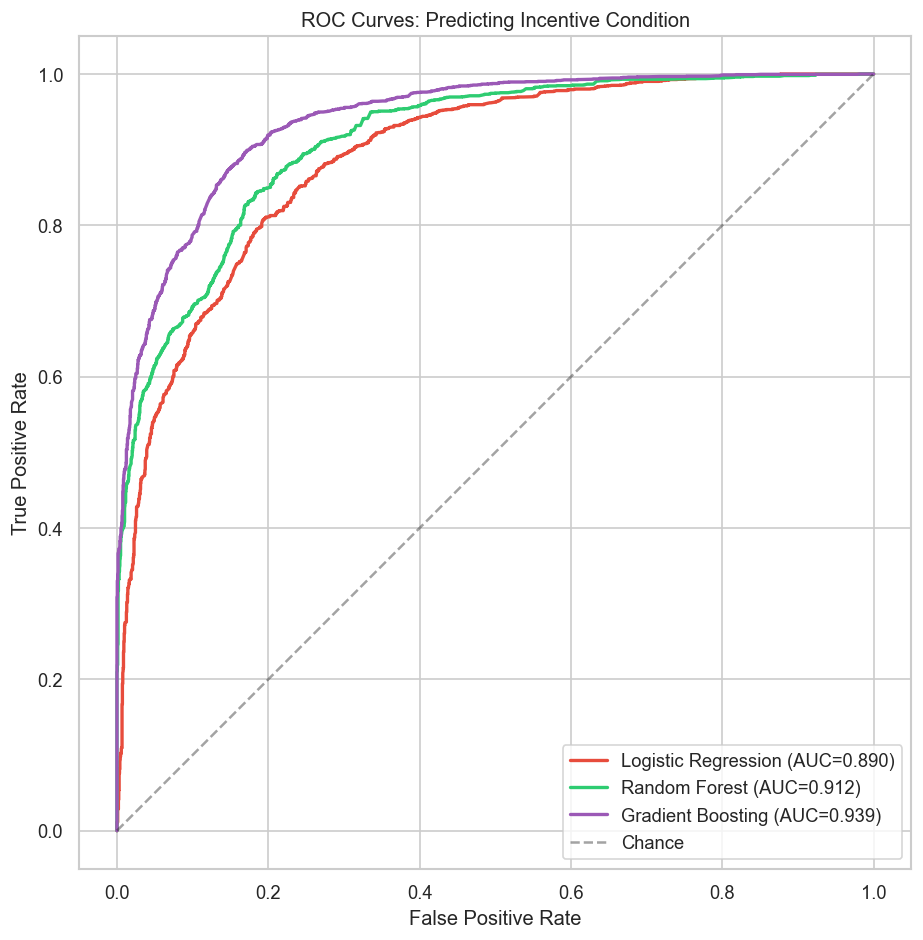

In [37]:
print("\n" + "=" * 80)
print("11. ROC CURVES")
print("=" * 80)

fig, ax = plt.subplots(figsize=(8, 8))

models_dict = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=500, max_depth=8,
                                             min_samples_leaf=10, random_state=42,
                                             n_jobs=-1, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, max_depth=4,
                                                     learning_rate=0.05,
                                                     min_samples_leaf=10,
                                                     subsample=0.8, random_state=42),
}

colors_roc = ["#e74c3c", "#2ecc71", "#9b59b6"]

for (name, clf), color in zip(models_dict.items(), colors_roc):
    # Use cross-validated predictions
    from sklearn.model_selection import cross_val_predict
    y_proba = cross_val_predict(clf, X_scaled, y_clean, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_clean, y_proba)
    auc_val = roc_auc_score(y_clean, y_proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC={auc_val:.3f})")

ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves: Predicting Incentive Condition")
ax.legend(loc="lower right")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("fig_14_roc_curves.png", bbox_inches="tight")
plt.show()


### 9c. Деревья / бустинг / логит отдельно по `(model, experiment_name)`

Для каждой пары **модель × эксперимент** заново собирается матрица признаков (как в п.9, **без** дамми `model` — внутри пары одна модель; **без** `experiment` в X — одна виньетка-эксперимент).  
Пара **пропускается**, если после полного `dropna` по признакам меньше **40** строк (`MIN_TOTAL`) или в меньшем классе **&lt; 10** (`MIN_MINOR_CLASS`, нестабильный Stratified K-fold). Для остальных: `LogisticRegression`, `RandomForest`, `GradientBoosting` + `StratifiedKFold` (число сплитов = `min(5, n_minority_class)`).

In [38]:
print("\n" + "=" * 80)
print("9c. Tree / boosting / logistic BY MODEL × EXPERIMENT")
print("=" * 80)

from sklearn.model_selection import StratifiedKFold, cross_val_score

MIN_MINOR_CLASS = 10   # ниже — не считаем (нестабильный StratifiedKFold)
MIN_TOTAL = 40         # минимум строк после полного случая по признакам

df_me = df.copy()
df_me["condition_bin"] = (df_me["condition"] == "incentive").astype(int)

models_u = sorted(df_me["model"].dropna().unique())
exps_u = sorted(df_me["experiment_name"].dropna().unique())

rows_me = []

for m in models_u:
    for exp in exps_u:
        sub = df_me[(df_me["model"] == m) & (df_me["experiment_name"] == exp)].copy()

        cat_d = pd.get_dummies(
            sub[categorical_vars], prefix=categorical_vars, drop_first=True, dtype=int
        )
        Xn = sub[feature_cols_numeric].copy()
        Xb = pd.concat([Xn, cat_d], axis=1)
        yb = sub["condition_bin"]
        vm = Xb.notna().all(axis=1) & yb.notna()
        Xb = Xb.loc[vm].reset_index(drop=True)
        yb = yb.loc[vm].reset_index(drop=True)

        n_inc = int((yb == 1).sum())
        n_no = int((yb == 0).sum())
        n_minor = min(n_inc, n_no)
        n_tot = len(Xb)

        if n_tot < MIN_TOTAL:
            rows_me.append({
                "model": m,
                "experiment_name": exp,
                "n_rows_after_dropna": n_tot,
                "n_incentive": n_inc,
                "n_no_incentive": n_no,
                "lr_auc_mean": np.nan,
                "rf_auc_mean": np.nan,
                "gb_auc_mean": np.nan,
                "cv_splits": np.nan,
                "status": f"skip: n_after_dropna<{MIN_TOTAL}",
            })
            continue

        if n_minor < MIN_MINOR_CLASS:
            rows_me.append({
                "model": m,
                "experiment_name": exp,
                "n_rows_after_dropna": n_tot,
                "n_incentive": n_inc,
                "n_no_incentive": n_no,
                "lr_auc_mean": np.nan,
                "rf_auc_mean": np.nan,
                "gb_auc_mean": np.nan,
                "cv_splits": np.nan,
                "status": f"skip: minority_class={n_minor}<{MIN_MINOR_CLASS}",
            })
            continue

        n_splits = int(min(5, n_minor))
        if n_splits < 2:
            rows_me.append({
                "model": m,
                "experiment_name": exp,
                "n_rows_after_dropna": n_tot,
                "n_incentive": n_inc,
                "n_no_incentive": n_no,
                "lr_auc_mean": np.nan,
                "rf_auc_mean": np.nan,
                "gb_auc_mean": np.nan,
                "cv_splits": np.nan,
                "status": "skip: cannot stratify",
            })
            continue

        cv_m = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        scaler_m = StandardScaler()
        Xs = scaler_m.fit_transform(Xb.astype(float))

        lr_m = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
        rf_m = RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_leaf=5,
            random_state=42, n_jobs=-1, class_weight="balanced",
        )
        gb_m = GradientBoostingClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.05,
            min_samples_leaf=5, subsample=0.8, random_state=42,
        )

        try:
            auc_lr = cross_val_score(lr_m, Xs, yb, cv=cv_m, scoring="roc_auc")
            auc_rf = cross_val_score(rf_m, Xs, yb, cv=cv_m, scoring="roc_auc")
            auc_gb = cross_val_score(gb_m, Xs, yb, cv=cv_m, scoring="roc_auc")
            stat = "ok"
        except Exception as ex:
            auc_lr = auc_rf = auc_gb = np.nan
            stat = f"error: {type(ex).__name__}"

        rows_me.append({
            "model": m,
            "experiment_name": exp,
            "n_rows_after_dropna": len(Xb),
            "n_incentive": n_inc,
            "n_no_incentive": n_no,
            "lr_auc_mean": float(np.nanmean(auc_lr)) if stat == "ok" else np.nan,
            "lr_auc_std": float(np.nanstd(auc_lr)) if stat == "ok" else np.nan,
            "rf_auc_mean": float(np.nanmean(auc_rf)) if stat == "ok" else np.nan,
            "rf_auc_std": float(np.nanstd(auc_rf)) if stat == "ok" else np.nan,
            "gb_auc_mean": float(np.nanmean(auc_gb)) if stat == "ok" else np.nan,
            "gb_auc_std": float(np.nanstd(auc_gb)) if stat == "ok" else np.nan,
            "cv_splits": n_splits,
            "status": stat,
        })

df_me_results = pd.DataFrame(rows_me).sort_values(
    ["status", "experiment_name", "model"], ascending=[True, True, True]
)

print("\n--- Per model × experiment (CV ROC-AUC) ---")
display(df_me_results)

ok_only = df_me_results[df_me_results["status"] == "ok"].copy()
if len(ok_only):
    print("\nPairs with OK fits:", len(ok_only))
    ok_only.to_csv("condition_classifier_by_model_experiment.csv", index=False)
    print("Saved: condition_classifier_by_model_experiment.csv")
else:
    print("No pair passed filters.")



9c. Tree / boosting / logistic BY MODEL × EXPERIMENT

--- Per model × experiment (CV ROC-AUC) ---


,model,experiment_name,n_rows_after_dropna,n_incentive,n_no_incentive,lr_auc_mean,lr_auc_std,rf_auc_mean,rf_auc_std,gb_auc_mean,gb_auc_std,cv_splits,status
0,minimax/minimax-m2.5,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,600,400,200,0.942250,0.025790,0.932562,0.026385,0.933594,0.023938,5,ok
2,moonshotai/kimi-k2-thinking,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,800,400,400,0.947469,0.016447,0.953391,0.015375,0.954281,0.015392,5,ok
4,qwen/qwen3.5-9b,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,414,214,200,0.946208,0.012461,0.948371,0.017410,0.946253,0.023323,5,ok
6,z-ai/glm-4.6,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,799,399,400,0.877330,0.019762,0.892529,0.020113,0.886561,0.026403,5,ok
1,minimax/minimax-m2.5,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,450,300,150,0.922500,0.022910,0.930056,0.032163,0.936556,0.024295,5,ok
3,moonshotai/kimi-k2-thinking,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,600,300,300,0.936056,0.010328,0.937611,0.014749,0.933000,0.012203,5,ok
5,qwen/qwen3.5-9b,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,305,157,148,0.953420,0.031727,0.954166,0.022105,0.952216,0.024238,5,ok
7,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,587,300,287,0.947887,0.019714,0.948283,0.009100,0.950119,0.010076,5,ok



Pairs with OK fits: 8
Saved: condition_classifier_by_model_experiment.csv



12. MIXED-EFFECTS MODELS (Condition → Outcome, controlling for model & experiment)
  treatment_awareness_score                      β=-0.0897  p=0.019247 * (simplified)
  incentive_awareness_score                      β=+2.1742  p=0.000000 *** (simplified)
  epistemic_certainty                            β=+0.0097  p=0.531236  (simplified)
  social_desirability_total                      β=-0.3858  p=0.000000 *** (simplified)
  reasoning_style_internal_conflict              β=+0.0182  p=0.000015 *** (simplified)
  role_adherence_ai_leakage                      β=+0.1427  p=0.000000 *** (simplified)
  role_adherence_role_immersion                  β=-0.0817  p=0.000000 *** (simplified)
  social_desirability_safe_answer_shift          β=+0.0751  p=0.000017 *** (simplified)

--- Mixed-effects results ---
                              outcome  coef_condition       se          z      p_value    n  converged  p_adjusted_fdr  significant_fdr05
            treatment_awareness_score       -0.0

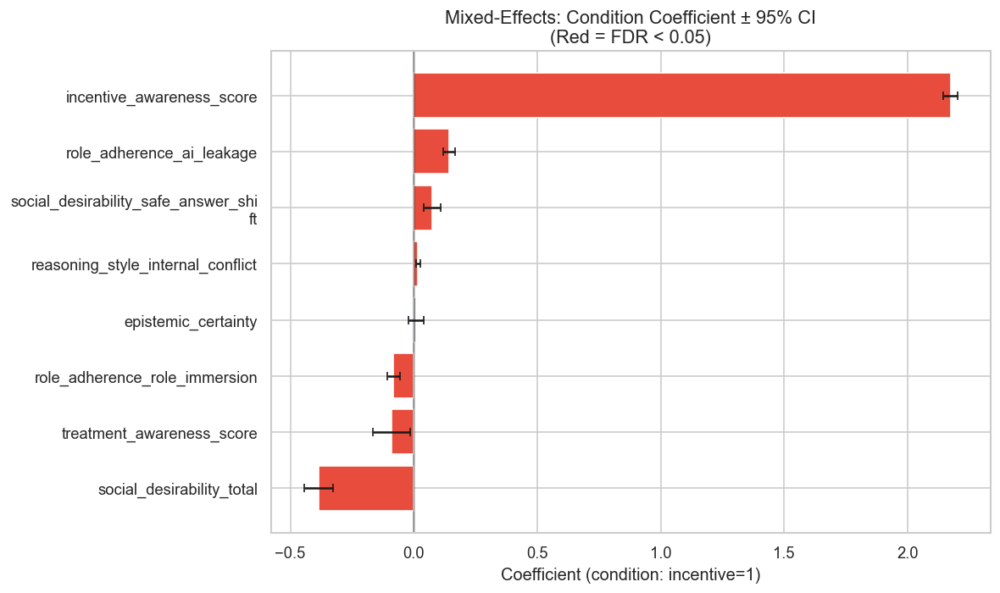


13. INTERACTION ANALYSIS: CONDITION × MODEL
  incentive_awareness_score: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    incentive_awareness_score ~ condition_bin * C(model)
                                                ^^^^^^^^
  social_desirability_total: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    social_desirability_total ~ condition_bin * C(model)
                                                ^^^^^^^^
  epistemic_certainty: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    epistemic_certainty ~ condition_bin * C(model)
                                          ^^^^^^^^
  treatment_awareness_score: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    treatment_awareness_score ~ condition_bin * C(model)
                                                ^^^^^^^^
  role_adherence_role_imm

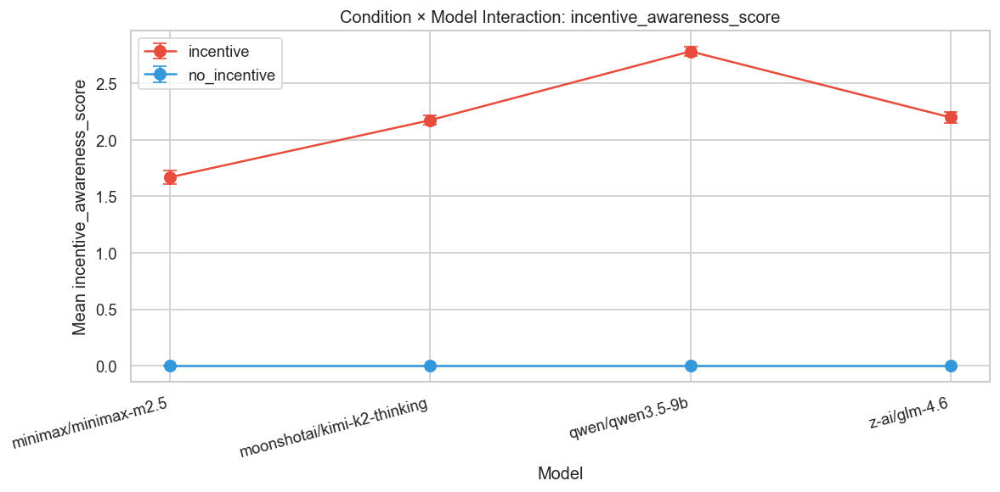

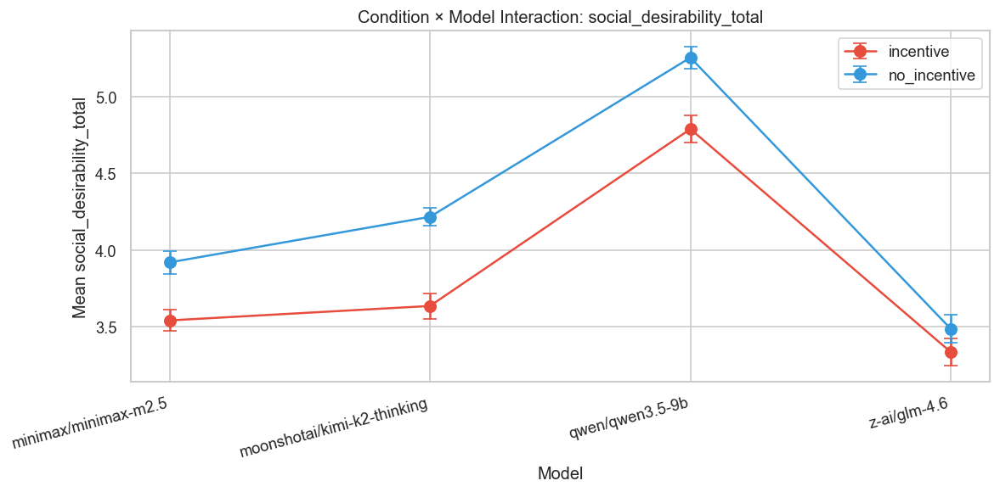

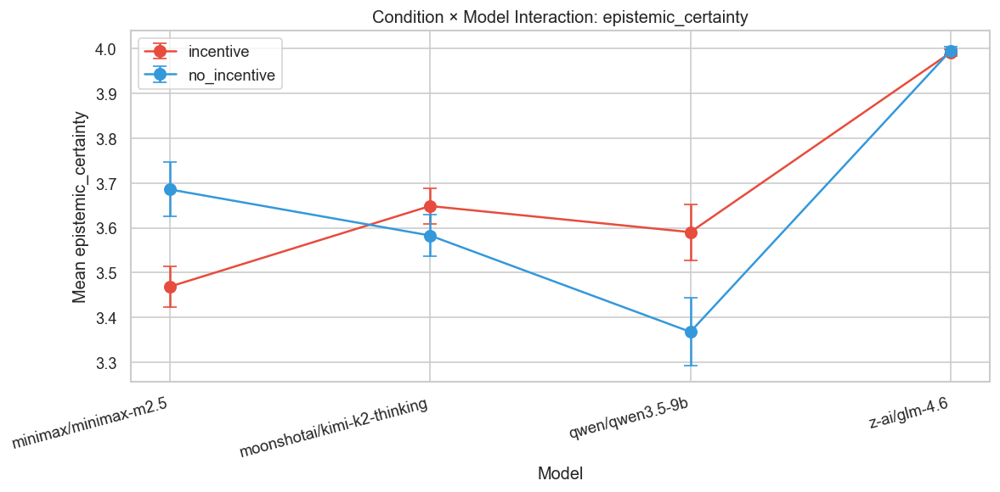

In [39]:
print("\n" + "=" * 80)
print("12. MIXED-EFFECTS MODELS (Condition → Outcome, controlling for model & experiment)")
print("=" * 80)

# For key outcome variables, fit mixed-effects models with random intercepts for
# model and experiment.

key_outcomes = [
    "treatment_awareness_score",
    "incentive_awareness_score",
    "epistemic_certainty",
    "social_desirability_total",
    "reasoning_style_internal_conflict",
    "role_adherence_ai_leakage",
    "role_adherence_role_immersion",
    "social_desirability_safe_answer_shift",
]

df_mixed = df.copy()
df_mixed["condition_bin"] = (df_mixed["condition"] == "incentive").astype(int)

mixed_results = []
for outcome in key_outcomes:
    df_tmp = df_mixed[["condition_bin", outcome, "model", "experiment_name"]].dropna()
    if len(df_tmp) < 50:
        print(f"  {outcome}: skipped (n={len(df_tmp)})")
        continue
    try:
        formula = f"{outcome} ~ condition_bin"
        md = smf.mixedlm(formula, df_tmp, groups=df_tmp["model"],
                          re_formula="~1",
                          vc_formula={"experiment_name": "0 + C(experiment_name)"})
        mdf = md.fit(reml=True)

        mixed_results.append({
            "outcome": outcome,
            "coef_condition": mdf.params.get("condition_bin", np.nan),
            "se": mdf.bse.get("condition_bin", np.nan),
            "z": mdf.tvalues.get("condition_bin", np.nan),
            "p_value": mdf.pvalues.get("condition_bin", np.nan),
            "n": len(df_tmp),
            "converged": mdf.converged
        })
        sig = "***" if mdf.pvalues.get("condition_bin", 1) < 0.001 else \
              "**" if mdf.pvalues.get("condition_bin", 1) < 0.01 else \
              "*" if mdf.pvalues.get("condition_bin", 1) < 0.05 else ""
        print(f"  {outcome:45s}  β={mdf.params.get('condition_bin', np.nan):+.4f}  "
              f"p={mdf.pvalues.get('condition_bin', np.nan):.6f} {sig}")
    except Exception as e:
        # Fallback: simpler model without vc_formula
        try:
            md = smf.mixedlm(formula, df_tmp, groups=df_tmp["model"])
            mdf = md.fit(reml=True)
            mixed_results.append({
                "outcome": outcome,
                "coef_condition": mdf.params.get("condition_bin", np.nan),
                "se": mdf.bse.get("condition_bin", np.nan),
                "z": mdf.tvalues.get("condition_bin", np.nan),
                "p_value": mdf.pvalues.get("condition_bin", np.nan),
                "n": len(df_tmp),
                "converged": mdf.converged
            })
            sig = "***" if mdf.pvalues.get("condition_bin", 1) < 0.001 else \
                  "**" if mdf.pvalues.get("condition_bin", 1) < 0.01 else \
                  "*" if mdf.pvalues.get("condition_bin", 1) < 0.05 else ""
            print(f"  {outcome:45s}  β={mdf.params.get('condition_bin', np.nan):+.4f}  "
                  f"p={mdf.pvalues.get('condition_bin', np.nan):.6f} {sig} (simplified)")
        except Exception as e2:
            print(f"  {outcome}: mixed model failed — {e2}")

df_mixed_res = pd.DataFrame(mixed_results)
if len(df_mixed_res) > 0:
    reject_m, p_adj_m, _, _ = multipletests(df_mixed_res["p_value"].fillna(1), method="fdr_bh")
    df_mixed_res["p_adjusted_fdr"] = p_adj_m
    df_mixed_res["significant_fdr05"] = reject_m
    df_mixed_res.to_csv("mixed_effects_results.csv", index=False)
    print("\n--- Mixed-effects results ---")
    print(df_mixed_res.to_string(index=False))

    # Forest plot of mixed-effects coefficients
    fig, ax = plt.subplots(figsize=(10, 6))
    df_plot = df_mixed_res.sort_values("coef_condition")
    y_pos = range(len(df_plot))
    colors_me = ["#e74c3c" if s else "#95a5a6" for s in df_plot["significant_fdr05"]]
    ax.barh(y_pos, df_plot["coef_condition"], xerr=df_plot["se"] * 1.96,
            color=colors_me, edgecolor="white", capsize=3)
    ax.axvline(0, color="black", linestyle="-", alpha=0.3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([textwrap.fill(o, 35) for o in df_plot["outcome"]])
    ax.set_xlabel("Coefficient (condition: incentive=1)")
    ax.set_title("Mixed-Effects: Condition Coefficient ± 95% CI\n(Red = FDR < 0.05)", fontsize=13)
    plt.tight_layout()
    plt.savefig("fig_15_mixed_effects_coefficients.png", bbox_inches="tight")
    plt.show()


# =============================================================================
# 13. INTERACTION ANALYSIS: CONDITION × MODEL
# =============================================================================
print("\n" + "=" * 80)
print("13. INTERACTION ANALYSIS: CONDITION × MODEL")
print("=" * 80)

df_inter = df.copy()
df_inter["condition_bin"] = (df_inter["condition"] == "incentive").astype(int)

interaction_results = []
for outcome in ["incentive_awareness_score", "social_desirability_total",
                 "epistemic_certainty", "treatment_awareness_score",
                 "role_adherence_role_immersion"]:
    df_tmp = df_inter[[outcome, "condition_bin", "model"]].dropna()
    if len(df_tmp) < 50:
        continue
    try:
        formula = f"{outcome} ~ condition_bin * C(model)"
        ols_model = smf.ols(formula, data=df_tmp).fit()
        # ANOVA table for interaction
        anova_table = sm.stats.anova_lm(ols_model, typ=2)
        print(f"\n--- {outcome} ---")
        print(anova_table.round(4).to_string())
        interaction_results.append({
            "outcome": outcome,
            "interaction_F": anova_table.loc["condition_bin:C(model)", "F"] if "condition_bin:C(model)" in anova_table.index else np.nan,
            "interaction_p": anova_table.loc["condition_bin:C(model)", "PR(>F)"] if "condition_bin:C(model)" in anova_table.index else np.nan,
            "R_squared": ols_model.rsquared,
            "R_squared_adj": ols_model.rsquared_adj,
        })
    except Exception as e:
        print(f"  {outcome}: interaction model failed — {e}")

df_inter_res = pd.DataFrame(interaction_results)
if len(df_inter_res) > 0:
    df_inter_res.to_csv("interaction_condition_model.csv", index=False)
    print("\n--- Interaction summary ---")
    print(df_inter_res.to_string(index=False))

# ── 13b. Interaction plots ──
for outcome in ["incentive_awareness_score", "social_desirability_total",
                 "epistemic_certainty"]:
    if outcome not in df.columns:
        continue
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_data = df.groupby(["model", "condition"])[outcome].agg(["mean", "sem"]).reset_index()
    for cond, color in palette_condition.items():
        sub = plot_data[plot_data["condition"] == cond]
        ax.errorbar(sub["model"], sub["mean"], yerr=sub["sem"] * 1.96,
                     fmt="o-", color=color, label=cond, capsize=5, markersize=8)
    ax.set_title(f"Condition × Model Interaction: {outcome}", fontsize=12)
    ax.set_ylabel(f"Mean {outcome}")
    ax.set_xlabel("Model")
    ax.legend()
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(f"fig_16_interaction_{outcome}.png", bbox_inches="tight")
    plt.show()



14. TOPIC ANALYSIS
Total topic mentions: 18282
Unique topics: 6058

--- Top 20 topics (incentive) ---
topic
sleep deprivation as torture/cruel treatment       215
national security vs civil liberties               214
behavioral realism vs moral posturing              141
national security vs human rights                  122
public recognition and social rewards              121
national security vs human rights tradeoff         104
public recognition and social signaling             92
privacy reducing social pressure                    85
small monetary cost                                 80
sleep deprivation as coercive interrogation         75
sleep deprivation as torture/inhumane treatment     73
privacy and reduced social pressure                 72
ticking time bomb framing                           70
social desirability bias in surveys                 64
small monetary cost ($5)                            63
realism vs moral posturing in survey responding     60
public reco

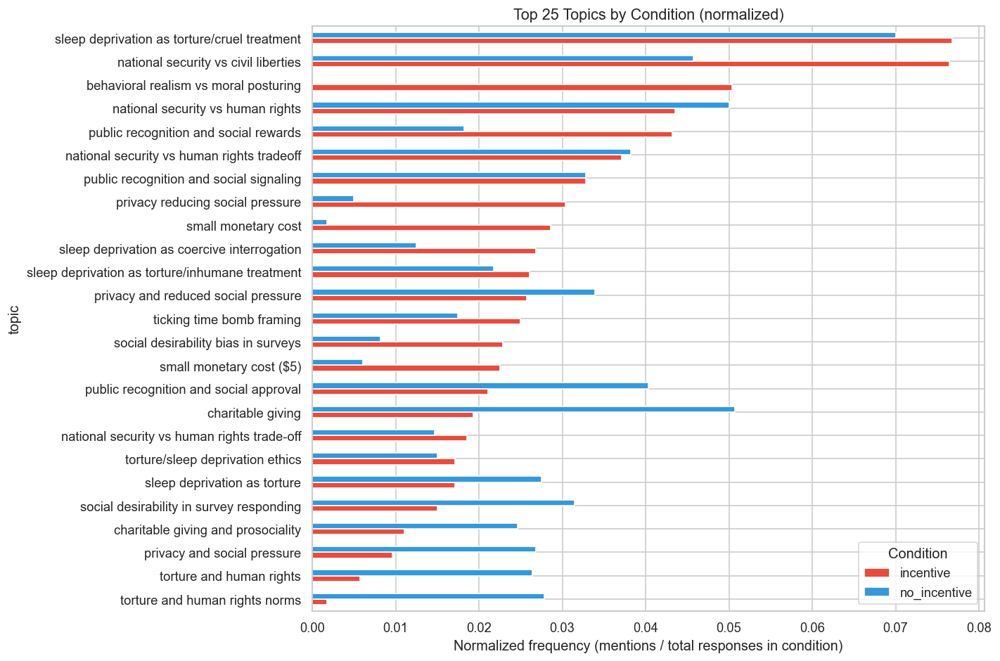

In [40]:
print("\n" + "=" * 80)
print("14. TOPIC ANALYSIS")
print("=" * 80)

# extracted_topics is a list/string of topics
df["topics_str"] = df["extracted_topics"].astype(str)

# Parse topics
import ast

def parse_topics(x):
    """Parse topic strings to list."""
    if pd.isna(x):
        return []
    x = str(x).strip()
    try:
        result = ast.literal_eval(x)
        if isinstance(result, list):
            return [str(t).strip().lower() for t in result]
    except:
        pass
    # fallback: split by comma
    return [t.strip().lower().strip("'\"[]") for t in x.split(",") if t.strip()]

df["topics_list"] = df["extracted_topics"].apply(parse_topics)

# Explode topics
df_topics = df[["condition", "model", "experiment_name", "topics_list"]].explode("topics_list")
df_topics = df_topics.rename(columns={"topics_list": "topic"})
df_topics = df_topics[df_topics["topic"].notna() & (df_topics["topic"] != "")]

print(f"Total topic mentions: {len(df_topics)}")
print(f"Unique topics: {df_topics['topic'].nunique()}")

# Top topics by condition
for cond in ["incentive", "no_incentive"]:
    sub = df_topics[df_topics["condition"] == cond]
    top = sub["topic"].value_counts().head(20)
    print(f"\n--- Top 20 topics ({cond}) ---")
    print(top.to_string())

# ── 14a. Topic frequency comparison ──
topic_counts = pd.crosstab(df_topics["topic"], df_topics["condition"])
topic_counts["total"] = topic_counts.sum(axis=1)
topic_counts = topic_counts[topic_counts["total"] >= 10].sort_values("total", ascending=False)

# Chi-squared per topic
topic_chi2_results = []
for topic in topic_counts.index:
    ct = pd.crosstab(df_topics["topic"] == topic, df_topics["condition"])
    if ct.shape == (2, 2):
        chi2, p, _, _ = chi2_contingency(ct)
        topic_chi2_results.append({
            "topic": topic, "chi2": chi2, "p_value": p,
            "count_inc": topic_counts.loc[topic, "incentive"] if "incentive" in topic_counts.columns else 0,
            "count_no": topic_counts.loc[topic, "no_incentive"] if "no_incentive" in topic_counts.columns else 0,
        })

df_topic_chi2 = pd.DataFrame(topic_chi2_results).sort_values("p_value")
if len(df_topic_chi2) > 0:
    reject_t, p_adj_t, _, _ = multipletests(df_topic_chi2["p_value"], method="fdr_bh")
    df_topic_chi2["p_adjusted_fdr"] = p_adj_t
    df_topic_chi2["significant_fdr05"] = reject_t
    df_topic_chi2.to_csv("topic_chi2_comparison.csv", index=False)
    print("\n--- Topics significantly different between conditions (FDR < 0.05) ---")
    sig_topics = df_topic_chi2[df_topic_chi2["significant_fdr05"]]
    print(sig_topics.to_string(index=False))

# ── 14b. Topic frequency bar chart ──
top_topics_overall = df_topics["topic"].value_counts().head(25).index
topic_freq = (
    df_topics[df_topics["topic"].isin(top_topics_overall)]
    .groupby(["topic", "condition"])
    .size()
    .unstack(fill_value=0)
)
# Normalize by condition size
n_inc_total = (df["condition"] == "incentive").sum()
n_no_total = (df["condition"] == "no_incentive").sum()
topic_freq_norm = topic_freq.copy()
if "incentive" in topic_freq_norm.columns:
    topic_freq_norm["incentive"] = topic_freq_norm["incentive"] / n_inc_total
if "no_incentive" in topic_freq_norm.columns:
    topic_freq_norm["no_incentive"] = topic_freq_norm["no_incentive"] / n_no_total
topic_freq_norm = topic_freq_norm.sort_values(
    topic_freq_norm.columns[0], ascending=True
)

fig, ax = plt.subplots(figsize=(12, 8))
topic_freq_norm.plot(kind="barh", ax=ax,
                      color=[palette_condition.get(c, "gray") for c in topic_freq_norm.columns],
                      edgecolor="white")
ax.set_xlabel("Normalized frequency (mentions / total responses in condition)")
ax.set_title("Top 25 Topics by Condition (normalized)", fontsize=13)
ax.legend(title="Condition")
plt.tight_layout()
plt.savefig("fig_17_topic_frequencies.png", bbox_inches="tight")
plt.show()




15. EMOTION ANALYSIS

--- Emotion distribution by Model × Condition ---
affective_state_dominant_emotion          empathy_pity  fear_anxiety   hope  indignation    nan   none
model                       condition                                                                 
minimax/minimax-m2.5        incentive            0.001         0.014  0.011        0.000  0.000  0.973
                            no_incentive         0.013         0.000  0.023        0.051  0.000  0.913
moonshotai/kimi-k2-thinking incentive            0.000         0.070  0.001        0.000  0.000  0.929
                            no_incentive         0.030         0.016  0.061        0.001  0.000  0.891
qwen/qwen3.5-9b             incentive            0.000         0.084  0.000        0.000  0.000  0.916
                            no_incentive         0.011         0.006  0.016        0.027  0.003  0.937
z-ai/glm-4.6                incentive            0.001         0.423  0.049        0.000  0.000  0.527


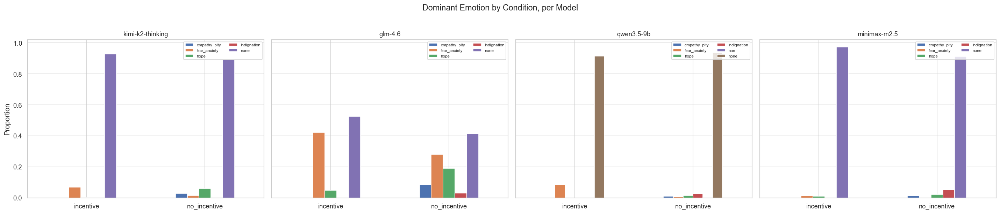

In [41]:
print("\n" + "=" * 80)
print("15. EMOTION ANALYSIS")
print("=" * 80)

# Emotion × Condition × Model
emotion_ct = pd.crosstab(
    [df["model"], df["condition"]],
    df["affective_state_dominant_emotion"],
    normalize="index"
)
print("\n--- Emotion distribution by Model × Condition ---")
print(emotion_ct.round(3).to_string())

fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5), sharey=True)
if len(models) == 1:
    axes = [axes]
for i, model_name in enumerate(models):
    ax = axes[i]
    sub = df[df["model"] == model_name]
    ct = pd.crosstab(sub["condition"], sub["affective_state_dominant_emotion"], normalize="index")
    ct.plot(kind="bar", ax=ax, edgecolor="white")
    ax.set_title(model_name.split("/")[-1], fontsize=11)
    ax.set_ylabel("Proportion" if i == 0 else "")
    ax.set_xlabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.legend(fontsize=7, ncol=2)
plt.suptitle("Dominant Emotion by Condition, per Model", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_18_emotion_by_model_condition.png", bbox_inches="tight")
plt.show()


16. REASONING STRATEGY ANALYSIS

Chi-squared test for reasoning strategy × condition:
  χ² = 268.618, p = 0.000000
reasoning_style_primary_strategy  heuristic-shortcut  logical-deductive  nan  none  social-normative
condition                                                                                           
incentive                                        159               2186    0   330               125
no_incentive                                      27               1880    2   713               178

--- Strategy proportions ---
reasoning_style_primary_strategy          heuristic-shortcut  logical-deductive    nan   none  social-normative
model                       condition                                                                          
minimax/minimax-m2.5        incentive                  0.074              0.864  0.000  0.000             0.061
                            no_incentive               0.011              0.441  0.000  0.500             0.047
mo

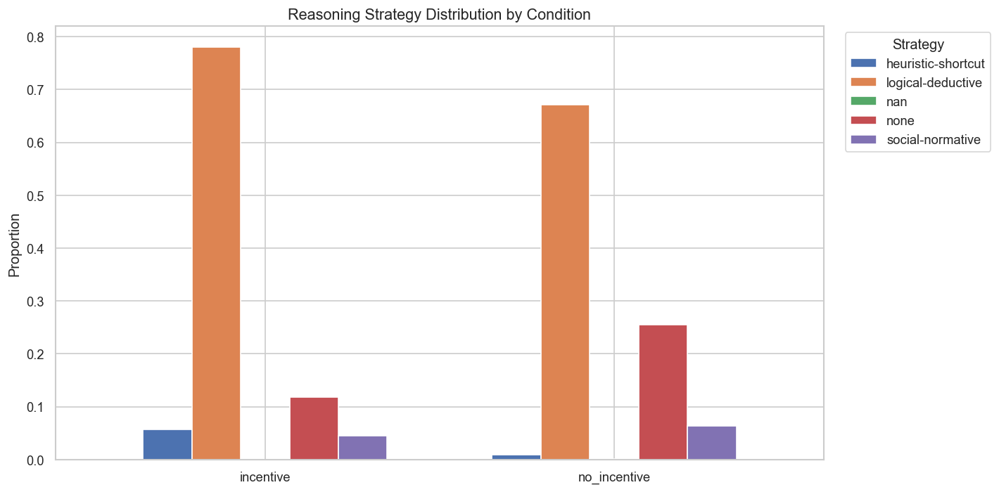

In [42]:
print("\n" + "=" * 80)
print("16. REASONING STRATEGY ANALYSIS")
print("=" * 80)

strat_ct = pd.crosstab(df["condition"], df["reasoning_style_primary_strategy"])
chi2_strat, p_strat, dof_strat, _ = chi2_contingency(strat_ct)
print(f"\nChi-squared test for reasoning strategy × condition:")
print(f"  χ² = {chi2_strat:.3f}, p = {p_strat:.6f}")
print(strat_ct.to_string())

# Strategy proportions by condition and model
strat_norm = pd.crosstab(
    [df["model"], df["condition"]],
    df["reasoning_style_primary_strategy"],
    normalize="index"
)
print("\n--- Strategy proportions ---")
print(strat_norm.round(3).to_string())

fig, ax = plt.subplots(figsize=(12, 6))
strat_plot = pd.crosstab(df["condition"], df["reasoning_style_primary_strategy"], normalize="index")
strat_plot.plot(kind="bar", ax=ax, edgecolor="white", width=0.7)
ax.set_title("Reasoning Strategy Distribution by Condition", fontsize=13)
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Strategy", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("fig_19_reasoning_strategy.png", bbox_inches="tight")
plt.show()

In [43]:
print("\n" + "=" * 80)
print("17. ORDINAL LOGISTIC REGRESSION (key outcomes)")
print("=" * 80)

# For ordinal outcomes, use ordered logit via statsmodels
from statsmodels.miscmodels.ordinal_model import OrderedModel

ordinal_outcomes = [
    "incentive_awareness_score",
    "treatment_awareness_score",
    "epistemic_certainty",
    "social_desirability_normative_orientation",
    "social_desirability_fear_of_judgment",
    "social_desirability_safe_answer_shift",
    "role_adherence_role_immersion",
]

df_ord = df.copy()
df_ord["condition_bin"] = (df_ord["condition"] == "incentive").astype(int)
# Create model dummies
for m_idx, m_name in enumerate(models[1:], 1):
    df_ord[f"model_{m_idx}"] = (df_ord["model"] == m_name).astype(int)
model_dummy_cols = [f"model_{i}" for i in range(1, len(models))]

ordinal_reg_results = []
for outcome in ordinal_outcomes:
    df_tmp = df_ord[["condition_bin", outcome] + model_dummy_cols].dropna()
    if len(df_tmp) < 50 or df_tmp[outcome].nunique() < 2:
        print(f"  {outcome}: skipped")
        continue
    try:
        exog = df_tmp[["condition_bin"] + model_dummy_cols].astype(float)
        endog = df_tmp[outcome].astype(float)
        mod = OrderedModel(endog, exog, distr="logit")
        res = mod.fit(method="bfgs", disp=False)
        print(f"\n--- {outcome} ---")
        print(res.summary())

        coef_cond = res.params.get("condition_bin", np.nan)
        p_cond = res.pvalues.get("condition_bin", np.nan)
        ordinal_reg_results.append({
            "outcome": outcome,
            "coef_condition": coef_cond,
            "odds_ratio": np.exp(coef_cond) if not np.isnan(coef_cond) else np.nan,
            "p_value": p_cond,
            "n": len(df_tmp),
            "converged": res.mle_retvals.get("converged", None) if hasattr(res, "mle_retvals") else None
        })
    except Exception as e:
        print(f"  {outcome}: ordered logit failed — {e}")

df_ordinal_res = pd.DataFrame(ordinal_reg_results)
if len(df_ordinal_res) > 0:
    df_ordinal_res.to_csv("ordinal_logistic_results.csv", index=False)
    print("\n--- Ordinal Logistic Regression: Condition coefficient ---")
    print(df_ordinal_res.to_string(index=False))



17. ORDINAL LOGISTIC REGRESSION (key outcomes)



--- incentive_awareness_score ---
                                 OrderedModel Results                                
Dep. Variable:     incentive_awareness_score   Log-Likelihood:                -2155.7
Model:                          OrderedModel   AIC:                             4325.
Method:                   Maximum Likelihood   BIC:                             4370.
Date:                       Sat, 18 Apr 2026                                         
Time:                               15:59:05                                         
No. Observations:                       4555                                         
Df Residuals:                           4548                                         
Df Model:                                  4                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
condition_bin    20.6424   


18. COMPREHENSIVE SUMMARY TABLE

                                     variable    type  mean_incentive  std_incentive  median_incentive  mean_no_incentive  std_no_incentive  median_no_incentive  diff_means  cohens_d       p_value  p_adjusted_fdr  effect_size  significant_fdr05
                    incentive_awareness_score ordinal        2.129555       0.734649               2.0           0.000000          0.000000                  0.0    2.129555  3.936381  0.000000e+00    0.000000e+00    -0.956275               True
    social_desirability_normative_orientation ordinal        1.227530       0.432634               1.0           1.788010          0.409988                  2.0   -0.560479 -1.326832 3.371511e-305   2.865785e-304     0.556122               True
                    social_desirability_total derived        3.697166       1.158811               4.0           4.099760          1.105572                  4.0   -0.402594 -0.354786  1.854910e-36    3.941683e-36     0.207786      

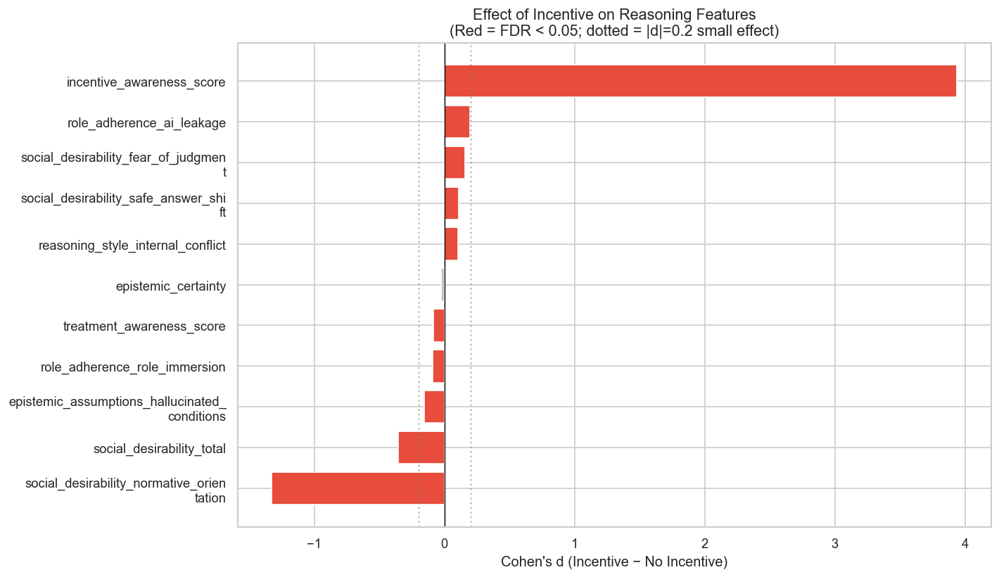

In [44]:
print("\n" + "=" * 80)
print("18. COMPREHENSIVE SUMMARY TABLE")
print("=" * 80)

summary_rows = []
for var in ordinal_vars + binary_vars + ["social_desirability_total"]:
    inc_vals = df.loc[df["condition"] == "incentive", var].dropna()
    no_vals = df.loc[df["condition"] == "no_incentive", var].dropna()
    row = {
        "variable": var,
        "type": "ordinal" if var in ordinal_vars else ("binary" if var in binary_vars else "derived"),
        "mean_incentive": inc_vals.mean(),
        "std_incentive": inc_vals.std(),
        "median_incentive": inc_vals.median(),
        "mean_no_incentive": no_vals.mean(),
        "std_no_incentive": no_vals.std(),
        "median_no_incentive": no_vals.median(),
        "diff_means": inc_vals.mean() - no_vals.mean(),
        "cohens_d": (inc_vals.mean() - no_vals.mean()) / np.sqrt(
            ((len(inc_vals) - 1) * inc_vals.std() ** 2 + (len(no_vals) - 1) * no_vals.std() ** 2) /
            (len(inc_vals) + len(no_vals) - 2)
        ) if (inc_vals.std() > 0 or no_vals.std() > 0) else 0,
    }
    # Find test result
    test_row = df_tests[df_tests["variable"] == var]
    if len(test_row) > 0:
        row["p_value"] = test_row.iloc[0]["p_value"]
        row["p_adjusted_fdr"] = test_row.iloc[0]["p_adjusted_fdr"]
        row["effect_size"] = test_row.iloc[0]["effect_size_r"]
        row["significant_fdr05"] = test_row.iloc[0]["significant_fdr05"]
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
df_summary = df_summary.sort_values("p_value")
df_summary.to_csv("comprehensive_summary.csv", index=False)

print("\n" + df_summary.to_string(index=False))

# ── 18b. Publication-ready summary plot ──
fig, ax = plt.subplots(figsize=(12, 7))
df_plot = df_summary.sort_values("cohens_d")
colors_summary = ["#e74c3c" if s else "#bdc3c7"
                   for s in df_plot.get("significant_fdr05", [False] * len(df_plot))]
bars = ax.barh(range(len(df_plot)), df_plot["cohens_d"], color=colors_summary, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(-0.2, color="gray", linestyle=":", alpha=0.5)
ax.axvline(0.2, color="gray", linestyle=":", alpha=0.5)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels([textwrap.fill(v, 35) for v in df_plot["variable"]])
ax.set_xlabel("Cohen's d (Incentive − No Incentive)")
ax.set_title("Effect of Incentive on Reasoning Features\n(Red = FDR < 0.05; dotted = |d|=0.2 small effect)",
             fontsize=13)
plt.tight_layout()
plt.savefig("fig_20_summary_effect_sizes.png", bbox_inches="tight")
plt.show()


In [45]:
print("\n" + "=" * 80)
print("19. FILES EXPORTED")
print("=" * 80)

export_files = [
    "statistical_tests_summary.csv",
    "within_model_tests.csv",
    "within_experiment_tests.csv",
    "logistic_regression_coefficients.csv",
    "random_forest_feature_importance.csv",
    "gradient_boosting_feature_importance.csv",
    "mixed_effects_results.csv",
    "interaction_condition_model.csv",
    "topic_chi2_comparison.csv",
    "ordinal_logistic_results.csv",
    "comprehensive_summary.csv",
    "run_cohort_classifier_auc.csv",
    "run_pair_classifier_auc.csv",
]

for f in export_files:
    try:
        _ = pd.read_csv(f)
        print(f"  ✓ {f}")
    except:
        print(f"  ✗ {f} (not created)")

print("\nFigures saved: fig_01–05; binary facets fig_03_binary_<variable>; categorical facets fig_04_categorical_<column>; later sections fig_06+ …")
print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)


19. FILES EXPORTED
  ✓ statistical_tests_summary.csv
  ✓ within_model_tests.csv
  ✓ within_experiment_tests.csv
  ✗ logistic_regression_coefficients.csv (not created)
  ✓ random_forest_feature_importance.csv
  ✓ gradient_boosting_feature_importance.csv
  ✓ mixed_effects_results.csv
  ✗ interaction_condition_model.csv (not created)
  ✓ topic_chi2_comparison.csv
  ✓ ordinal_logistic_results.csv
  ✓ comprehensive_summary.csv
  ✓ run_cohort_classifier_auc.csv
  ✓ run_pair_classifier_auc.csv

Figures saved: fig_01–05; binary facets fig_03_binary_<variable>; categorical facets fig_04_categorical_<column>; later sections fig_06+ …

ANALYSIS COMPLETE


## QA Check: Missing Reasoning and Final Answer

This block computes:
1. total number of rows across all `responses_final*.parquet` files;
2. distribution of cases with no reasoning and no final answer by model, experiment, and incentive.

In [46]:
from pathlib import Path
import pandas as pd

# If you run from project root, keep BASE as "thinking_expos/attitude/runs".
# If you run from thinking_expos/, use BASE = Path("attitude/runs").
BASE = Path("attitude/runs")

files = sorted(BASE.glob("**/responses_final*.parquet"))
_extra_csv = BASE / "no_incentive_50_reasoning_trace_t1" / "responses_final_no_incentive_50_reasoning_trace_t1_markup.csv"
if _extra_csv.is_file():
    files = sorted(list(files) + [_extra_csv])


def has_text(s: pd.Series) -> pd.Series:
    s = s.fillna("").astype(str).str.strip().str.lower()
    return ~s.isin(["", "nan", "none", "null"])


dfs = []
for f in files:
    f = Path(f)
    if f.suffix.lower() == ".csv":
        df_part = pd.read_csv(f)
    else:
        df_part = pd.read_parquet(f)
    df_part["source_file"] = str(f.relative_to(BASE))

    for c in [
        "REASONING",
        "stage1_reasoning_text",
        "stage2_reasoning_text",
        "reasoning_trace_combined",
        "final_answer_text",
        "model",
        "experiment_name",
        "incentive_key",
        "Incentive",
        "Treatment",
    ]:
        if c not in df_part.columns:
            df_part[c] = None

    dfs.append(df_part)

all_df = pd.concat(dfs, ignore_index=True)

# 1) Total rows
print("TOTAL_ROWS:", len(all_df))

# 2) Cases with no reasoning and no final answer
reasoning_present = (
    has_text(all_df["REASONING"])
    | has_text(all_df["stage1_reasoning_text"])
    | has_text(all_df["stage2_reasoning_text"])
    | has_text(all_df["reasoning_trace_combined"])
)
answer_present = has_text(all_df["final_answer_text"])

bad = all_df[~reasoning_present & ~answer_present].copy()
print("NO_REASONING_NO_ANSWER_ROWS:", len(bad))

bad["incentive_group"] = (
    bad["incentive_key"].astype("string")
    .fillna(bad["Incentive"].astype("string"))
    .fillna(bad["Treatment"].astype("string"))
    .fillna("NA")
)

dist = (
    bad.groupby(["model", "experiment_name", "incentive_group"], dropna=False)
    .size()
    .reset_index(name="n_cases")
    .sort_values("n_cases", ascending=False)
)

print("\nDISTRIBUTION (model, experiment, incentive):")
print(dist.to_string(index=False))

TOTAL_ROWS: 17080
NO_REASONING_NO_ANSWER_ROWS: 2024

DISTRIBUTION (model, experiment, incentive):
                      model                                                 experiment_name          incentive_group  n_cases
            qwen/qwen3.5-9b   Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture       C_balanced_realism      504
            qwen/qwen3.5-9b Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate       C_balanced_realism      320
            qwen/qwen3.5-9b Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate                       NA      312
            qwen/qwen3.5-9b Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate             Not provided      240
moonshotai/kimi-k2-thinking   Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture                       NA      122
       minimax/minimax-m2.5   Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture                       NA      120
       minimax/minim

In [47]:
# === Coverage check: reasoning present, but markup missing ===
import re
import pandas as pd
import numpy as np

# 1) pick dataframe
if 'df' in globals():
    _df = df.copy()
elif 'all_df' in globals():
    _df = all_df.copy()
else:
    raise ValueError('Не найден dataframe: ожидается df или all_df в текущем ноутбуке')


def _has_text(s: pd.Series) -> pd.Series:
    s = s.fillna('').astype(str).str.strip().str.lower()
    return ~s.isin(['', 'nan', 'none', 'null'])

# 2) reasoning presence (robust to different schemas)
reasoning_candidates = [
    'REASONING',
    'reasoning_text',
    'stage1_reasoning_text',
    'stage2_reasoning_text',
    'reasoning_trace_combined',
    'raw_response_text',
]
reasoning_cols = [c for c in reasoning_candidates if c in _df.columns]
if not reasoning_cols:
    raise ValueError('Не найдено колонок с reasoning-текстом')

reasoning_present = pd.Series(False, index=_df.index)
for c in reasoning_cols:
    reasoning_present = reasoning_present | _has_text(_df[c])

# 3) markup columns
# priority A: if notebook already has explicit feature lists
markup_cols = []
if 'ordinal_vars' in globals() and isinstance(ordinal_vars, list):
    markup_cols.extend([c for c in ordinal_vars if c in _df.columns])
if 'binary_vars' in globals() and isinstance(binary_vars, list):
    markup_cols.extend([c for c in binary_vars if c in _df.columns])

# priority B: auto-detect likely markup columns by prefixes
if len(markup_cols) == 0:
    prefixes = (
        'treatment_awareness_',
        'incentive_awareness_',
        'epistemic_',
        'social_desirability_',
        'reasoning_style_',
        'role_adherence_',
        'affective_state_',
    )
    markup_cols = [c for c in _df.columns if c.startswith(prefixes)]

# optional extras often used as markup outputs
for c in ['extracted_topics']:
    if c in _df.columns and c not in markup_cols:
        markup_cols.append(c)

if len(markup_cols) == 0:
    raise ValueError('Не удалось определить колонки разметки. Проверьте названия полей в df.')

# 4) row-level "has any markup"
ERROR_TEXT_PATTERNS = [
    r'error', r'failed', r'failure', r'exception', r'traceback', r'timeout', r'timed out',
    r'parse error', r'json decode', r'invalid', r'rate limit', r'429', r'503',
    r'api error', r'no response', r'empty response', r'not available', r'n/a', r'none'
]
ERROR_TEXT_REGEX = re.compile('|'.join(ERROR_TEXT_PATTERNS), flags=re.I)

def _is_error_like_text(series: pd.Series) -> pd.Series:
    s = series.fillna('').astype(str).str.strip()
    # error-like if matches known failure tokens
    return s.str.contains(ERROR_TEXT_REGEX, regex=True, na=False)

def _has_markup_value(series: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(series):
        return series.notna()
    # text markup counts only if non-empty AND not error-like
    has_txt = _has_text(series)
    err_like = _is_error_like_text(series)
    return has_txt & (~err_like)

has_any_markup = pd.Series(False, index=_df.index)
has_error_like_markup_text = pd.Series(False, index=_df.index)
for c in markup_cols:
    if not pd.api.types.is_numeric_dtype(_df[c]):
        has_error_like_markup_text = has_error_like_markup_text | _is_error_like_text(_df[c])
    has_any_markup = has_any_markup | _has_markup_value(_df[c])

# target: rows with reasoning but without valid markup
mask_target = reasoning_present & (~has_any_markup)
mask_error_in_markup = reasoning_present & has_error_like_markup_text

# 5) summary stats
n_total = len(_df)
n_reasoning = int(reasoning_present.sum())
n_unmarked = int(mask_target.sum())
pct_unmarked_total = 100 * n_unmarked / n_total if n_total else np.nan
pct_unmarked_among_reasoning = 100 * n_unmarked / n_reasoning if n_reasoning else np.nan

print('=' * 90)
print('UNMARKED COVERAGE SUMMARY')
print('=' * 90)
print(f'Total rows: {n_total:,}')
print(f'Rows with reasoning: {n_reasoning:,}')
n_error_like = int(mask_error_in_markup.sum())

print(f'Rows with reasoning but NO valid markup: {n_unmarked:,}')
print(f'Percent of all rows unmarked (reasoning+no valid markup): {pct_unmarked_total:.2f}%')
print(f'Percent among reasoning rows unmarked: {pct_unmarked_among_reasoning:.2f}%')
print(f'Rows with reasoning and error-like text in markup columns: {n_error_like:,}')
print(f'Markup columns used ({len(markup_cols)}):')
print(markup_cols)

# 6) highlight models / experiments / incentives
show_df = _df.loc[mask_target].copy()

def _pick_col(options):
    for c in options:
        if c in show_df.columns:
            return c
    return None

model_col = _pick_col(['model', 'model_name'])
exp_col = _pick_col(['experiment_name', 'experiment_id'])
inc_col = _pick_col(['incentive_key', 'incentive_name', 'Incentive'])

print('\n' + '=' * 90)
print('BREAKDOWN: UNMARKED ROWS (reasoning present, markup missing)')
print('=' * 90)

if model_col:
    model_breakdown = (
        show_df.groupby(model_col).size().rename('n_unmarked').sort_values(ascending=False).to_frame()
    )
    model_breakdown['pct_within_unmarked'] = 100 * model_breakdown['n_unmarked'] / max(n_unmarked, 1)
    display(model_breakdown)

if exp_col:
    exp_breakdown = (
        show_df.groupby(exp_col).size().rename('n_unmarked').sort_values(ascending=False).to_frame()
    )
    exp_breakdown['pct_within_unmarked'] = 100 * exp_breakdown['n_unmarked'] / max(n_unmarked, 1)
    display(exp_breakdown.head(30))

if inc_col:
    inc_breakdown = (
        show_df.groupby(inc_col).size().rename('n_unmarked').sort_values(ascending=False).to_frame()
    )
    inc_breakdown['pct_within_unmarked'] = 100 * inc_breakdown['n_unmarked'] / max(n_unmarked, 1)
    display(inc_breakdown)

# 7) optional joint table for quick triage
group_cols = [c for c in [model_col, exp_col, inc_col] if c is not None]
if group_cols:
    joint = (
        show_df.groupby(group_cols).size().rename('n_unmarked').reset_index()
        .sort_values('n_unmarked', ascending=False)
    )
    joint['pct_within_unmarked'] = 100 * joint['n_unmarked'] / max(n_unmarked, 1)
    print('\nTop combinations with missing markup:')
    display(joint.head(50))

# 8) quick sample rows for manual QA
cols_preview = [c for c in [model_col, exp_col, inc_col] if c is not None]
cols_preview += [c for c in reasoning_cols[:2] if c in show_df.columns]
cols_preview = list(dict.fromkeys(cols_preview))

print('\nSample unmarked rows:')
if len(show_df) > 0:
    display(show_df[cols_preview].head(20))
else:
    print('No unmarked rows found (all reasoning rows have some markup).')

UNMARKED COVERAGE SUMMARY
Total rows: 5,600
Rows with reasoning: 5,122
Rows with reasoning but NO valid markup: 567
Percent of all rows unmarked (reasoning+no valid markup): 10.12%
Percent among reasoning rows unmarked: 11.07%
Rows with reasoning and error-like text in markup columns: 1,039
Markup columns used (11):
['treatment_awareness_score', 'incentive_awareness_score', 'epistemic_certainty', 'social_desirability_normative_orientation', 'social_desirability_fear_of_judgment', 'social_desirability_safe_answer_shift', 'role_adherence_role_immersion', 'reasoning_style_internal_conflict', 'role_adherence_ai_leakage', 'epistemic_assumptions_hallucinated_conditions', 'extracted_topics']

BREAKDOWN: UNMARKED ROWS (reasoning present, markup missing)


,n_unmarked,pct_within_unmarked
model,,
minimax/minimax-m2.5,350,61.728395
qwen/qwen3.5-9b,204,35.978836
z-ai/glm-4.6,13,2.292769


,n_unmarked,pct_within_unmarked
experiment_name,,
Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,379,66.843034
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,188,33.156966


,n_unmarked,pct_within_unmarked
incentive_key,,



Top combinations with missing markup:


,model,experiment_name,incentive_key,n_unmarked,pct_within_unmarked



Sample unmarked rows:


,model,experiment_name,incentive_key,REASONING,stage1_reasoning_text
2085,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2086,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2089,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2090,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2091,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2092,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2093,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2094,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2095,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...
2096,z-ai/glm-4.6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,NaN,1. **Analyze the Vignette:**\n * **Actio...,\n1. **Analyze the Vignette:**\n * **Act...


In [48]:
# === API error rate among rows WITH reasoning, by model × experiment × incentive × treatment group ===
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path('attitude/runs')
if not BASE.exists():
    BASE = Path('thinking_expos/attitude/runs')

patterns = ['**/*markup*.parquet', '**/responses_final*markup*.parquet']
files = []
for pat in patterns:
    files.extend(BASE.glob(pat))
files = sorted(set(files))

if not files:
    print('Markup parquet files not found.')
else:
    parts = []
    for fp in files:
        dfi = pd.read_parquet(fp)
        dfi['source_file'] = str(fp.relative_to(BASE))
        parts.append(dfi)

    all_df = pd.concat(parts, ignore_index=True)

    def has_text(s: pd.Series) -> pd.Series:
        s = s.fillna('').astype(str).str.strip().str.lower()
        return ~s.isin(['', 'nan', 'none', 'null'])

    # reasoning presence
    reasoning_candidates = [
        'REASONING',
        'reasoning_text',
        'stage1_reasoning_text',
        'stage2_reasoning_text',
        'reasoning_trace_combined',
        'raw_response_text',
    ]
    reasoning_cols = [c for c in reasoning_candidates if c in all_df.columns]
    if not reasoning_cols:
        raise ValueError('No reasoning column found in markup files')

    reasoning_present = pd.Series(False, index=all_df.index)
    for c in reasoning_cols:
        reasoning_present = reasoning_present | has_text(all_df[c])

    # api_error presence
    api_err = has_text(all_df['api_error']) if 'api_error' in all_df.columns else pd.Series(False, index=all_df.index)

    work = all_df.loc[reasoning_present].copy()
    work['api_error_present'] = api_err.loc[work.index].astype(int)

    # group columns (auto-detect)
    def pick_col(cands):
        for c in cands:
            if c in work.columns:
                return c
        return None

    model_col = pick_col(['model', 'model_name'])
    exp_col = pick_col(['experiment_name', 'experiment_id'])
    inc_col = pick_col(['incentive_key', 'incentive_name', 'Incentive'])
    treat_col = pick_col(['group_name', 'treatment_group', 'Treatment'])

    if None in [model_col, exp_col, inc_col, treat_col]:
        raise ValueError({'model': model_col, 'experiment': exp_col, 'incentive': inc_col, 'treatment_group': treat_col})

    # IMPORTANT: keep NA groups (many api_error rows have missing incentive_key)
    for c in [model_col, exp_col, inc_col, treat_col]:
        work[c] = work[c].fillna('__MISSING__')

    out = (
        work.groupby([model_col, exp_col, inc_col, treat_col], dropna=False)
            .agg(
                n_rows_with_reasoning=('api_error_present', 'size'),
                n_rows_with_api_error=('api_error_present', 'sum')
            )
            .reset_index()
    )
    out['api_error_rate_pct'] = 100 * out['n_rows_with_api_error'] / out['n_rows_with_reasoning']
    out = out.sort_values(['api_error_rate_pct', 'n_rows_with_reasoning'], ascending=[False, False]).reset_index(drop=True)

    n_reason = len(work)
    n_api_err = int(work['api_error_present'].sum())

    print('=' * 100)
    print('API_ERROR RATE AMONG ROWS WITH REASONING')
    print('=' * 100)
    print(f'Reasoning rows total: {n_reason:,}')
    print(f'Reasoning rows with api_error: {n_api_err:,}')
    print(f'Overall api_error rate among reasoning rows: {100 * n_api_err / max(n_reason,1):.2f}%')
    print(f'Grouping columns: model={model_col}, experiment={exp_col}, incentive={inc_col}, treatment_group={treat_col}')

    # Requested: show just one table
    display(out)

API_ERROR RATE AMONG ROWS WITH REASONING
Reasoning rows total: 4,989
Reasoning rows with api_error: 567
Overall api_error rate among reasoning rows: 11.37%
Grouping columns: model=model, experiment=experiment_name, incentive=incentive_key, treatment_group=group_name


,model,experiment_name,incentive_key,group_name,n_rows_with_reasoning,n_rows_with_api_error,api_error_rate_pct
0,qwen/qwen3.5-9b,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,__MISSING__,treatment_protracted_duration,83,43,51.807229
1,minimax/minimax-m2.5,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,__MISSING__,control_base_case,100,50,50.000000
2,minimax/minimax-m2.5,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,__MISSING__,treatment_duration_plus_modest_intelligence,100,50,50.000000
3,minimax/minimax-m2.5,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,__MISSING__,treatment_modest_intelligence,100,50,50.000000
4,minimax/minimax-m2.5,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,__MISSING__,treatment_protracted_duration,100,50,50.000000
...,...,...,...,...,...,...,...
79,qwen/qwen3.5-9b,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,C_balanced_realism,public_recognition_treatment,23,0,0.000000
80,qwen/qwen3.5-9b,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,X_measurement_neutrality,private_donation_control,23,0,0.000000
81,qwen/qwen3.5-9b,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,C_balanced_realism,treatment_modest_intelligence,20,0,0.000000
82,qwen/qwen3.5-9b,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,C_balanced_realism,treatment_protracted_duration,17,0,0.000000


## Reasoning text topic analysis (STM-style)

В этом блоке проводится тематическое моделирование reasoning-текстов с разным числом тем (`K`).

- Основной рабочий вариант: **STM-style** анализ в Python (LDA + topic prevalence by covariates).
- Если доступны R + `stm`, можно расширить до классического STM; текущая версия полностью запускается в Python.

Цель: получить устойчивые тематические кластеры, сравнить их по `K`, и дать интерпретации каждой темы на основе top words и representative snippets.

In [49]:
# --- 1) Build reasoning corpus ---
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

if 'all_df' in globals():
    stm_df = all_df.copy()
elif 'df' in globals():
    stm_df = df.copy()
else:
    raise ValueError('No dataframe found: expected all_df or df')


def has_text(s: pd.Series) -> pd.Series:
    s = s.fillna('').astype(str).str.strip().str.lower()
    return ~s.isin(['', 'nan', 'none', 'null'])

reasoning_candidates = ['REASONING','reasoning_text','stage1_reasoning_text','stage2_reasoning_text','reasoning_trace_combined','raw_response_text']
reasoning_cols = [c for c in reasoning_candidates if c in stm_df.columns]
if not reasoning_cols:
    raise ValueError('No reasoning columns found')

# combine reasoning fields (prefer richer text while preserving availability)
stm_df['reasoning_combined'] = ''
for c in reasoning_cols:
    s = stm_df[c].fillna('').astype(str)
    stm_df['reasoning_combined'] = np.where(
        stm_df['reasoning_combined'].str.len() > 0,
        stm_df['reasoning_combined'] + ' ' + s,
        s
    )

stm_df['reasoning_combined'] = (
    stm_df['reasoning_combined']
    .fillna('')
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

reason_mask = has_text(stm_df['reasoning_combined'])
corpus_df = stm_df.loc[reason_mask].copy().reset_index(drop=True)

# optional cleanup: remove obvious API/system errors from reasoning text
err_pat = re.compile(r'error|failed|exception|traceback|timeout|rate limit|api', flags=re.I)
corpus_df = corpus_df.loc[~corpus_df['reasoning_combined'].str.contains(err_pat, na=False)].reset_index(drop=True)

print('Corpus rows:', len(corpus_df))
print('Columns available:', [c for c in ['model','model_name','experiment_name','experiment_id','incentive_key','incentive_name','group_name','treatment_group','condition'] if c in corpus_df.columns])
corpus_df[['reasoning_combined']].head(3)

Corpus rows: 1890
Columns available: ['model', 'experiment_name', 'incentive_key', 'group_name']


,reasoning_combined
0,The user wants me to act as a plausible survey...
1,The user wants me to act as a plausible survey...
2,The user wants me to act as a plausible survey...


In [50]:
# --- 2) Run STM-style experiments for multiple K ---
# We approximate STM with LDA topic model + covariate prevalence analysis (next cell).

vectorizer = CountVectorizer(
    lowercase=True,
    stop_words='english',
    min_df=10,
    max_df=0.8,
    ngram_range=(1, 2)
)
X = vectorizer.fit_transform(corpus_df['reasoning_combined'])
vocab = np.array(vectorizer.get_feature_names_out())

K_LIST = [6, 8, 10, 12]
models = {}
exp_rows = []

for k in K_LIST:
    lda = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method='batch',
        max_iter=50,
        doc_topic_prior=0.1,
        topic_word_prior=0.01,
    )
    doc_topic = lda.fit_transform(X)
    perplex = lda.perplexity(X)

    # simple exclusivity proxy: mean( max topic prob per word-distribution row )
    topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
    exclusivity_proxy = np.mean(topic_word.max(axis=0))

    models[k] = {'model': lda, 'doc_topic': doc_topic, 'topic_word': topic_word}
    exp_rows.append({
        'K': k,
        'perplexity': perplex,
        'log_likelihood': lda.score(X),
        'exclusivity_proxy': exclusivity_proxy,
    })

exp_table = pd.DataFrame(exp_rows).sort_values('K')
print('STM-style experiments summary:')
display(exp_table)

BEST_K = exp_table.sort_values(['perplexity', 'exclusivity_proxy'], ascending=[True, False]).iloc[0]['K']
BEST_K = int(BEST_K)
print(f'Selected K for interpretation: {BEST_K}')

STM-style experiments summary:


,K,perplexity,log_likelihood,exclusivity_proxy
0,6,1615.264695,-3.075885e+07,0.000299
1,8,1454.583061,-3.032257e+07,0.000373
2,10,1395.841863,-3.015093e+07,0.000467
3,12,1340.940510,-2.998386e+07,0.000520


Selected K for interpretation: 12


In [51]:
# --- 3) Interpret topics for each K (top words + representative snippets) ---

def infer_topic_label(words):
    w = ' '.join(words).lower()
    if any(x in w for x in ['should', 'right', 'wrong', 'fair', 'moral', 'ethical', 'responsible']):
        return 'Normative / moral evaluation'
    if any(x in w for x in ['legal', 'illegal', 'law', 'rule', 'allowed', 'prohibited']):
        return 'Legality / rule-following'
    if any(x in w for x in ['social', 'acceptable', 'judged', 'reputation', 'respectable', 'proper']):
        return 'Social desirability / image management'
    if any(x in w for x in ['risk', 'cost', 'benefit', 'incentive', 'gain', 'advantage']):
        return 'Pragmatic cost-benefit reasoning'
    if any(x in w for x in ['maybe', 'perhaps', 'likely', 'might', 'could', 'depends']):
        return 'Hedging / uncertainty'
    if any(x in w for x in ['harm', 'hurt', 'damage', 'suffering', 'care', 'compassion']):
        return 'Harm-care framing'
    return 'Contextual / mixed rationale'

all_topic_summaries = []

for k in K_LIST:
    lda = models[k]['model']
    doc_topic = models[k]['doc_topic']

    print('\n' + '='*100)
    print(f'TOPIC INTERPRETATION FOR K={k}')
    print('='*100)

    for t in range(k):
        top_idx = np.argsort(lda.components_[t])[::-1][:12]
        top_words = vocab[top_idx].tolist()

        # representative docs = highest topic proportion docs
        top_doc_idx = np.argsort(doc_topic[:, t])[::-1][:3]
        snippets = []
        for di in top_doc_idx:
            txt = corpus_df.iloc[di]['reasoning_combined']
            snippets.append((float(doc_topic[di, t]), txt[:220] + ('...' if len(txt) > 220 else '')))

        label = infer_topic_label(top_words)
        all_topic_summaries.append({
            'K': k,
            'topic_id': t,
            'topic_label': label,
            'top_words': ', '.join(top_words),
            'mean_topic_prevalence': float(doc_topic[:, t].mean())
        })

        print(f'\nTopic {t} | label: {label}')
        print('Top words:', ', '.join(top_words))
        print('Representative snippets:')
        for score, snip in snippets:
            print(f'  - p={score:.3f}: {snip}')

topic_summary_df = pd.DataFrame(all_topic_summaries)
print('\nTopic summary table (first rows):')
display(topic_summary_df.head(30))


TOPIC INTERPRETATION FOR K=6

Topic 0 | label: Contextual / mixed rationale
Top words: ll, wait, wait ll, okay, okay ll, choose, ll choose, ll okay, output, choose wait, output wait, ll output
Representative snippets:
  - p=1.000: Thinking Process: 1. **Analyze the Request:** * Role: Plausible survey respondent in a vignette-based study. * Task: Consider the situation, evaluate it, and choose exactly one response option. * Output: Only the number ...
  - p=1.000: Thinking Process: 1. **Analyze the Request:** * Role: Plausible survey respondent in a vignette-based study. * Task: Consider the situation, evaluate it, and choose exactly one response option. * Output: Only the number ...
  - p=1.000: Thinking Process: 1. **Analyze the Request:** * Role: Plausible survey respondent in a vignette-based study. * Task: Consider the situation, evaluate it, and choose exactly one response option. * Output: Only the number ...

Topic 1 | label: Pragmatic cost-benefit reasoning
Top words: recognit

,K,topic_id,topic_label,top_words,mean_topic_prevalence
0,6,0,Contextual / mixed rationale,"ll, wait, wait ll, okay, okay ll, choose, ll c...",0.022107
1,6,1,Pragmatic cost-benefit reasoning,"recognition, public, public recognition, low, ...",0.106214
2,6,2,Social desirability / image management,"recognition, think, public, public recognition...",0.540769
3,6,3,Pragmatic cost-benefit reasoning,"low, cost, strong, benefit, benefits, low cost...",0.205104
4,6,4,Contextual / mixed rationale,"wait, let, realistic, recognition, okay, publi...",0.075738
5,6,5,Normative / moral evaluation,"admirable, answer, morally, morally admirable,...",0.050068
6,8,0,Contextual / mixed rationale,"ll, wait, okay, wait ll, okay ll, choose, ll c...",0.007542
7,8,1,Pragmatic cost-benefit reasoning,"recognition, public, public recognition, low, ...",0.094200
8,8,2,Contextual / mixed rationale,"think, recognition, public, public recognition...",0.237051
9,8,3,Pragmatic cost-benefit reasoning,"low, cost, strong, benefit, feels, benefits, l...",0.188832


In [52]:
# --- 4) Topic prevalence by covariates (STM-like component) + short conclusions ---
# Using BEST_K model: regress topic prevalence on available covariates (model, experiment, incentive, treatment/condition)
import statsmodels.formula.api as smf

best = models[BEST_K]
doc_topic_best = best['doc_topic']

topic_prev_df = corpus_df.copy()
for t in range(BEST_K):
    topic_prev_df[f'topic_{t}'] = doc_topic_best[:, t]

# auto-detect covariate columns present (must be informative, not just existing)
cov_candidates = [
    ('model_col', ['model_name', 'model']),
    ('exp_col', ['experiment_id', 'experiment_name']),
    ('inc_col', ['incentive_name', 'incentive_key', 'Incentive']),
    ('treat_col', ['treatment_group', 'group_name', 'Treatment', 'condition'])
]

def pick_informative_col(df, candidates):
    for c in candidates:
        if c not in df.columns:
            continue
        s = df[c]
        non_na = s.dropna()
        # informative if has non-missing values and >1 unique category among non-missing
        if len(non_na) > 0 and non_na.nunique() > 1:
            return c
    return None

selected = {}
for key, cands in cov_candidates:
    selected[key] = pick_informative_col(topic_prev_df, cands)

print('Selected informative covariates for topic prevalence:', selected)
for k, v in selected.items():
    if v is not None:
        s = topic_prev_df[v]
        print(f'  {k}: {v} | non-missing={s.notna().mean():.3f} | unique_non_missing={s.dropna().nunique()}')

cov_formula_terms = []
for v in selected.values():
    if v is not None:
        cov_formula_terms.append(f'C({v})')

if len(cov_formula_terms) == 0:
    print('No covariates found for STM-like prevalence regressions.')
else:
    formula_rhs = ' + '.join(cov_formula_terms)
    prev_rows = []
    fail_rows = []

    for t in range(BEST_K):
        y = f'topic_{t}'
        fml = f'{y} ~ {formula_rhs}'
        try:
            fit_df = topic_prev_df[[y] + [v for v in selected.values() if v is not None]].copy()
            res = smf.ols(fml, data=fit_df).fit()
            prev_rows.append({
                'topic_id': t,
                'r2': res.rsquared,
                'adj_r2': res.rsquared_adj,
                'f_pvalue': res.f_pvalue,
                'nobs': int(res.nobs),
            })
        except Exception as e:
            fail_rows.append({'topic_id': t, 'error_type': type(e).__name__, 'error_message': str(e)[:220]})
            continue

    prev_df = pd.DataFrame(prev_rows)
    if prev_df.empty:
        print('\nTopic prevalence models were not estimated for any topic (all fits failed).')
        print('Likely causes: no informative covariates, all-missing covariate columns, or singular design matrix.')
        if len(fail_rows) > 0:
            print('\nFailure diagnostics by topic:')
            display(pd.DataFrame(fail_rows))
    else:
        prev_df = prev_df.sort_values('r2', ascending=False)
        print('\nTopic prevalence model quality (higher R2 => more covariate-structured topic):')
        display(prev_df)
        if len(fail_rows) > 0:
            print('\nSome topics failed to fit; diagnostics:')
            display(pd.DataFrame(fail_rows))

print('\nPRELIMINARY INTERPRETATION ACROSS STM-EXPERIMENTS')
print('- Compare K by perplexity/exclusivity table: choose K with best trade-off and interpretable topics.')
print('- Moralization-like clusters typically show words: should/right/wrong/fair/responsible.')
print('- Sanitization/SDB-like clusters typically show words: socially acceptable/proper/judged/respectable.')
print('- Treatment-sensitive clusters are those whose prevalence shifts by treatment/group covariate and mention vignette-specific cues.')
print('- If answer_then_rationale topics appear less treatment-specific and more justificatory, this is early evidence of post-hoc rationalization.')

Selected informative covariates for topic prevalence: {'model_col': 'model', 'exp_col': 'experiment_name', 'inc_col': 'incentive_key', 'treat_col': 'group_name'}
  model_col: model | non-missing=1.000 | unique_non_missing=4
  exp_col: experiment_name | non-missing=1.000 | unique_non_missing=2
  inc_col: incentive_key | non-missing=0.526 | unique_non_missing=2
  treat_col: group_name | non-missing=1.000 | unique_non_missing=6

Topic prevalence models were not estimated for any topic (all fits failed).
Likely causes: no informative covariates, all-missing covariate columns, or singular design matrix.

Failure diagnostics by topic:


,topic_id,error_type,error_message
0,0,PatsyError,Error evaluating factor: TypeError: 'float' ob...
1,1,PatsyError,Error evaluating factor: TypeError: 'float' ob...
2,2,PatsyError,Error evaluating factor: TypeError: 'float' ob...
3,3,PatsyError,Error evaluating factor: TypeError: 'float' ob...
4,4,PatsyError,Error evaluating factor: TypeError: 'float' ob...
5,5,PatsyError,Error evaluating factor: TypeError: 'float' ob...
6,6,PatsyError,Error evaluating factor: TypeError: 'float' ob...
7,7,PatsyError,Error evaluating factor: TypeError: 'float' ob...
8,8,PatsyError,Error evaluating factor: TypeError: 'float' ob...
9,9,PatsyError,Error evaluating factor: TypeError: 'float' ob...



PRELIMINARY INTERPRETATION ACROSS STM-EXPERIMENTS
- Compare K by perplexity/exclusivity table: choose K with best trade-off and interpretable topics.
- Moralization-like clusters typically show words: should/right/wrong/fair/responsible.
- Sanitization/SDB-like clusters typically show words: socially acceptable/proper/judged/respectable.
- Treatment-sensitive clusters are those whose prevalence shifts by treatment/group covariate and mention vignette-specific cues.
- If answer_then_rationale topics appear less treatment-specific and more justificatory, this is early evidence of post-hoc rationalization.


### Notes on interpretation

- Этот блок делает **несколько STM-экспериментов по K** и выводит интерпретации для каждого набора тем.
- Интерпретации построены на сочетании:
  - top words темы,
  - representative snippets,
  - и topic prevalence regressions на ковариаты (`model/experiment/incentive/treatment`).
- Для более строгого confirmatory-этапа можно зафиксировать `K` и вручную утвердить кодбук тем.

In [53]:
# === Random reasoning viewer with filters ===
#
# Possible filter values (auto-detected from current dataframe):
# - model:           unique values from one of ['model', 'model_name']
# - experiment:      unique values from one of ['experiment_name', 'experiment_id']
# - treatment_group: unique values from one of ['group_name', 'treatment_group', 'Treatment']
# - incentive:       unique values from one of ['incentive_key', 'incentive_name', 'Incentive']
#
# To see all available values in your current run, execute:
#   show_filter_options()
#
# Example:
#   show_random_reasoning(
#       model='qwen/qwen3.5-9b',
#       experiment='Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture',
#       treatment_group='control_base_case',
#       incentive='__MISSING__',
#       random_state=42
#   )

import random
import textwrap
import pandas as pd

# Pick source dataframe
if 'all_df' in globals():
    _rr_df = all_df.copy()
elif 'df' in globals():
    _rr_df = df.copy()
else:
    raise ValueError('No dataframe found. Expected `all_df` or `df` in notebook memory.')


def _pick_first_existing(cols, frame):
    for c in cols:
        if c in frame.columns:
            return c
    return None


def _has_text(s: pd.Series) -> pd.Series:
    s = s.fillna('').astype(str).str.strip().str.lower()
    return ~s.isin(['', 'nan', 'none', 'null'])


# Candidate columns
_model_col = _pick_first_existing(['model', 'model_name'], _rr_df)
_exp_col = _pick_first_existing(['experiment_name', 'experiment_id'], _rr_df)
_treat_col = _pick_first_existing(['group_name', 'treatment_group', 'Treatment'], _rr_df)
_inc_col = _pick_first_existing(['incentive_key', 'incentive_name', 'Incentive'], _rr_df)

_reason_cols = [
    c for c in ['REASONING', 'reasoning_text', 'stage1_reasoning_text', 'stage2_reasoning_text', 'reasoning_trace_combined', 'raw_response_text']
    if c in _rr_df.columns
]
if not _reason_cols:
    raise ValueError('No reasoning text columns found in dataframe.')


# Build merged reasoning field (with line breaks preserved as much as possible)
_rr_df['_reasoning_view'] = ''
for c in _reason_cols:
    s = _rr_df[c].fillna('').astype(str)
    _rr_df['_reasoning_view'] = _rr_df['_reasoning_view'].where(
        _rr_df['_reasoning_view'].str.strip().astype(bool),
        s
    )

# If still empty for some rows, concatenate all available text columns
empty_mask = ~_has_text(_rr_df['_reasoning_view'])
if empty_mask.any():
    _rr_df.loc[empty_mask, '_reasoning_view'] = _rr_df.loc[empty_mask, _reason_cols].fillna('').astype(str).agg('\n'.join, axis=1)

_rr_df = _rr_df[_has_text(_rr_df['_reasoning_view'])].copy()

# Normalize filter columns for robust filtering
for c in [_model_col, _exp_col, _treat_col, _inc_col]:
    if c is not None:
        _rr_df[c] = _rr_df[c].fillna('__MISSING__')


def show_filter_options():
    """Print all available filter values in the current dataframe."""
    print('=' * 100)
    print('AVAILABLE FILTER VALUES')
    print('=' * 100)

    for label, col in [
        ('model', _model_col),
        ('experiment', _exp_col),
        ('treatment_group', _treat_col),
        ('incentive', _inc_col),
    ]:
        if col is None:
            print(f'\n[{label}] -> column not found')
            continue
        vals = sorted(_rr_df[col].astype(str).unique().tolist())
        print(f'\n[{label}] (column: {col}, n={len(vals)})')
        for v in vals:
            print(' -', v)


def show_random_reasoning(model=None, experiment=None, treatment_group=None, incentive=None, random_state=None):
    """
    Show one random reasoning text for selected filters.

    Parameters:
      model: str | None
      experiment: str | None
      treatment_group: str | None
      incentive: str | None
      random_state: int | None
    """
    subset = _rr_df.copy()

    if model is not None and _model_col is not None:
        subset = subset[subset[_model_col].astype(str) == str(model)]
    if experiment is not None and _exp_col is not None:
        subset = subset[subset[_exp_col].astype(str) == str(experiment)]
    if treatment_group is not None and _treat_col is not None:
        subset = subset[subset[_treat_col].astype(str) == str(treatment_group)]
    if incentive is not None and _inc_col is not None:
        subset = subset[subset[_inc_col].astype(str) == str(incentive)]

    if len(subset) == 0:
        print('No rows found for selected filters.')
        return

    if random_state is not None:
        row = subset.sample(n=1, random_state=int(random_state)).iloc[0]
    else:
        row = subset.sample(n=1).iloc[0]

    print('=' * 100)
    print('RANDOM REASONING SAMPLE')
    print('=' * 100)
    if _model_col is not None:
        print(f'model           : {row[_model_col]}')
    if _exp_col is not None:
        print(f'experiment      : {row[_exp_col]}')
    if _treat_col is not None:
        print(f'treatment_group : {row[_treat_col]}')
    if _inc_col is not None:
        print(f'incentive       : {row[_inc_col]}')
    if 'source_file' in row.index:
        print(f'source_file     : {row["source_file"]}')

    print('-' * 100)
    print('Reasoning text:')
    print('-' * 100)

    text = str(row['_reasoning_view']).replace('\r\n', '\n').replace('\r', '\n').strip()
    # Keep paragraph breaks and wrap long lines for readability
    paragraphs = [p.strip() for p in text.split('\n')]
    for p in paragraphs:
        if p == '':
            print()
        else:
            print(textwrap.fill(p, width=110))

    print('=' * 100)


print('Ready. Use show_filter_options() and show_random_reasoning(...).')

Ready. Use show_filter_options() and show_random_reasoning(...).


In [54]:
show_filter_options()

AVAILABLE FILTER VALUES

[model] (column: model, n=4)
 - minimax/minimax-m2.5
 - moonshotai/kimi-k2-thinking
 - qwen/qwen3.5-9b
 - z-ai/glm-4.6

[experiment] (column: experiment_name, n=2)
 - Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture
 - Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate

[treatment_group] (column: group_name, n=7)
 - control_base_case
 - private_donation_control
 - public_recognition_treatment
 - public_recognition_with_social_benefit
 - treatment_duration_plus_modest_intelligence
 - treatment_modest_intelligence
 - treatment_protracted_duration

[incentive] (column: incentive_key, n=3)
 - C_balanced_realism
 - X_measurement_neutrality
 - __MISSING__


In [55]:
show_random_reasoning(model='z-ai/glm-4.6',
                      experiment='Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture',
                      treatment_group='treatment_modest_intelligence',
                      incentive='C_balanced_realism')

RANDOM REASONING SAMPLE
model           : z-ai/glm-4.6
experiment      : Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture
treatment_group : treatment_modest_intelligence
incentive       : C_balanced_realism
source_file     : incentive_C_balanced_realism_50_reasoning_trace/responses_final_incentive_C_balanced_realism_50_reasoning_trace_markup.parquet
----------------------------------------------------------------------------------------------------
Reasoning text:
----------------------------------------------------------------------------------------------------
1.  **Analyze the User's Persona and Instructions:**
*   **Role:** Plausible survey respondent in a vignette-based study.
*   **Goal:** Answer as a human would, not a "model citizen" or an AI.
*   **Key Constraints:**
*   Choose exactly one response option.
*   Output only the number.
*   Prioritize "behavioral realism" over "moral posturing."
*   Avoid being "sanitized" or "implausibly extreme."
*   **Incentive:*

### Распределение финальных ответов: сетка эксперимент × модель

Столбчатые диаграммы по образцу: **2 строки** (эксперименты) × **4 колонки** (модели). Внутри каждого subplot — **группированные столбцы** по `group_name` (условия воздействия).

Перед запуском задайте при необходимости фильтр по файлу прогона (например, только `no_incentive`), см. `SOURCE_SUBSTRING` в ячейке ниже.

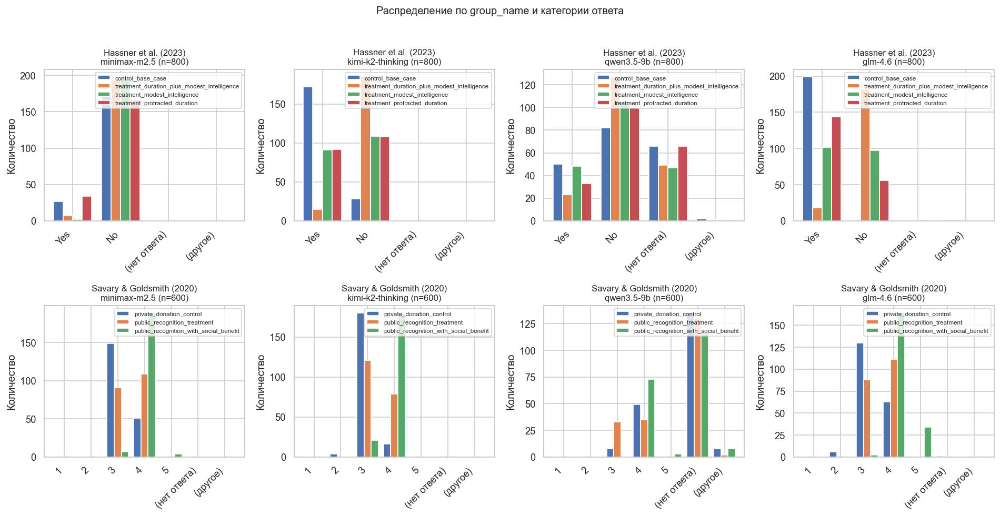

In [56]:
# === Grouped bar charts: experiment (rows) × model (cols), hue = group_name ===
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional: keep only rows from runs whose path contains this substring (e.g. "no_incentive")
# Set to None to use all loaded data.
SOURCE_SUBSTRING = None  # e.g. "no_incentive"

if 'all_df' in globals():
    _plot_df = all_df.copy()
elif 'df' in globals():
    _plot_df = df.copy()
else:
    raise ValueError('Need `all_df` or `df` — run the data-loading cell first.')

if SOURCE_SUBSTRING and 'source_file' in _plot_df.columns:
    _plot_df = _plot_df[_plot_df['source_file'].astype(str).str.contains(SOURCE_SUBSTRING, na=False)].copy()

# --- Normalize final answer to display categories (как на примере: Yes/No или 1–5) ---
from pathlib import Path


def _first_digit(txt: str):
    """Prefer a standalone digit / leading digit on first line (как типичный ответ модели)."""
    if not txt or not str(txt).strip():
        return None
    first_line = str(txt).strip().split('\n')[0].strip()
    m = re.match(r'^(\d)\s*$', first_line)
    if m:
        return int(m.group(1))
    m2 = re.match(r'^\s*(\d)\b', first_line)
    if m2:
        return int(m2.group(1))
    return None


def normalize_answer_category(row):
    exp = str(row.get('experiment_name', ''))
    txt = str(row.get('final_answer_text', '')).strip()
    low = txt.lower()

    if not txt or low in ('nan', 'none', 'null'):
        return '(нет ответа)'

    if 'hassner' in exp.lower():
        if re.search(r'\byes\b', low) and 'not' not in low[:80]:
            return 'Yes'
        if re.search(r'\bno\b', low):
            return 'No'
        d = _first_digit(txt)
        if d == 1:
            return 'Yes'
        if d == 2:
            return 'No'
        return '(другое)'

    if 'savary' in exp.lower() or 'goldsmith' in exp.lower():
        d = _first_digit(txt)
        if d is not None and 1 <= d <= 5:
            return str(d)
        return '(другое)'

    d = _first_digit(txt)
    if d is not None:
        return str(d)
    return '(другое)'


_plot_df = _plot_df.copy()
_plot_df['answer_cat'] = _plot_df.apply(normalize_answer_category, axis=1)

# Experiment / model order (2 × 4 как на фото)
experiments = sorted(_plot_df['experiment_name'].dropna().unique())
models = sorted(_plot_df['model'].dropna().unique())

if len(experiments) > 2:
    print('Warning: unique experiments > 2, using first 2 alphabetically:', experiments[:2])
    experiments = experiments[:2]
if len(models) > 4:
    print('Warning: unique models > 4, using first 4 alphabetically:', models[:4])
    models = models[:4]

# Category order on x-axis
def x_order_for_exp(exp_name: str):
    if 'hassner' in str(exp_name).lower():
        return ['Yes', 'No', '(нет ответа)', '(другое)']
    return ['1', '2', '3', '4', '5', '(нет ответа)', '(другое)']


def short_exp_title(name):
    s = str(name)
    if 'Hassner' in s:
        return 'Hassner et al. (2023)'
    if 'Savary' in s or 'Goldsmith' in s:
        return 'Savary & Goldsmith (2020)'
    return s[:50]


def short_model(m):
    m = str(m)
    return m.split('/')[-1] if '/' in m else m


fig, axes = plt.subplots(len(experiments), len(models), figsize=(4 * len(models), 4 * len(experiments)), squeeze=False)

for i, exp in enumerate(experiments):
    x_order = x_order_for_exp(exp)
    for j, model in enumerate(models):
        ax = axes[i][j]
        sub = _plot_df[(_plot_df['experiment_name'] == exp) & (_plot_df['model'] == model)]
        n_sub = len(sub)

        if n_sub == 0:
            ax.set_visible(False)
            continue

        groups = sorted(sub['group_name'].dropna().astype(str).unique())
        # counts[answer][group]
        counts = (
            sub.groupby(['answer_cat', 'group_name'], dropna=False)
            .size()
            .unstack(fill_value=0)
        )

        x = np.arange(len(x_order))
        n_g = max(len(groups), 1)
        width = 0.8 / n_g
        for gi, g in enumerate(groups):
            vals = []
            for a in x_order:
                try:
                    vals.append(int(counts.loc[a, g]) if a in counts.index and g in counts.columns else 0)
                except Exception:
                    vals.append(0)
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(x + offset, vals, width=width, label=g)

        ax.set_xticks(x)
        ax.set_xticklabels(x_order, rotation=45, ha='right')
        ax.set_ylabel('Количество')
        ax.set_title(f'{short_exp_title(exp)}\n{short_model(model)} (n={n_sub})', fontsize=10)
        ax.legend(fontsize=7, loc='upper right')

plt.suptitle(
    'Распределение по group_name и категории ответа'
    + (f' — filter source_file contains "{SOURCE_SUBSTRING}"' if SOURCE_SUBSTRING else ''),
    fontsize=12,
    y=1.02,
)
plt.tight_layout()
plt.show()
